# Integrating Landsat and ERA5-Land for Machine Learning-Based Surface Heat Modelling Around Zayed International Airport, Abu Dhabi

Code accompanying the paper by **Femina Anzil and Zainab Rasheed** (Emirates Aviation University).

The notebook builds the integrated Landsat 8–9 / ERA5-Land dataset for June–September 2021–2025 (560 observations = 40 acquisition dates × 14 ERA5-Land 0.1° grid cells) and evaluates Linear Regression, Random Forest, Gradient Boosting and XGBoost with date-grouped cross-validation, a 2025 temporal hold-out and spatial-group cross-validation.

**Environment:** Google Colab. The data are expected in Google Drive under `MyDrive/Abudhabi Airport Heat surrounding/` (with its `ERA5` sub-folder and the Landsat exports).

**Workflow**
1. ERA5-Land preparation, June–July 2021
2. Landsat metadata and exact acquisition times
3. Landsat–ERA5 integration, June–July 2021
4. August–September 2021 and the full 2021 hot season
5. Landsat and ERA5-Land processing, 2022–2025
6. Final 2021–2025 dataset
7. Exploratory analysis and statistical tests
8. Machine-learning comparison with date-grouped cross-validation
9. Spatial-group cross-validation
10. Temporal hold-out validation (train 2021–2024, test 2025)
11. Error analysis, interpretation and extreme-heat performance
12. Paper figures at 300 dpi
13. Additional analyses: errors by predicted LST, prediction intervals, area of applicability
14. Software versions

In [1]:
# ============================================================
# SETUP (Google Colab)
# ============================================================
!pip install -q shap contextily

from google.colab import drive
drive.mount("/content/drive")

import os
import warnings
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

PROJECT_DIR = "/content/drive/MyDrive/Abudhabi Airport Heat surrounding"
print("Project folder found:", os.path.isdir(PROJECT_DIR))

Mounted at /content/drive
Project folder found: True


## 1. ERA5-Land preparation — June–July 2021
Load the hourly ERA5-Land files, convert units, derive relative humidity (Magnus approximation), wind speed and daily solar radiation, and remove grid cells with missing data.

In [2]:
folder = "/content/drive/MyDrive/Abudhabi Airport Heat surrounding/ERA5"

print(os.listdir(folder))

['5e621decbe01762b57e9547799886459.nc', 'ccd38f59768a318fc71f83c28c98547b.nc', 'September.nc', 'August.nc', '2022June.nc', '2022July.nc', '2022August.nc', '2022September.nc', '2023September.nc', '2023August.nc', '2023July.nc', '2023 June.nc', '2024 September.nc', '2024August.nc', '2024July.nc', '2024June.nc', '2025september.nc', '2025August.nc', '2025 july.nc', '2025June.nc', 'ERA5_2022_2025_June_September_Clean.csv', 'ERA5_2021_June_July_LandsatMatched.csv', 'ERA5_2021_June_July_Clean.csv', 'Combined_ERA5_Landsat_2021_June_July.csv', 'Final_ERA5_Landsat_2021_June_July.csv', 'ERA5_2021_August_September_LandsatMatched.csv', 'ERA5_2021_August_September_Clean.csv', 'Final_ERA5_Landsat_2021_August_September.csv', 'Final_ERA5_Landsat_2021_June_September.csv', 'ERA5_2022_June_September_Clean.csv', 'ERA5_2023_June_September_Clean.csv', 'ERA5_2024_June_September_Clean.csv', 'ERA5_2025_June_September_Clean.csv', 'Final_ERA5_Landsat_2022_June_September.csv', 'Final_ERA5_Landsat_2023_June_Septemb

In [3]:
import xarray as xr
import os

folder = "/content/drive/MyDrive/Abudhabi Airport Heat surrounding/ERA5"

nc_files = [
    f for f in os.listdir(folder)
    if f.endswith(".nc")
]

for file in nc_files:
    path = os.path.join(folder, file)

    ds = xr.open_dataset(path)

    print("\nFILE:", file)
    print("Dimensions:", ds.dims)
    print("Variables:", list(ds.data_vars))
    print("Coordinates:", list(ds.coords))

    # Find the time coordinate
    for coord in ds.coords:
        if "time" in coord.lower():
            print("Time coordinate:", coord)
            print("Start:", ds[coord].values[0])
            print("End:", ds[coord].values[-1])

    ds.close()


FILE: 5e621decbe01762b57e9547799886459.nc
Dimensions: FrozenMappingWarningOnValuesAccess({'valid_time': 744, 'latitude': 5, 'longitude': 6})
Variables: ['d2m', 't2m', 'ssrd', 'u10', 'v10', 'tp']
Coordinates: ['number', 'valid_time', 'latitude', 'longitude', 'expver']
Time coordinate: valid_time
Start: 2021-07-01T00:00:00.000000000
End: 2021-07-31T23:00:00.000000000

FILE: ccd38f59768a318fc71f83c28c98547b.nc
Dimensions: FrozenMappingWarningOnValuesAccess({'valid_time': 720, 'latitude': 5, 'longitude': 6})
Variables: ['d2m', 't2m', 'ssrd', 'u10', 'v10', 'tp']
Coordinates: ['number', 'valid_time', 'latitude', 'longitude', 'expver']
Time coordinate: valid_time
Start: 2021-06-01T00:00:00.000000000
End: 2021-06-30T23:00:00.000000000

FILE: September.nc
Dimensions: FrozenMappingWarningOnValuesAccess({'valid_time': 720, 'latitude': 5, 'longitude': 6})
Variables: ['d2m', 't2m', 'ssrd', 'u10', 'v10', 'tp']
Coordinates: ['number', 'valid_time', 'latitude', 'longitude', 'expver']
Time coordinate:

In [4]:
import xarray as xr
import numpy as np
import pandas as pd
import os

folder = "/content/drive/MyDrive/Abudhabi Airport Heat surrounding/ERA5"

june_file = os.path.join(
    folder,
    "ccd38f59768a318fc71f83c28c98547b.nc"
)

ds = xr.open_dataset(june_file)

print(ds)

<xarray.Dataset> Size: 536kB
Dimensions:     (valid_time: 720, latitude: 5, longitude: 6)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 6kB 2021-06-01 ... 2021-06-30T23:...
  * latitude    (latitude) float64 40B 24.6 24.5 24.4 24.3 24.2
  * longitude   (longitude) float64 48B 54.4 54.5 54.6 54.7 54.8 54.9
    number      int64 8B ...
    expver      (valid_time) <U4 12kB ...
Data variables:
    d2m         (valid_time, latitude, longitude) float32 86kB ...
    t2m         (valid_time, latitude, longitude) float32 86kB ...
    ssrd        (valid_time, latitude, longitude) float32 86kB ...
    u10         (valid_time, latitude, longitude) float32 86kB ...
    v10         (valid_time, latitude, longitude) float32 86kB ...
    tp          (valid_time, latitude, longitude) float32 86kB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7


In [5]:
# Convert temperatures from Kelvin to Celsius
ds["AirTemp_C"] = ds["t2m"] - 273.15
ds["DewPoint_C"] = ds["d2m"] - 273.15

# Calculate relative humidity using temperature and dew point
T = ds["AirTemp_C"]
Td = ds["DewPoint_C"]

ds["RelativeHumidity"] = (
    100
    * np.exp((17.625 * Td) / (243.04 + Td))
    / np.exp((17.625 * T) / (243.04 + T))
)

# Calculate wind speed
ds["WindSpeed_ms"] = np.sqrt(
    ds["u10"]**2 + ds["v10"]**2
)

# Convert precipitation from metres to millimetres
ds["Precipitation_mm"] = ds["tp"] * 1000

print("Derived variables created.")

Derived variables created.


In [6]:
for var in [
    "AirTemp_C",
    "DewPoint_C",
    "RelativeHumidity",
    "WindSpeed_ms",
    "Precipitation_mm"
]:
    print("\n", var)
    print(ds[var].min().values)
    print(ds[var].mean().values)
    print(ds[var].max().values)


 AirTemp_C
23.164093017578125
34.581077575683594
47.784088134765625

 DewPoint_C
0.998931884765625
20.716455459594727
29.056060791015625

 RelativeHumidity
7.121645450592041
51.73234558105469
100.0003662109375

 WindSpeed_ms
0.06298485398292542
3.824089288711548
9.961116790771484

 Precipitation_mm
0.0
0.001948109595105052
0.04964634031057358


In [7]:
ds["RelativeHumidity"] = ds["RelativeHumidity"].clip(0, 100)

In [8]:
print(ds["ssrd"])
print(ds["ssrd"].attrs)

<xarray.DataArray 'ssrd' (valid_time: 720, latitude: 5, longitude: 6)> Size: 86kB
[21600 values with dtype=float32]
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 6kB 2021-06-01 ... 2021-06-30T23:...
  * latitude    (latitude) float64 40B 24.6 24.5 24.4 24.3 24.2
  * longitude   (longitude) float64 48B 54.4 54.5 54.6 54.7 54.8 54.9
    number      int64 8B ...
    expver      (valid_time) <U4 12kB ...
Attributes: (12/32)
    GRIB_paramId:                             169
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      30
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            accum
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               J m**-2
    long_name:                                Surface short-wave (solar) radi...
    units:                    

In [9]:
print("SSRD min:", ds["ssrd"].min().values)
print("SSRD mean:", ds["ssrd"].mean().values)
print("SSRD max:", ds["ssrd"].max().values)

SSRD min: 0.0
SSRD mean: 18063258.0
SSRD max: 28192524.0


In [10]:
ds["SolarRadiation_Wm2"] = ds["ssrd"] / 3600

In [11]:
print(ds["ssrd"].attrs)

{'GRIB_paramId': np.int64(169), 'GRIB_dataType': 'fc', 'GRIB_numberOfPoints': np.int64(30), 'GRIB_typeOfLevel': 'surface', 'GRIB_stepUnits': np.int64(1), 'GRIB_stepType': 'accum', 'GRIB_gridType': 'regular_ll', 'GRIB_uvRelativeToGrid': np.int64(0), 'GRIB_NV': np.int64(0), 'GRIB_Nx': np.int64(6), 'GRIB_Ny': np.int64(5), 'GRIB_cfName': 'surface_downwelling_shortwave_flux_in_air', 'GRIB_cfVarName': 'ssrd', 'GRIB_gridDefinitionDescription': 'Latitude/Longitude Grid', 'GRIB_iDirectionIncrementInDegrees': np.float64(0.1), 'GRIB_iScansNegatively': np.int64(0), 'GRIB_jDirectionIncrementInDegrees': np.float64(0.1), 'GRIB_jPointsAreConsecutive': np.int64(0), 'GRIB_jScansPositively': np.int64(0), 'GRIB_latitudeOfFirstGridPointInDegrees': np.float64(24.6), 'GRIB_latitudeOfLastGridPointInDegrees': np.float64(24.2), 'GRIB_longitudeOfFirstGridPointInDegrees': np.float64(54.4), 'GRIB_longitudeOfLastGridPointInDegrees': np.float64(54.9), 'GRIB_missingValue': np.float64(3.4028234663852886e+38), 'GRIB_na

In [12]:
solar_test = ds["ssrd"].isel(
    latitude=2,
    longitude=2
).isel(valid_time=slice(0, 24))

for time, value in zip(
    solar_test["valid_time"].values,
    solar_test.values
):
    print(time, value)

2021-06-01T00:00:00.000000000 27706688.0
2021-06-01T01:00:00.000000000 0.0
2021-06-01T02:00:00.000000000 22125.0
2021-06-01T03:00:00.000000000 429799.0
2021-06-01T04:00:00.000000000 1562453.0
2021-06-01T05:00:00.000000000 3478221.0
2021-06-01T06:00:00.000000000 6092730.0
2021-06-01T07:00:00.000000000 9259960.0
2021-06-01T08:00:00.000000000 12748350.0
2021-06-01T09:00:00.000000000 16310968.0
2021-06-01T10:00:00.000000000 19695168.0
2021-06-01T11:00:00.000000000 22666894.0
2021-06-01T12:00:00.000000000 25034722.0
2021-06-01T13:00:00.000000000 26669296.0
2021-06-01T14:00:00.000000000 27528642.0
2021-06-01T15:00:00.000000000 27741532.0
2021-06-01T16:00:00.000000000 27741660.0
2021-06-01T17:00:00.000000000 27741660.0
2021-06-01T18:00:00.000000000 27741660.0
2021-06-01T19:00:00.000000000 27741660.0
2021-06-01T20:00:00.000000000 27741660.0
2021-06-01T21:00:00.000000000 27741660.0
2021-06-01T22:00:00.000000000 27741660.0
2021-06-01T23:00:00.000000000 27741660.0


In [13]:
# ======================================================
# Calculate hourly solar radiation from accumulated SSRD
# ======================================================

ssrd = ds["ssrd"]

# Difference between consecutive hours
ssrd_diff = ssrd.diff("valid_time")

# Restore the time dimension
ssrd_diff = ssrd_diff.reindex(
    valid_time=ds.valid_time,
    fill_value=0
)

# When accumulation resets, difference becomes negative.
# At/after reset, use the current accumulated value instead.
ssrd_hourly = xr.where(
    ssrd_diff < 0,
    ssrd,
    ssrd_diff
)

# Convert J/m² over one hour to mean W/m²
ds["SolarRadiation_Wm2"] = ssrd_hourly / 3600

print("Hourly solar radiation created.")

print(
    "Min:",
    float(ds["SolarRadiation_Wm2"].min())
)

print(
    "Mean:",
    float(ds["SolarRadiation_Wm2"].mean())
)

print(
    "Max:",
    float(ds["SolarRadiation_Wm2"].max())
)

Hourly solar radiation created.
Min: 0.0
Mean: 337.6413269042969
Max: 7803.39453125


In [14]:
# ======================================================
# DAILY SOLAR RADIATION
# Convert accumulated SSRD to MJ/m²/day
# ======================================================

# Create date coordinate
dates = ds["valid_time"].dt.floor("D")

# Maximum accumulated SSRD for each day
# represents approximately the daily total
daily_ssrd = ds["ssrd"].groupby(dates).max()

# Convert J/m² to MJ/m²
daily_solar = daily_ssrd / 1_000_000

daily_solar.name = "SolarRadiation_MJm2_day"

print("Daily solar radiation created.")

print("Min:", float(daily_solar.min()))
print("Mean:", float(daily_solar.mean()))
print("Max:", float(daily_solar.max()))

Daily solar radiation created.
Min: 25.365768432617188
Mean: 27.092662811279297
Max: 28.192523956298828


### Create the June 2021 ERA5-Land dataframe

In [15]:
# ======================================================
# CREATE JUNE 2021 ERA5 DATAFRAME
# ======================================================

# Keep required variables
june_df = ds[
    [
        "AirTemp_C",
        "RelativeHumidity",
        "WindSpeed_ms",
        "Precipitation_mm"
    ]
].to_dataframe().reset_index()

# Keep useful columns only
june_df = june_df[
    [
        "valid_time",
        "latitude",
        "longitude",
        "AirTemp_C",
        "RelativeHumidity",
        "WindSpeed_ms",
        "Precipitation_mm"
    ]
]

# Add date
june_df["Date"] = pd.to_datetime(
    june_df["valid_time"]
).dt.date

# Round unnecessary floating precision
june_df["AirTemp_C"] = june_df["AirTemp_C"].round(2)
june_df["RelativeHumidity"] = june_df["RelativeHumidity"].round(2)
june_df["WindSpeed_ms"] = june_df["WindSpeed_ms"].round(2)
june_df["Precipitation_mm"] = june_df["Precipitation_mm"].round(4)

print("Shape:", june_df.shape)

print("\nFirst 10 rows:")
display(june_df.head(10))

print("\nMissing values:")
print(june_df.isnull().sum())

Shape: (21600, 8)

First 10 rows:


,valid_time,latitude,longitude,AirTemp_C,RelativeHumidity,WindSpeed_ms,Precipitation_mm,Date
0,2021-06-01,24.6,54.4,NaN,NaN,NaN,NaN,2021-06-01
1,2021-06-01,24.6,54.5,NaN,NaN,NaN,NaN,2021-06-01
2,2021-06-01,24.6,54.6,NaN,NaN,NaN,NaN,2021-06-01
3,2021-06-01,24.6,54.7,25.320000,89.720001,2.68,0.0,2021-06-01
4,2021-06-01,24.6,54.8,25.780001,85.139999,2.91,0.0,2021-06-01
5,2021-06-01,24.6,54.9,25.690001,79.529999,3.17,0.0,2021-06-01
6,2021-06-01,24.5,54.4,27.330000,89.510002,2.36,0.0,2021-06-01
7,2021-06-01,24.5,54.5,26.830000,90.269997,2.31,0.0,2021-06-01
8,2021-06-01,24.5,54.6,26.820000,89.650002,2.49,0.0,2021-06-01
9,2021-06-01,24.5,54.7,25.900000,87.620003,2.73,0.0,2021-06-01



Missing values:
valid_time             0
latitude               0
longitude              0
AirTemp_C           2880
RelativeHumidity    2880
WindSpeed_ms        2880
Precipitation_mm    2880
Date                   0
dtype: int64


In [16]:
# ======================================================
# IDENTIFY GRID CELLS WITH MISSING ERA5-LAND DATA
# ======================================================

missing_grid = (
    june_df[
        june_df["AirTemp_C"].isna()
    ][["latitude", "longitude"]]
    .drop_duplicates()
    .sort_values(["latitude", "longitude"])
    .reset_index(drop=True)
)

print("Grid cells with missing data:")
display(missing_grid)

print("\nNumber of missing grid cells:", len(missing_grid))

Grid cells with missing data:


,latitude,longitude
0,24.4,54.4
1,24.6,54.4
2,24.6,54.5
3,24.6,54.6



Number of missing grid cells: 4


### Create the clean June dataset

In [17]:
# Remove rows where ERA5-Land variables are unavailable

june_clean = june_df.dropna(
    subset=[
        "AirTemp_C",
        "RelativeHumidity",
        "WindSpeed_ms",
        "Precipitation_mm"
    ]
).copy()

print("Original rows:", len(june_df))
print("Clean rows:", len(june_clean))

print("\nRemaining missing values:")
print(june_clean.isnull().sum())

Original rows: 21600
Clean rows: 18720

Remaining missing values:
valid_time          0
latitude            0
longitude           0
AirTemp_C           0
RelativeHumidity    0
WindSpeed_ms        0
Precipitation_mm    0
Date                0
dtype: int64


In [18]:
# ======================================================
# ADD DAILY SOLAR RADIATION TO JUNE CLEAN DATA
# ======================================================

# Convert daily solar xarray object to dataframe
solar_df = (
    daily_solar
    .to_dataframe()
    .reset_index()
)

print("Solar dataframe columns:")
print(solar_df.columns)

print("\nSolar dataframe shape:")
print(solar_df.shape)

display(solar_df.head())

Solar dataframe columns:
Index(['floor', 'latitude', 'longitude', 'number', 'SolarRadiation_MJm2_day'], dtype='object')

Solar dataframe shape:
(900, 5)


,floor,latitude,longitude,number,SolarRadiation_MJm2_day
0,2021-06-01,24.6,54.4,0,NaN
1,2021-06-01,24.6,54.5,0,NaN
2,2021-06-01,24.6,54.6,0,NaN
3,2021-06-01,24.6,54.7,0,27.782604
4,2021-06-01,24.6,54.8,0,27.997965


In [19]:
# ======================================================
# MERGE DAILY SOLAR RADIATION INTO JUNE CLEAN DATA
# ======================================================

solar_merge = solar_df[
    [
        "floor",
        "latitude",
        "longitude",
        "SolarRadiation_MJm2_day"
    ]
].copy()

# Rename date column
solar_merge = solar_merge.rename(
    columns={"floor": "Date"}
)

# Make sure Date types match
solar_merge["Date"] = pd.to_datetime(
    solar_merge["Date"]
).dt.date

june_clean["Date"] = pd.to_datetime(
    june_clean["Date"]
).dt.date

# Merge
june_final = june_clean.merge(
    solar_merge,
    on=[
        "Date",
        "latitude",
        "longitude"
    ],
    how="left"
)

print("Final shape:", june_final.shape)

print("\nMissing values:")
print(june_final.isnull().sum())

display(june_final.head(10))

Final shape: (18720, 9)

Missing values:
valid_time                 0
latitude                   0
longitude                  0
AirTemp_C                  0
RelativeHumidity           0
WindSpeed_ms               0
Precipitation_mm           0
Date                       0
SolarRadiation_MJm2_day    0
dtype: int64


,valid_time,latitude,longitude,AirTemp_C,RelativeHumidity,WindSpeed_ms,Precipitation_mm,Date,SolarRadiation_MJm2_day
0,2021-06-01,24.6,54.7,25.320000,89.720001,2.68,0.0,2021-06-01,27.782604
1,2021-06-01,24.6,54.8,25.780001,85.139999,2.91,0.0,2021-06-01,27.997965
2,2021-06-01,24.6,54.9,25.690001,79.529999,3.17,0.0,2021-06-01,28.177736
3,2021-06-01,24.5,54.4,27.330000,89.510002,2.36,0.0,2021-06-01,27.327375
4,2021-06-01,24.5,54.5,26.830000,90.269997,2.31,0.0,2021-06-01,27.440943
5,2021-06-01,24.5,54.6,26.820000,89.650002,2.49,0.0,2021-06-01,27.639099
6,2021-06-01,24.5,54.7,25.900000,87.620003,2.73,0.0,2021-06-01,27.851109
7,2021-06-01,24.5,54.8,25.719999,82.449997,2.98,0.0,2021-06-01,28.062332
8,2021-06-01,24.5,54.9,25.830000,76.430000,3.10,0.0,2021-06-01,28.192524
9,2021-06-01,24.4,54.5,27.370001,87.519997,2.31,0.0,2021-06-01,27.584978


In [20]:
# ======================================================
# JULY 2021 ERA5 PROCESSING
# ======================================================

import xarray as xr
import numpy as np
import pandas as pd
import os

folder = "/content/drive/MyDrive/Abudhabi Airport Heat surrounding/ERA5"

july_file = os.path.join(
    folder,
    "5e621decbe01762b57e9547799886459.nc"
)

ds_july = xr.open_dataset(july_file)

# ------------------------------------------------------
# Temperature conversions
# ------------------------------------------------------

ds_july["AirTemp_C"] = ds_july["t2m"] - 273.15
ds_july["DewPoint_C"] = ds_july["d2m"] - 273.15

# ------------------------------------------------------
# Relative humidity
# ------------------------------------------------------

T = ds_july["AirTemp_C"]
Td = ds_july["DewPoint_C"]

ds_july["RelativeHumidity"] = (
    100
    * np.exp((17.625 * Td) / (243.04 + Td))
    / np.exp((17.625 * T) / (243.04 + T))
)

ds_july["RelativeHumidity"] = (
    ds_july["RelativeHumidity"].clip(0, 100)
)

# ------------------------------------------------------
# Wind speed
# ------------------------------------------------------

ds_july["WindSpeed_ms"] = np.sqrt(
    ds_july["u10"]**2 + ds_july["v10"]**2
)

# ------------------------------------------------------
# Precipitation
# ------------------------------------------------------

ds_july["Precipitation_mm"] = ds_july["tp"] * 1000

# ------------------------------------------------------
# Daily solar radiation
# ------------------------------------------------------

july_dates = ds_july["valid_time"].dt.floor("D")

july_daily_ssrd = (
    ds_july["ssrd"]
    .groupby(july_dates)
    .max()
)

july_daily_solar = july_daily_ssrd / 1_000_000

july_daily_solar.name = "SolarRadiation_MJm2_day"

print("July derived variables created.")

July derived variables created.


In [21]:
# ======================================================
# JULY HOURLY DATAFRAME
# ======================================================

july_df = ds_july[
    [
        "AirTemp_C",
        "RelativeHumidity",
        "WindSpeed_ms",
        "Precipitation_mm"
    ]
].to_dataframe().reset_index()

july_df = july_df[
    [
        "valid_time",
        "latitude",
        "longitude",
        "AirTemp_C",
        "RelativeHumidity",
        "WindSpeed_ms",
        "Precipitation_mm"
    ]
]

july_df["Date"] = pd.to_datetime(
    july_df["valid_time"]
).dt.date

# Remove invalid ERA5-Land cells
july_clean = july_df.dropna(
    subset=[
        "AirTemp_C",
        "RelativeHumidity",
        "WindSpeed_ms",
        "Precipitation_mm"
    ]
).copy()

print("July original rows:", len(july_df))
print("July clean rows:", len(july_clean))

print("\nMissing values:")
print(july_clean.isnull().sum())

July original rows: 22320
July clean rows: 19344

Missing values:
valid_time          0
latitude            0
longitude           0
AirTemp_C           0
RelativeHumidity    0
WindSpeed_ms        0
Precipitation_mm    0
Date                0
dtype: int64


### Merge daily solar radiation for July

In [22]:
july_solar_df = (
    july_daily_solar
    .to_dataframe()
    .reset_index()
)

july_solar_merge = july_solar_df[
    [
        "floor",
        "latitude",
        "longitude",
        "SolarRadiation_MJm2_day"
    ]
].copy()

july_solar_merge = july_solar_merge.rename(
    columns={"floor": "Date"}
)

july_solar_merge["Date"] = pd.to_datetime(
    july_solar_merge["Date"]
).dt.date

july_clean["Date"] = pd.to_datetime(
    july_clean["Date"]
).dt.date

july_final = july_clean.merge(
    july_solar_merge,
    on=[
        "Date",
        "latitude",
        "longitude"
    ],
    how="left"
)

print("July final shape:", july_final.shape)

print("\nMissing values:")
print(july_final.isnull().sum())

July final shape: (19344, 9)

Missing values:
valid_time                 0
latitude                   0
longitude                  0
AirTemp_C                  0
RelativeHumidity           0
WindSpeed_ms               0
Precipitation_mm           0
Date                       0
SolarRadiation_MJm2_day    0
dtype: int64


In [23]:
# Combine June and July
era5_2021_jun_jul = pd.concat(
    [june_final, july_final],
    ignore_index=True
)

# Sort chronologically and spatially
era5_2021_jun_jul = era5_2021_jun_jul.sort_values(
    ["valid_time", "latitude", "longitude"]
).reset_index(drop=True)

print("Combined shape:", era5_2021_jun_jul.shape)
print("Start date:", era5_2021_jun_jul["Date"].min())
print("End date:", era5_2021_jun_jul["Date"].max())

print("\nMissing values:")
print(era5_2021_jun_jul.isnull().sum())

Combined shape: (38064, 9)
Start date: 2021-06-01
End date: 2021-07-31

Missing values:
valid_time                 0
latitude                   0
longitude                  0
AirTemp_C                  0
RelativeHumidity           0
WindSpeed_ms               0
Precipitation_mm           0
Date                       0
SolarRadiation_MJm2_day    0
dtype: int64


In [24]:
output_file = (
    "/content/drive/MyDrive/Abudhabi Airport Heat surrounding/ERA5/"
    "ERA5_2021_June_July_Clean.csv"
)

era5_2021_jun_jul.to_csv(
    output_file,
    index=False
)

print("Saved to:")
print(output_file)

Saved to:
/content/drive/MyDrive/Abudhabi Airport Heat surrounding/ERA5/ERA5_2021_June_July_Clean.csv


## 2. Landsat metadata and exact acquisition times
Read the USGS Landsat Collection 2 Level-2 metadata and interpolate ERA5-Land variables to each exact acquisition time.

In [25]:
# ============================================================
# LANDSAT METADATA - READ DIRECTLY FROM ZIP IN GOOGLE DRIVE
# UAE AIRPORT HEAT STUDY
# ============================================================

import pandas as pd
import zipfile
import os


# ------------------------------------------------------------
# 1. PATH TO ORIGINAL USGS LANDSAT ZIP
# ------------------------------------------------------------

landsat_zip = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding/"
    "Landsat/"
    "landsat_ot_c2_l2_6a8b3a88d3f3a223.zip"
)

print("ZIP exists:", os.path.exists(landsat_zip))


# ------------------------------------------------------------
# 2. OPEN ZIP AND FIND CSV FILE
# ------------------------------------------------------------

with zipfile.ZipFile(landsat_zip, "r") as z:

    print("\nFiles inside ZIP:")
    print(z.namelist())

    csv_files = [
        f for f in z.namelist()
        if f.lower().endswith(".csv")
    ]

    if len(csv_files) == 0:
        raise ValueError("No CSV file found inside the ZIP.")

    csv_name = csv_files[0]

    print("\nUsing CSV:")
    print(csv_name)

    # Read CSV directly without extracting
    with z.open(csv_name) as file:
        landsat_raw = pd.read_csv(
            file,
            encoding="latin1"
        )


# ------------------------------------------------------------
# 3. BASIC CHECK
# ------------------------------------------------------------

print("\nOriginal metadata shape:")
print(landsat_raw.shape)

print("\nFirst columns:")
print(landsat_raw.columns[:15].tolist())


# ------------------------------------------------------------
# 4. PREPARE DATE AND CLOUD VARIABLES
# ------------------------------------------------------------

landsat_raw["Date"] = pd.to_datetime(
    landsat_raw["Date Acquired"]
)

landsat_raw["Year"] = landsat_raw["Date"].dt.year
landsat_raw["Month"] = landsat_raw["Date"].dt.month

landsat_raw["Land Cloud Cover"] = pd.to_numeric(
    landsat_raw["Land Cloud Cover"],
    errors="coerce"
)

landsat_raw["Scene Cloud Cover L1"] = pd.to_numeric(
    landsat_raw["Scene Cloud Cover L1"],
    errors="coerce"
)


# ------------------------------------------------------------
# 5. FILTER ELIGIBLE LANDSAT SCENES
#
# Years: 2021-2025
# Months: June-September
# Path 160 / Row 043
# Tier 1
# Level-2 Surface Reflectance + Surface Temperature
# ------------------------------------------------------------

eligible = landsat_raw[
    landsat_raw["Year"].between(2021, 2025)
    &
    landsat_raw["Month"].isin([6, 7, 8, 9])
    &
    (landsat_raw["WRS Path"] == 160)
    &
    (landsat_raw["WRS Row"] == 43)
    &
    (landsat_raw["Collection Category"] == "T1")
    &
    (landsat_raw["Data Type L2"] == "OLI_TIRS_L2SP")
].copy()

print("\nEligible hot-season scenes:")
print(len(eligible))


# ------------------------------------------------------------
# 6. SELECT 2 BEST SCENES PER MONTH PER YEAR
#
# Lowest land cloud cover first
# ------------------------------------------------------------

landsat_40 = (
    eligible
    .sort_values(
        [
            "Year",
            "Month",
            "Land Cloud Cover",
            "Scene Cloud Cover L1",
            "Date"
        ]
    )
    .groupby(
        ["Year", "Month"],
        group_keys=False
    )
    .head(2)
    .sort_values("Date")
    .reset_index(drop=True)
)

print("\nFinal number of selected scenes:")
print(len(landsat_40))


# ------------------------------------------------------------
# 7. CHECK BALANCE
# ------------------------------------------------------------

print("\nScenes by year and month:")

print(
    landsat_40
    .groupby(["Year", "Month"])
    .size()
    .unstack(fill_value=0)
)


# ------------------------------------------------------------
# 8. SELECT ONLY JUNE + JULY 2021
# ------------------------------------------------------------

landsat_2021_junjul = landsat_40[
    (landsat_40["Year"] == 2021)
    &
    (landsat_40["Month"].isin([6, 7]))
].copy()


# ------------------------------------------------------------
# 9. DISPLAY THE 4 LANDSAT SCENES
# ------------------------------------------------------------

columns_to_show = [
    "Date Acquired",
    "Satellite",
    "Land Cloud Cover",
    "Scene Cloud Cover L1",
    "Display ID",
    "Landsat Product Identifier L2"
]

print("\nSelected June-July 2021 Landsat scenes:")

display(
    landsat_2021_junjul[
        columns_to_show
    ].reset_index(drop=True)
)


# ------------------------------------------------------------
# 10. PRINT ONLY THE 4 DATES
# ------------------------------------------------------------

selected_dates = (
    landsat_2021_junjul["Date"]
    .dt.strftime("%Y-%m-%d")
    .tolist()
)

print("\nLandsat acquisition dates:")
for date in selected_dates:
    print(date)

ZIP exists: True

Files inside ZIP:
['landsat_ot_c2_l2_6a8b3a88d3f3a223.csv']

Using CSV:
landsat_ot_c2_l2_6a8b3a88d3f3a223.csv

Original metadata shape:
(187, 58)

First columns:
['Landsat Product Identifier L2', 'Landsat Product Identifier L1', 'Landsat Scene Identifier', 'Date Acquired', 'Collection Category', 'Collection Number', 'WRS Path', 'WRS Row', 'Target WRS Path', 'Target WRS Row', 'Nadir/Off Nadir', 'Roll Angle', 'Date Product Generated L2', 'Date Product Generated L1', 'Start Time']

Eligible hot-season scenes:
70

Final number of selected scenes:
40

Scenes by year and month:
Month  6  7  8  9
Year             
2021   2  2  2  2
2022   2  2  2  2
2023   2  2  2  2
2024   2  2  2  2
2025   2  2  2  2

Selected June-July 2021 Landsat scenes:


,Date Acquired,Satellite,Land Cloud Cover,Scene Cloud Cover L1,Display ID,Landsat Product Identifier L2
0,2021/06/06,8,0.69,0.54,LC08_L2SP_160043_20210606_20210615_02_T1,LC08_L2SP_160043_20210606_20210615_02_T1
1,2021/06/22,8,0.00,0.00,LC08_L2SP_160043_20210622_20210630_02_T1,LC08_L2SP_160043_20210622_20210630_02_T1
2,2021/07/08,8,0.00,0.00,LC08_L2SP_160043_20210708_20210713_02_T1,LC08_L2SP_160043_20210708_20210713_02_T1
3,2021/07/24,8,0.00,0.00,LC08_L2SP_160043_20210724_20210730_02_T1,LC08_L2SP_160043_20210724_20210730_02_T1



Landsat acquisition dates:
2021-06-06
2021-06-22
2021-07-08
2021-07-24


### Check Landsat acquisition times

In [26]:
# ============================================================
# CHECK EXACT LANDSAT ACQUISITION TIMES
# ============================================================

time_check = landsat_2021_junjul[
    [
        "Date Acquired",
        "Start Time",
        "Stop Time",
        "Display ID"
    ]
].copy()

display(time_check)

,Date Acquired,Start Time,Stop Time,Display ID
0,2021/06/06,2021-06-06 06:46:05.260756,2021-06-06 06:46:37.030755,LC08_L2SP_160043_20210606_20210615_02_T1
1,2021/06/22,2021-06-22 06:46:10.430944,2021-06-22 06:46:42.200943,LC08_L2SP_160043_20210622_20210630_02_T1
2,2021/07/08,2021-07-08 06:46:12.74337,2021-07-08 06:46:44.513369,LC08_L2SP_160043_20210708_20210713_02_T1
3,2021/07/24,2021-07-24 06:46:17.872651,2021-07-24 06:46:49.64265,LC08_L2SP_160043_20210724_20210730_02_T1


In [27]:
import pandas as pd
import numpy as np

# ============================================================
# 1. LOAD CLEAN ERA5 JUNE-JULY 2021 DATA
# ============================================================

era5_file = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding/"
    "ERA5/"
    "ERA5_2021_June_July_Clean.csv"
)

era5 = pd.read_csv(era5_file)

era5["valid_time"] = pd.to_datetime(era5["valid_time"])

# ============================================================
# 2. LANDSAT OVERPASS DATES AND TIMES
# ============================================================

landsat_times = pd.DataFrame({
    "Date": pd.to_datetime([
        "2021-06-06",
        "2021-06-22",
        "2021-07-08",
        "2021-07-24"
    ]),
    "Landsat_time_UTC": [
        "06:46:05",
        "06:46:10",
        "06:46:12",
        "06:46:17"
    ]
})

display(landsat_times)

,Date,Landsat_time_UTC
0,2021-06-06,06:46:05
1,2021-06-22,06:46:10
2,2021-07-08,06:46:12
3,2021-07-24,06:46:17


In [28]:
# ============================================================
# 3. TEMPORAL INTERPOLATION TO LANDSAT OVERPASS TIME
# ============================================================

results = []

for _, row in landsat_times.iterrows():

    date = row["Date"]

    # Approximate fraction between 06:00 and 07:00
    # Landsat is around 06:46 UTC
    weight = 46 / 60

    t06 = date + pd.Timedelta(hours=6)
    t07 = date + pd.Timedelta(hours=7)

    df06 = era5[era5["valid_time"] == t06].copy()
    df07 = era5[era5["valid_time"] == t07].copy()

    merged = df06.merge(
        df07,
        on=["latitude", "longitude"],
        suffixes=("_06", "_07")
    )

    out = pd.DataFrame()

    out["Date"] = date.date()
    out["latitude"] = merged["latitude"]
    out["longitude"] = merged["longitude"]

    for var in [
        "AirTemp_C",
        "RelativeHumidity",
        "WindSpeed_ms",
        "Precipitation_mm"
    ]:
        out[var] = (
            merged[f"{var}_06"] * (1 - weight)
            +
            merged[f"{var}_07"] * weight
        )

    # Daily solar radiation does not need hourly interpolation
    out["SolarRadiation_MJm2_day"] = (
        merged["SolarRadiation_MJm2_day_06"]
    )

    results.append(out)

era5_landsat_time = pd.concat(
    results,
    ignore_index=True
)

print("Final matched shape:")
print(era5_landsat_time.shape)

display(era5_landsat_time.head(10))

Final matched shape:
(104, 8)


,Date,latitude,longitude,AirTemp_C,RelativeHumidity,WindSpeed_ms,Precipitation_mm,SolarRadiation_MJm2_day
0,NaN,24.2,54.4,38.285000,36.742000,2.521000,0.0078,27.349644
1,NaN,24.2,54.5,38.530333,36.192667,2.611333,0.0105,27.360107
2,NaN,24.2,54.6,38.666667,35.534000,2.604000,0.0117,27.318855
3,NaN,24.2,54.7,38.871000,35.242667,2.629333,0.0104,27.315660
4,NaN,24.2,54.8,39.032333,34.961333,2.658667,0.0122,27.350464
5,NaN,24.2,54.9,39.291000,33.973667,2.689000,0.0140,27.414060
6,NaN,24.3,54.4,38.586000,36.521667,2.564000,0.0069,27.226520
7,NaN,24.3,54.5,38.674000,36.771333,2.640667,0.0101,27.239307
8,NaN,24.3,54.6,39.023000,35.940333,2.774667,0.0123,27.268080
9,NaN,24.3,54.7,39.206000,35.349000,2.818000,0.0152,27.318453


In [29]:
# ============================================================
# EXACT ERA5 INTERPOLATION TO LANDSAT ACQUISITION TIME
# ============================================================

results = []

# Exact Landsat acquisition times from USGS metadata
landsat_exact_times = pd.to_datetime([
    "2021-06-06 06:46:05.260756",
    "2021-06-22 06:46:10.430944",
    "2021-07-08 06:46:12.743370",
    "2021-07-24 06:46:17.872651"
])

for acquisition_time in landsat_exact_times:

    # Hour before Landsat acquisition
    t_before = acquisition_time.floor("h")

    # Hour after Landsat acquisition
    t_after = t_before + pd.Timedelta(hours=1)

    # Exact interpolation weight
    weight = (
        (acquisition_time - t_before).total_seconds()
        / 3600
    )

    print(
        acquisition_time,
        "Interpolation weight:",
        round(weight, 4)
    )

    # ERA5 at hour before
    df_before = era5[
        era5["valid_time"] == t_before
    ].copy()

    # ERA5 at hour after
    df_after = era5[
        era5["valid_time"] == t_after
    ].copy()

    # Match same spatial grid cells
    merged = df_before.merge(
        df_after,
        on=["latitude", "longitude"],
        suffixes=("_before", "_after")
    )

    # IMPORTANT:
    # preserve merged index correctly
    out = merged[
        ["latitude", "longitude"]
    ].copy()

    # Store exact Landsat information
    out["Date"] = acquisition_time.date()
    out["Landsat_Time_UTC"] = acquisition_time

    # Interpolate hourly meteorological variables
    for var in [
        "AirTemp_C",
        "RelativeHumidity",
        "WindSpeed_ms",
        "Precipitation_mm"
    ]:

        out[var] = (
            merged[f"{var}_before"].to_numpy()
            * (1 - weight)
            +
            merged[f"{var}_after"].to_numpy()
            * weight
        )

    # Daily solar radiation:
    # same daily value, so no interpolation required
    out["SolarRadiation_MJm2_day"] = (
        merged[
            "SolarRadiation_MJm2_day_before"
        ].to_numpy()
    )

    results.append(out)


# ============================================================
# COMBINE ALL FOUR LANDSAT DATES
# ============================================================

era5_landsat_exact = pd.concat(
    results,
    ignore_index=True
)

print("\nFinal shape:", era5_landsat_exact.shape)

print("\nMissing values:")
print(era5_landsat_exact.isnull().sum())

print("\nRows per Landsat date:")
print(
    era5_landsat_exact
    .groupby("Date")
    .size()
)

display(era5_landsat_exact.head(10))

2021-06-06 06:46:05.260756 Interpolation weight: 0.7681
2021-06-22 06:46:10.430944 Interpolation weight: 0.7696
2021-07-08 06:46:12.743370 Interpolation weight: 0.7702
2021-07-24 06:46:17.872651 Interpolation weight: 0.7716

Final shape: (104, 9)

Missing values:
latitude                   0
longitude                  0
Date                       0
Landsat_Time_UTC           0
AirTemp_C                  0
RelativeHumidity           0
WindSpeed_ms               0
Precipitation_mm           0
SolarRadiation_MJm2_day    0
dtype: int64

Rows per Landsat date:
Date
2021-06-06    26
2021-06-22    26
2021-07-08    26
2021-07-24    26
dtype: int64


,latitude,longitude,Date,Landsat_Time_UTC,AirTemp_C,RelativeHumidity,WindSpeed_ms,Precipitation_mm,SolarRadiation_MJm2_day
0,24.2,54.4,2021-06-06,2021-06-06 06:46:05.260756,38.292234,36.710611,2.521745,0.0078,27.349644
1,24.2,54.5,2021-06-06,2021-06-06 06:46:05.260756,38.538034,36.160459,2.612327,0.0105,27.360107
2,24.2,54.6,2021-06-06,2021-06-06 06:46:05.260756,38.674704,35.501471,2.605228,0.0117,27.318855
3,24.2,54.7,2021-06-06,2021-06-06 06:46:05.260756,38.879636,35.208706,2.631028,0.0104,27.315660
4,24.2,54.8,2021-06-06,2021-06-06 06:46:05.260756,39.041525,34.926379,2.660742,0.0122,27.350464
5,24.2,54.9,2021-06-06,2021-06-06 06:46:05.260756,39.300513,33.938259,2.691324,0.0140,27.414060
6,24.3,54.4,2021-06-06,2021-06-06 06:46:05.260756,38.593540,36.490029,2.564789,0.0069,27.226520
7,24.3,54.5,2021-06-06,2021-06-06 06:46:05.260756,38.681803,36.739009,2.641602,0.0101,27.239307
8,24.3,54.6,2021-06-06,2021-06-06 06:46:05.260756,39.031373,35.906825,2.775953,0.0123,27.268080
9,24.3,54.7,2021-06-06,2021-06-06 06:46:05.260756,39.214856,35.314498,2.819578,0.0152,27.318453


In [30]:
output_match = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding/"
    "ERA5/"
    "ERA5_2021_June_July_LandsatMatched.csv"
)

era5_landsat_exact.to_csv(
    output_match,
    index=False
)

print("Saved to:")
print(output_match)

Saved to:
/content/drive/MyDrive/Abudhabi Airport Heat surrounding/ERA5/ERA5_2021_June_July_LandsatMatched.csv


In [31]:
# ============================================================
# EXTRACT LANDSAT ZIP
# UAE AIRPORT HEAT STUDY
# ============================================================

import os
import zipfile
import pandas as pd


# ------------------------------------------------------------
# 1. CORRECT LANDSAT FOLDER PATH
# ------------------------------------------------------------

landsat_folder = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding/"
    "Landsat"
)

print("Landsat folder exists:", os.path.exists(landsat_folder))


# ------------------------------------------------------------
# 2. ZIP FILE PATH
# ------------------------------------------------------------

zip_file = os.path.join(
    landsat_folder,
    "landsat_ot_c2_l2_6a8b3a88d3f3a223.zip"
)

print("ZIP exists:", os.path.exists(zip_file))


# ------------------------------------------------------------
# 3. CHECK ZIP CONTENTS AND EXTRACT
# ------------------------------------------------------------

with zipfile.ZipFile(zip_file, "r") as z:

    print("\nFiles inside ZIP:")

    for name in z.namelist():
        print(name)

    z.extractall(landsat_folder)


# ------------------------------------------------------------
# 4. CHECK LANDSAT FOLDER AFTER EXTRACTION
# ------------------------------------------------------------

print("\nFiles now inside Landsat folder:")

for file in os.listdir(landsat_folder):
    print(file)


# ------------------------------------------------------------
# 5. LOAD EXTRACTED CSV
# ------------------------------------------------------------

csv_file = os.path.join(
    landsat_folder,
    "landsat_ot_c2_l2_6a8b3a88d3f3a223.csv"
)

print("\nCSV exists:", os.path.exists(csv_file))

landsat_metadata = pd.read_csv(
    csv_file,
    encoding="latin1"
)


# ------------------------------------------------------------
# 6. CHECK DATA
# ------------------------------------------------------------

print("\nShape:")
print(landsat_metadata.shape)

print("\nColumns:")
print(landsat_metadata.columns.tolist())

print("\nFirst 5 rows:")
display(landsat_metadata.head())

Landsat folder exists: True
ZIP exists: True

Files inside ZIP:
landsat_ot_c2_l2_6a8b3a88d3f3a223.csv

Files now inside Landsat folder:
landsat_ot_c2_l2_6a8b3a88d3f3a223.zip
Landsat_2021_June_July_UAE_Airport.csv
Landsat_2021_August_September_UAE_Airport.csv
Landsat_2023_June_September_UAE_Airport.csv
Landsat_2025_June_September_UAE_Airport.csv
Landsat_2022_June_September_UAE_Airport.csv
Landsat_2024_June_September_UAE_Airport.csv
Landsat_2022_2025_Exact_Acquisition_Times.csv
landsat_ot_c2_l2_6a8b3a88d3f3a223.csv
Selected_Landsat_Scenes_2022_2025.csv
Landsat_2022_2025_Validation_Summary.csv

CSV exists: True

Shape:
(187, 58)

Columns:
['Landsat Product Identifier L2', 'Landsat Product Identifier L1', 'Landsat Scene Identifier', 'Date Acquired', 'Collection Category', 'Collection Number', 'WRS Path', 'WRS Row', 'Target WRS Path', 'Target WRS Row', 'Nadir/Off Nadir', 'Roll Angle', 'Date Product Generated L2', 'Date Product Generated L1', 'Start Time', 'Stop Time', 'Station Identifier', 

,Landsat Product Identifier L2,Landsat Product Identifier L1,Landsat Scene Identifier,Date Acquired,Collection Category,Collection Number,WRS Path,WRS Row,Target WRS Path,Target WRS Row,...,Corner Upper Left Latitude,Corner Upper Left Longitude,Corner Upper Right Latitude,Corner Upper Right Longitude,Corner Lower Left Latitude,Corner Lower Left Longitude,Corner Lower Right Latitude,Corner Lower Right Longitude,Display ID,Entity ID
0,LC08_L2SP_160043_20210606_20210615_02_T1,LC08_L1TP_160043_20210606_20210615_02_T1,LC81600432021157LGN00,2021/06/06,T1,2,160,43,160,43,...,25.59153,54.02637,25.62023,56.32569,23.47011,54.07597,23.49614,56.33696,LC08_L2SP_160043_20210606_20210615_02_T1,LC81600432021157LGN00
1,LC08_L2SP_160043_20210622_20210630_02_T1,LC08_L1TP_160043_20210622_20210630_02_T1,LC81600432021173LGN00,2021/06/22,T1,2,160,43,160,43,...,25.59171,54.03532,25.62026,56.33166,23.47028,54.08478,23.49616,56.34283,LC08_L2SP_160043_20210622_20210630_02_T1,LC81600432021173LGN00
2,LC08_L2SP_160043_20210708_20210713_02_T1,LC08_L1TP_160043_20210708_20210713_02_T1,LC81600432021189LGN00,2021/07/08,T1,2,160,43,160,43,...,25.59208,54.05322,25.62035,56.35258,23.47061,54.10238,23.49625,56.36340,LC08_L2SP_160043_20210708_20210713_02_T1,LC81600432021189LGN00
3,LC08_L2SP_160043_20210724_20210730_02_T1,LC08_L1TP_160043_20210724_20210730_02_T1,LC81600432021205LGN00,2021/07/24,T1,2,160,43,160,43,...,25.59220,54.05919,25.62036,56.35557,23.47071,54.10825,23.49626,56.36634,LC08_L2SP_160043_20210724_20210730_02_T1,LC81600432021205LGN00
4,LC08_L2SP_160043_20210809_20210819_02_T1,LC08_L1TP_160043_20210809_20210819_02_T1,LC81600432021221LGN00,2021/08/09,T1,2,160,43,160,43,...,25.59208,54.05322,25.62035,56.35258,23.47061,54.10238,23.49625,56.36340,LC08_L2SP_160043_20210809_20210819_02_T1,LC81600432021221LGN00


## 3. Landsat–ERA5 integration — June–July 2021
Load the Earth Engine Landsat export, apply quality checks, assign pixels to ERA5-Land grid cells and build the complete-case dataset.

In [32]:
# ============================================================
# LOAD AND VALIDATE GOOGLE EARTH ENGINE LANDSAT DATA
# June + July 2021
# ============================================================

import pandas as pd
import os

# ------------------------------------------------------------
# 1. FILE PATH
# ------------------------------------------------------------

landsat_file = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding/"
    "Landsat/"
    "Landsat_2021_June_July_UAE_Airport.csv"
)

print("File exists:", os.path.exists(landsat_file))


# ------------------------------------------------------------
# 2. LOAD CSV
# ------------------------------------------------------------

landsat = pd.read_csv(landsat_file)

print("\nShape:")
print(landsat.shape)


# ------------------------------------------------------------
# 3. CHECK COLUMNS
# ------------------------------------------------------------

print("\nColumns:")
print(landsat.columns.tolist())


# ------------------------------------------------------------
# 4. FIRST 10 ROWS
# ------------------------------------------------------------

print("\nFirst 10 rows:")
display(landsat.head(10))


# ------------------------------------------------------------
# 5. MISSING VALUES
# ------------------------------------------------------------

print("\nMissing values:")
print(landsat.isna().sum())


# ------------------------------------------------------------
# 6. CHECK DATES
# ------------------------------------------------------------

if "Date" in landsat.columns:

    landsat["Date"] = pd.to_datetime(
        landsat["Date"],
        errors="coerce"
    )

    print("\nUnique Landsat dates:")
    print(
        landsat["Date"]
        .dropna()
        .sort_values()
        .dt.strftime("%Y-%m-%d")
        .unique()
    )

    print("\nRows per date:")
    print(
        landsat.groupby(
            landsat["Date"].dt.date
        ).size()
    )


# ------------------------------------------------------------
# 7. CHECK LANDSAT VARIABLES
# ------------------------------------------------------------

variables = [
    "LST_C",
    "NDVI",
    "NDBI",
    "BSI"
]

print("\nLANDSAT VARIABLE STATISTICS")

for var in variables:

    if var in landsat.columns:

        print("\n", var)

        print("Min :", landsat[var].min())
        print("Mean:", landsat[var].mean())
        print("Max :", landsat[var].max())

    else:

        print("\nWARNING:", var, "not found")


# ------------------------------------------------------------
# 8. CHECK COORDINATE RANGE
# ------------------------------------------------------------

if "latitude" in landsat.columns:

    print("\nLatitude range:")
    print(
        landsat["latitude"].min(),
        "to",
        landsat["latitude"].max()
    )

if "longitude" in landsat.columns:

    print("\nLongitude range:")
    print(
        landsat["longitude"].min(),
        "to",
        landsat["longitude"].max()
    )

File exists: True

Shape:
(482254, 8)

Columns:
['Date', 'Scene_ID', 'latitude', 'longitude', 'LST_C', 'NDVI', 'NDBI', 'BSI']

First 10 rows:


,Date,Scene_ID,latitude,longitude,LST_C,NDVI,NDBI,BSI
0,2021-06-06,LC08_L2SP_160043_20210606_20210615_02_T1,24.379246,54.464675,37.190798,-0.243020,0.236163,0.248452
1,2021-06-06,LC08_L2SP_160043_20210606_20210615_02_T1,24.379262,54.465660,39.904706,-0.155620,0.137313,0.205156
2,2021-06-06,LC08_L2SP_160043_20210606_20210615_02_T1,24.379279,54.466645,48.295945,0.040190,-0.014263,0.086297
3,2021-06-06,LC08_L2SP_160043_20210606_20210615_02_T1,24.379295,54.467630,55.525057,0.041792,-0.012318,0.082855
4,2021-06-06,LC08_L2SP_160043_20210606_20210615_02_T1,24.379312,54.468616,56.393234,0.073979,-0.004746,0.089164
5,2021-06-06,LC08_L2SP_160043_20210606_20210615_02_T1,24.379328,54.469601,56.123211,0.073069,0.020781,0.114018
6,2021-06-06,LC08_L2SP_160043_20210606_20210615_02_T1,24.379345,54.470586,56.676930,0.043396,0.041461,0.125695
7,2021-06-06,LC08_L2SP_160043_20210606_20210615_02_T1,24.379361,54.471571,56.806815,0.077585,0.070177,0.152152
8,2021-06-06,LC08_L2SP_160043_20210606_20210615_02_T1,24.379378,54.472556,56.540209,0.076340,0.038815,0.122412
9,2021-06-06,LC08_L2SP_160043_20210606_20210615_02_T1,24.379394,54.473541,56.359054,0.091296,0.024546,0.120180



Missing values:
Date         0
Scene_ID     0
latitude     0
longitude    0
LST_C        0
NDVI         0
NDBI         0
BSI          0
dtype: int64

Unique Landsat dates:
['2021-06-06' '2021-06-22' '2021-07-08' '2021-07-24']

Rows per date:
Date
2021-06-06    117684
2021-06-22    123501
2021-07-08    119217
2021-07-24    121852
dtype: int64

LANDSAT VARIABLE STATISTICS

 LST_C
Min : 32.79180631999998
Mean: 52.39114471118083
Max : 67.39925882

 NDVI
Min : -0.99990696
Mean: 0.07843928397659508
Max : 0.98730236

 NDBI
Min : -0.8420513
Mean: 0.04077710866881928
Max : 0.9996687

 BSI
Min : -1.0
Mean: 0.15137378281073327
Max : 1.0

Latitude range:
24.25390563051901 to 24.612608446243016

Longitude range:
54.45508565370068 to 54.84706159222159


In [33]:
# ============================================================
# LANDSAT QUALITY CHECK BEFORE ERA5 MATCHING
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. BASIC DISTRIBUTION
# ------------------------------------------------------------

variables = [
    "LST_C",
    "NDVI",
    "NDBI",
    "BSI"
]

print("LANDSAT DISTRIBUTION")
print("=" * 60)

print(
    landsat[variables]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.25,
            0.50,
            0.75,
            0.95,
            0.99
        ]
    )
    .T
)


# ------------------------------------------------------------
# 2. STATISTICS BY LANDSAT DATE
# ------------------------------------------------------------

print("\n\nSTATISTICS BY LANDSAT DATE")
print("=" * 60)

date_stats = (
    landsat
    .groupby("Date")
    .agg(
        Pixel_Count=("LST_C", "size"),

        LST_mean=("LST_C", "mean"),
        LST_min=("LST_C", "min"),
        LST_max=("LST_C", "max"),

        NDVI_mean=("NDVI", "mean"),
        NDBI_mean=("NDBI", "mean"),
        BSI_mean=("BSI", "mean")
    )
    .round(3)
)

display(date_stats)


# ------------------------------------------------------------
# 3. CHECK EXTREME INDEX VALUES
# ------------------------------------------------------------

print("\n\nEXTREME VALUE COUNTS")
print("=" * 60)

for var in ["NDVI", "NDBI", "BSI"]:

    extreme = (
        (landsat[var] <= -0.99) |
        (landsat[var] >= 0.99)
    )

    count = extreme.sum()
    percentage = count / len(landsat) * 100

    print(
        f"{var}: "
        f"{count:,} pixels "
        f"({percentage:.4f}%)"
    )


# ------------------------------------------------------------
# 4. CHECK LST DISTRIBUTION
# ------------------------------------------------------------

print("\n\nLST TEMPERATURE CHECK")
print("=" * 60)

print(
    landsat["LST_C"]
    .quantile([
        0,
        0.01,
        0.05,
        0.25,
        0.50,
        0.75,
        0.95,
        0.99,
        1
    ])
)


# ------------------------------------------------------------
# 5. CORRELATION BETWEEN LANDSAT VARIABLES
# ------------------------------------------------------------

print("\n\nLANDSAT CORRELATION MATRIX")
print("=" * 60)

correlation = (
    landsat[
        [
            "LST_C",
            "NDVI",
            "NDBI",
            "BSI"
        ]
    ]
    .corr()
    .round(3)
)

display(correlation)


# ------------------------------------------------------------
# 6. DUPLICATE CHECK
# ------------------------------------------------------------

duplicates = landsat.duplicated(
    subset=[
        "Date",
        "latitude",
        "longitude"
    ]
).sum()

print("\nDuplicate Date/Coordinate records:")
print(duplicates)


# ------------------------------------------------------------
# 7. FINAL DATASET INFORMATION
# ------------------------------------------------------------

print("\nTotal Landsat pixels:")
print(f"{len(landsat):,}")

print("\nNumber of scenes:")
print(landsat["Scene_ID"].nunique())

print("\nNumber of acquisition dates:")
print(landsat["Date"].nunique())

LANDSAT DISTRIBUTION
          count       mean       std        min         1%         5%  \
LST_C  482254.0  52.391145  6.161297  32.791806  34.305989  36.934447   
NDVI   482254.0   0.078439  0.150444  -0.999907  -0.698500  -0.007695   
NDBI   482254.0   0.040777  0.124606  -0.842051  -0.457687  -0.184137   
BSI    482254.0   0.151374  0.106009  -1.000000  -0.110247   0.039296   

             25%        50%        75%        95%        99%        max  
LST_C  51.358491  54.038219  56.000162  59.159609  60.641833  67.399259  
NDVI    0.067007   0.082327   0.100490   0.243745   0.458627   0.987302  
NDBI    0.030272   0.058644   0.078823   0.105174   0.421496   0.999669  
BSI     0.128794   0.147445   0.164979   0.222405   0.716842   1.000000  


STATISTICS BY LANDSAT DATE


,Pixel_Count,LST_mean,LST_min,LST_max,NDVI_mean,NDBI_mean,BSI_mean
Date,,,,,,,
2021-06-06,117684,55.445,34.648,67.399,0.061,0.063,0.139
2021-06-22,123501,51.950,33.578,62.693,0.055,0.056,0.150
2021-07-08,119217,49.865,32.792,58.386,0.083,0.033,0.159
2021-07-24,121852,52.361,33.797,61.616,0.114,0.011,0.157




EXTREME VALUE COUNTS
NDVI: 170 pixels (0.0353%)
NDBI: 43 pixels (0.0089%)
BSI: 2,931 pixels (0.6078%)


LST TEMPERATURE CHECK
0.00    32.791806
0.01    34.305989
0.05    36.934447
0.25    51.358491
0.50    54.038219
0.75    56.000162
0.95    59.159609
0.99    60.641833
1.00    67.399259
Name: LST_C, dtype: float64


LANDSAT CORRELATION MATRIX


,LST_C,NDVI,NDBI,BSI
LST_C,1.000,0.274,0.244,-0.080
NDVI,0.274,1.000,-0.483,-0.157
NDBI,0.244,-0.483,1.000,0.601
BSI,-0.080,-0.157,0.601,1.000



Duplicate Date/Coordinate records:
0

Total Landsat pixels:
482,254

Number of scenes:
4

Number of acquisition dates:
4


In [34]:
# ============================================================
# SPATIALLY MATCH LANDSAT WITH ERA5
# June + July 2021
# ============================================================

import pandas as pd
import numpy as np
import os

# ============================================================
# 1. FILE PATHS
# ============================================================

landsat_file = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding/"
    "Landsat/"
    "Landsat_2021_June_July_UAE_Airport.csv"
)

era5_file = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding/"
    "ERA5/"
    "ERA5_2021_June_July_LandsatMatched.csv"
)

output_file = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding/"
    "ERA5/"
    "Combined_ERA5_Landsat_2021_June_July.csv"
)


# ============================================================
# 2. LOAD DATA
# ============================================================

landsat = pd.read_csv(landsat_file)
era5 = pd.read_csv(era5_file)

print("Landsat shape:", landsat.shape)
print("ERA5 shape:", era5.shape)

print("\nLandsat columns:")
print(landsat.columns.tolist())

print("\nERA5 columns:")
print(era5.columns.tolist())


# ============================================================
# 3. DATE FORMAT
# ============================================================

landsat["Date"] = pd.to_datetime(
    landsat["Date"]
).dt.date

era5["Date"] = pd.to_datetime(
    era5["Date"]
).dt.date


# ============================================================
# 4. ERA5 GRID CELLS
# ============================================================

grid_cells = (
    era5[
        ["latitude", "longitude"]
    ]
    .drop_duplicates()
    .sort_values(
        ["latitude", "longitude"]
    )
    .reset_index(drop=True)
)

print("\nNumber of ERA5 grid cells:")
print(len(grid_cells))

print("\nERA5 grid cells:")
display(grid_cells)


# ============================================================
# 5. ASSIGN EACH LANDSAT PIXEL TO NEAREST ERA5 GRID POINT
#
# ERA5 grid spacing = 0.1 degree
#
# We use nearest-grid assignment.
# ============================================================

landsat["ERA5_latitude"] = (
    np.round(
        landsat["latitude"] * 10
    ) / 10
)

landsat["ERA5_longitude"] = (
    np.round(
        landsat["longitude"] * 10
    ) / 10
)


# ============================================================
# 6. KEEP ONLY VALID ERA5 GRID CELLS
# ============================================================

valid_grid = set(
    zip(
        grid_cells["latitude"].round(1),
        grid_cells["longitude"].round(1)
    )
)

landsat["valid_era5_cell"] = [
    (round(lat, 1), round(lon, 1))
    in valid_grid

    for lat, lon in zip(
        landsat["ERA5_latitude"],
        landsat["ERA5_longitude"]
    )
]

print("\nLandsat pixels before grid filtering:")
print(f"{len(landsat):,}")

landsat_grid = landsat[
    landsat["valid_era5_cell"]
].copy()

print("\nLandsat pixels matched to valid ERA5 cells:")
print(f"{len(landsat_grid):,}")


# ============================================================
# 7. AGGREGATE LANDSAT WITHIN EACH ERA5 CELL
#
# Median is retained in addition to mean because it is more
# robust to extreme spectral-index pixels.
# ============================================================

landsat_agg = (
    landsat_grid
    .groupby(
        [
            "Date",
            "ERA5_latitude",
            "ERA5_longitude"
        ]
    )
    .agg(

        Landsat_Pixel_Count=(
            "LST_C",
            "size"
        ),

        LST_C_mean=(
            "LST_C",
            "mean"
        ),

        LST_C_median=(
            "LST_C",
            "median"
        ),

        LST_C_std=(
            "LST_C",
            "std"
        ),

        NDVI_mean=(
            "NDVI",
            "mean"
        ),

        NDVI_median=(
            "NDVI",
            "median"
        ),

        NDBI_mean=(
            "NDBI",
            "mean"
        ),

        NDBI_median=(
            "NDBI",
            "median"
        ),

        BSI_mean=(
            "BSI",
            "mean"
        ),

        BSI_median=(
            "BSI",
            "median"
        )

    )
    .reset_index()
)


# ============================================================
# 8. ROUND RESULTS
# ============================================================

numeric_columns = [
    "LST_C_mean",
    "LST_C_median",
    "LST_C_std",
    "NDVI_mean",
    "NDVI_median",
    "NDBI_mean",
    "NDBI_median",
    "BSI_mean",
    "BSI_median"
]

landsat_agg[numeric_columns] = (
    landsat_agg[numeric_columns]
    .round(4)
)


# ============================================================
# 9. CHECK AGGREGATION
# ============================================================

print("\nAggregated Landsat shape:")
print(landsat_agg.shape)

print("\nRows per date:")
print(
    landsat_agg
    .groupby("Date")
    .size()
)

print("\nAggregated Landsat sample:")
display(
    landsat_agg.head(10)
)


# ============================================================
# 10. PREPARE ERA5 COORDINATES
# ============================================================

era5["ERA5_latitude"] = (
    era5["latitude"]
    .round(1)
)

era5["ERA5_longitude"] = (
    era5["longitude"]
    .round(1)
)


# ============================================================
# 11. MERGE ERA5 + LANDSAT
# ============================================================

combined = pd.merge(

    era5,

    landsat_agg,

    on=[
        "Date",
        "ERA5_latitude",
        "ERA5_longitude"
    ],

    how="left",

    validate="one_to_one"
)


# ============================================================
# 12. CHECK FINAL DATASET
# ============================================================

print("\n" + "=" * 60)
print("FINAL ERA5 + LANDSAT DATASET")
print("=" * 60)

print("\nFinal shape:")
print(combined.shape)

print("\nRows per date:")
print(
    combined
    .groupby("Date")
    .size()
)

print("\nMissing values:")
print(
    combined
    .isna()
    .sum()
)


# ============================================================
# 13. CHECK LANDSAT MATCH SUCCESS
# ============================================================

matched = combined[
    "LST_C_mean"
].notna().sum()

total = len(combined)

print("\nSuccessfully matched rows:")
print(
    f"{matched} / {total}"
)

print(
    f"Match rate: "
    f"{matched / total * 100:.2f}%"
)


# ============================================================
# 14. DISPLAY FINAL SAMPLE
# ============================================================

columns_to_show = [

    "Date",

    "latitude",
    "longitude",

    "Landsat_Time_UTC",

    "AirTemp_C",
    "RelativeHumidity",
    "WindSpeed_ms",
    "Precipitation_mm",
    "SolarRadiation_MJm2_day",

    "Landsat_Pixel_Count",

    "LST_C_mean",
    "LST_C_median",
    "LST_C_std",

    "NDVI_mean",
    "NDBI_mean",
    "BSI_mean"
]

columns_to_show = [
    c for c in columns_to_show
    if c in combined.columns
]

print("\nFinal sample:")
display(
    combined[
        columns_to_show
    ].head(15)
)


# ============================================================
# 15. SAVE
# ============================================================

combined.to_csv(
    output_file,
    index=False
)

print("\nSaved successfully:")
print(output_file)

Landsat shape: (482254, 8)
ERA5 shape: (104, 9)

Landsat columns:
['Date', 'Scene_ID', 'latitude', 'longitude', 'LST_C', 'NDVI', 'NDBI', 'BSI']

ERA5 columns:
['latitude', 'longitude', 'Date', 'Landsat_Time_UTC', 'AirTemp_C', 'RelativeHumidity', 'WindSpeed_ms', 'Precipitation_mm', 'SolarRadiation_MJm2_day']

Number of ERA5 grid cells:
26

ERA5 grid cells:


,latitude,longitude
0,24.2,54.4
1,24.2,54.5
2,24.2,54.6
3,24.2,54.7
4,24.2,54.8
5,24.2,54.9
6,24.3,54.4
7,24.3,54.5
8,24.3,54.6
9,24.3,54.7



Landsat pixels before grid filtering:
482,254

Landsat pixels matched to valid ERA5 cells:
459,621

Aggregated Landsat shape:
(56, 13)

Rows per date:
Date
2021-06-06    14
2021-06-22    14
2021-07-08    14
2021-07-24    14
dtype: int64

Aggregated Landsat sample:


,Date,ERA5_latitude,ERA5_longitude,Landsat_Pixel_Count,LST_C_mean,LST_C_median,LST_C_std,NDVI_mean,NDVI_median,NDBI_mean,NDBI_median,BSI_mean,BSI_median
0,2021-06-06,24.3,54.5,3402,59.9022,60.0129,2.4753,0.0787,0.0700,0.0530,0.0582,0.1824,0.1713
1,2021-06-06,24.3,54.6,9839,58.1046,58.1159,2.3156,0.0847,0.0746,0.0466,0.0577,0.1369,0.1412
2,2021-06-06,24.3,54.7,9878,56.4946,56.6974,2.2754,0.0775,0.0743,0.0679,0.0705,0.1515,0.1526
3,2021-06-06,24.3,54.8,3577,59.0360,59.0319,1.5337,0.0720,0.0729,0.0790,0.0793,0.1604,0.1623
4,2021-06-06,24.4,54.5,9963,53.6159,55.9660,6.9659,0.0642,0.0734,0.0490,0.0468,0.1305,0.1340
5,2021-06-06,24.4,54.6,11250,56.9040,57.5246,3.5418,0.0837,0.0755,0.0543,0.0647,0.1342,0.1397
6,2021-06-06,24.4,54.7,11243,56.4866,56.4069,1.6000,0.0749,0.0714,0.0531,0.0574,0.1406,0.1408
7,2021-06-06,24.4,54.8,10254,57.8830,58.3654,1.8160,0.0859,0.0873,0.0798,0.0856,0.1628,0.1676
8,2021-06-06,24.5,54.5,7746,45.5051,43.6081,7.1247,-0.0311,0.0667,0.0312,0.0365,0.0860,0.1133
9,2021-06-06,24.5,54.6,8605,51.0528,54.1271,7.7978,0.0401,0.0833,0.0395,0.0584,0.1137,0.1305



FINAL ERA5 + LANDSAT DATASET

Final shape:
(104, 21)

Rows per date:
Date
2021-06-06    26
2021-06-22    26
2021-07-08    26
2021-07-24    26
dtype: int64

Missing values:
latitude                    0
longitude                   0
Date                        0
Landsat_Time_UTC            0
AirTemp_C                   0
RelativeHumidity            0
WindSpeed_ms                0
Precipitation_mm            0
SolarRadiation_MJm2_day     0
ERA5_latitude               0
ERA5_longitude              0
Landsat_Pixel_Count        48
LST_C_mean                 48
LST_C_median               48
LST_C_std                  48
NDVI_mean                  48
NDVI_median                48
NDBI_mean                  48
NDBI_median                48
BSI_mean                   48
BSI_median                 48
dtype: int64

Successfully matched rows:
56 / 104
Match rate: 53.85%

Final sample:


,Date,latitude,longitude,Landsat_Time_UTC,AirTemp_C,RelativeHumidity,WindSpeed_ms,Precipitation_mm,SolarRadiation_MJm2_day,Landsat_Pixel_Count,LST_C_mean,LST_C_median,LST_C_std,NDVI_mean,NDBI_mean,BSI_mean
0,2021-06-06,24.2,54.4,2021-06-06 06:46:05.260756,38.292234,36.710611,2.521745,0.0078,27.349644,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2021-06-06,24.2,54.5,2021-06-06 06:46:05.260756,38.538034,36.160459,2.612327,0.0105,27.360107,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2021-06-06,24.2,54.6,2021-06-06 06:46:05.260756,38.674704,35.501471,2.605228,0.0117,27.318855,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2021-06-06,24.2,54.7,2021-06-06 06:46:05.260756,38.879636,35.208706,2.631028,0.0104,27.315660,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2021-06-06,24.2,54.8,2021-06-06 06:46:05.260756,39.041525,34.926379,2.660742,0.0122,27.350464,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,2021-06-06,24.2,54.9,2021-06-06 06:46:05.260756,39.300513,33.938259,2.691324,0.0140,27.414060,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,2021-06-06,24.3,54.4,2021-06-06 06:46:05.260756,38.593540,36.490029,2.564789,0.0069,27.226520,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,2021-06-06,24.3,54.5,2021-06-06 06:46:05.260756,38.681803,36.739009,2.641602,0.0101,27.239307,3402.0,59.9022,60.0129,2.4753,0.0787,0.0530,0.1824
8,2021-06-06,24.3,54.6,2021-06-06 06:46:05.260756,39.031373,35.906825,2.775953,0.0123,27.268080,9839.0,58.1046,58.1159,2.3156,0.0847,0.0466,0.1369
9,2021-06-06,24.3,54.7,2021-06-06 06:46:05.260756,39.214856,35.314498,2.819578,0.0152,27.318453,9878.0,56.4946,56.6974,2.2754,0.0775,0.0679,0.1515



Saved successfully:
/content/drive/MyDrive/Abudhabi Airport Heat surrounding/ERA5/Combined_ERA5_Landsat_2021_June_July.csv


In [35]:
# ============================================================
# CREATE FINAL COMPLETE-CASE ERA5 + LANDSAT DATASET
# June + July 2021
# ============================================================

import pandas as pd
import numpy as np
import os

# ------------------------------------------------------------
# 1. FILE PATH
# ------------------------------------------------------------

input_file = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding/"
    "ERA5/"
    "Combined_ERA5_Landsat_2021_June_July.csv"
)

output_file = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding/"
    "ERA5/"
    "Final_ERA5_Landsat_2021_June_July.csv"
)

# ------------------------------------------------------------
# 2. LOAD
# ------------------------------------------------------------

df = pd.read_csv(input_file)

print("Original shape:")
print(df.shape)

# ------------------------------------------------------------
# 3. DATE FORMAT
# ------------------------------------------------------------

df["Date"] = pd.to_datetime(df["Date"])

# ------------------------------------------------------------
# 4. KEEP ONLY OBSERVATIONS WITH LANDSAT COVERAGE
# ------------------------------------------------------------

final = df[
    df["LST_C_mean"].notna()
].copy()

print("\nAfter retaining Landsat-covered ERA5 cells:")
print(final.shape)

# ------------------------------------------------------------
# 5. REMOVE HELPER COORDINATES
# ------------------------------------------------------------

drop_cols = [
    "ERA5_latitude",
    "ERA5_longitude"
]

final = final.drop(
    columns=[
        c for c in drop_cols
        if c in final.columns
    ]
)

# ------------------------------------------------------------
# 6. SORT
# ------------------------------------------------------------

final = final.sort_values(
    ["Date", "latitude", "longitude"]
).reset_index(drop=True)

# ------------------------------------------------------------
# 7. QUALITY CHECK
# ------------------------------------------------------------

print("\nRows per date:")
print(
    final.groupby(
        final["Date"].dt.date
    ).size()
)

print("\nMissing values:")
print(final.isna().sum())

print("\nNumber of spatial locations:")
print(
    final[
        ["latitude", "longitude"]
    ]
    .drop_duplicates()
    .shape[0]
)

# ------------------------------------------------------------
# 8. LANDSAT PIXEL SUPPORT
# ------------------------------------------------------------

print("\nLandsat pixel count statistics:")
print(
    final["Landsat_Pixel_Count"]
    .describe()
)

# ------------------------------------------------------------
# 9. VARIABLE SUMMARY
# ------------------------------------------------------------

variables = [
    "AirTemp_C",
    "RelativeHumidity",
    "WindSpeed_ms",
    "Precipitation_mm",
    "SolarRadiation_MJm2_day",
    "LST_C_mean",
    "LST_C_median",
    "LST_C_std",
    "NDVI_mean",
    "NDBI_mean",
    "BSI_mean"
]

print("\nVariable summary:")
display(
    final[variables]
    .describe()
    .T
    .round(4)
)

# ------------------------------------------------------------
# 10. CORRELATION WITH LST
# ------------------------------------------------------------

correlation_variables = [
    "LST_C_mean",
    "AirTemp_C",
    "RelativeHumidity",
    "WindSpeed_ms",
    "Precipitation_mm",
    "SolarRadiation_MJm2_day",
    "NDVI_mean",
    "NDBI_mean",
    "BSI_mean"
]

correlations = (
    final[correlation_variables]
    .corr()["LST_C_mean"]
    .sort_values(ascending=False)
    .round(3)
)

print("\nCorrelation with LST:")
print(correlations)

# ------------------------------------------------------------
# 11. DISPLAY
# ------------------------------------------------------------

print("\nFinal dataset sample:")
display(final.head(15))

# ------------------------------------------------------------
# 12. SAVE
# ------------------------------------------------------------

final.to_csv(
    output_file,
    index=False
)

print("\nSaved successfully:")
print(output_file)

Original shape:
(104, 21)

After retaining Landsat-covered ERA5 cells:
(56, 21)

Rows per date:
Date
2021-06-06    14
2021-06-22    14
2021-07-08    14
2021-07-24    14
dtype: int64

Missing values:
latitude                   0
longitude                  0
Date                       0
Landsat_Time_UTC           0
AirTemp_C                  0
RelativeHumidity           0
WindSpeed_ms               0
Precipitation_mm           0
SolarRadiation_MJm2_day    0
Landsat_Pixel_Count        0
LST_C_mean                 0
LST_C_median               0
LST_C_std                  0
NDVI_mean                  0
NDVI_median                0
NDBI_mean                  0
NDBI_median                0
BSI_mean                   0
BSI_median                 0
dtype: int64

Number of spatial locations:
14

Landsat pixel count statistics:
count       56.000000
mean      8207.517857
std       3236.616718
min       1165.000000
25%       6067.000000
50%       9839.000000
75%      10384.750000
max      11250.00

,count,mean,std,min,25%,50%,75%,max
AirTemp_C,56.0,39.6615,1.6218,36.6579,37.7270,40.2925,41.0288,41.4971
RelativeHumidity,56.0,27.9252,8.4601,13.2492,23.4243,29.6789,34.5561,43.7489
WindSpeed_ms,56.0,5.3168,1.7099,2.4167,4.0542,5.3465,6.8516,7.5168
Precipitation_mm,56.0,0.0031,0.0057,0.0000,0.0000,0.0000,0.0021,0.0187
SolarRadiation_MJm2_day,56.0,26.4291,0.8761,25.1899,25.5675,26.4273,27.2872,27.5056
LST_C_mean,56.0,53.3133,4.1311,41.7377,51.4954,54.4151,55.8914,59.9022
LST_C_median,56.0,53.6475,4.3435,39.5834,52.2378,54.6714,55.9779,60.0129
LST_C_std,56.0,2.6162,2.2575,0.4947,1.1727,1.7010,2.9271,8.5076
NDVI_mean,56.0,0.0868,0.0382,-0.0531,0.0750,0.0839,0.1005,0.2176
NDBI_mean,56.0,0.0462,0.0427,-0.1303,0.0408,0.0530,0.0681,0.0970



Correlation with LST:
LST_C_mean                 1.000
NDBI_mean                  0.709
Precipitation_mm           0.424
SolarRadiation_MJm2_day    0.392
AirTemp_C                  0.276
BSI_mean                  -0.018
NDVI_mean                 -0.018
RelativeHumidity          -0.050
WindSpeed_ms              -0.394
Name: LST_C_mean, dtype: float64

Final dataset sample:


,latitude,longitude,Date,Landsat_Time_UTC,AirTemp_C,RelativeHumidity,WindSpeed_ms,Precipitation_mm,SolarRadiation_MJm2_day,Landsat_Pixel_Count,LST_C_mean,LST_C_median,LST_C_std,NDVI_mean,NDVI_median,NDBI_mean,NDBI_median,BSI_mean,BSI_median
0,24.3,54.5,2021-06-06,2021-06-06 06:46:05.260756,38.681803,36.739009,2.641602,0.0101,27.239307,3402.0,59.9022,60.0129,2.4753,0.0787,0.0700,0.0530,0.0582,0.1824,0.1713
1,24.3,54.6,2021-06-06,2021-06-06 06:46:05.260756,39.031373,35.906825,2.775953,0.0123,27.268080,9839.0,58.1046,58.1159,2.3156,0.0847,0.0746,0.0466,0.0577,0.1369,0.1412
2,24.3,54.7,2021-06-06,2021-06-06 06:46:05.260756,39.214856,35.314498,2.819578,0.0152,27.318453,9878.0,56.4946,56.6974,2.2754,0.0775,0.0743,0.0679,0.0705,0.1515,0.1526
3,24.3,54.8,2021-06-06,2021-06-06 06:46:05.260756,39.358338,34.915653,2.843204,0.0187,27.369389,3577.0,59.0360,59.0319,1.5337,0.0720,0.0729,0.0790,0.0793,0.1604,0.1623
4,24.4,54.5,2021-06-06,2021-06-06 06:46:05.260756,37.638895,43.748924,2.500295,0.0138,27.124807,9963.0,53.6159,55.9660,6.9659,0.0642,0.0734,0.0490,0.0468,0.1305,0.1340
5,24.4,54.6,2021-06-06,2021-06-06 06:46:05.260756,38.446146,40.099927,2.763052,0.0120,27.206380,11250.0,56.9040,57.5246,3.5418,0.0837,0.0755,0.0543,0.0647,0.1342,0.1397
6,24.4,54.7,2021-06-06,2021-06-06 06:46:05.260756,39.779493,33.177534,2.932765,0.0137,27.332760,11243.0,56.4866,56.4069,1.6000,0.0749,0.0714,0.0531,0.0574,0.1406,0.1408
7,24.4,54.8,2021-06-06,2021-06-06 06:46:05.260756,40.032975,32.424482,3.006391,0.0166,27.406244,10254.0,57.8830,58.3654,1.8160,0.0859,0.0873,0.0798,0.0856,0.1628,0.1676
8,24.5,54.5,2021-06-06,2021-06-06 06:46:05.260756,38.260640,39.714101,2.416669,0.0122,27.037020,7746.0,45.5051,43.6081,7.1247,-0.0311,0.0667,0.0312,0.0365,0.0860,0.1133
9,24.5,54.6,2021-06-06,2021-06-06 06:46:05.260756,39.537604,34.070898,2.757833,0.0083,27.123140,8605.0,51.0528,54.1271,7.7978,0.0401,0.0833,0.0395,0.0584,0.1137,0.1305



Saved successfully:
/content/drive/MyDrive/Abudhabi Airport Heat surrounding/ERA5/Final_ERA5_Landsat_2021_June_July.csv


## 4. August–September 2021 and the full 2021 hot season

In [36]:
# ================================================================
# UAE AIRPORT HEAT STUDY
# ERA5 AUGUST + SEPTEMBER 2021
# COMPLETE CLEANING / PROCESSING
# ================================================================

import os
import numpy as np
import pandas as pd
import xarray as xr

# ================================================================
# 1. PATHS
# ================================================================

era5_folder = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding/"
    "ERA5"
)

aug_file = os.path.join(era5_folder, "August.nc")
sep_file = os.path.join(era5_folder, "September.nc")

output_file = os.path.join(
    era5_folder,
    "ERA5_2021_August_September_Clean.csv"
)

print("August exists:", os.path.exists(aug_file))
print("September exists:", os.path.exists(sep_file))


# ================================================================
# 2. FUNCTION TO PROCESS ONE MONTH
# ================================================================

def process_month(file_path, month_name):

    print("\n" + "=" * 70)
    print("PROCESSING:", month_name)
    print("=" * 70)

    # ------------------------------------------------------------
    # Open NetCDF
    # ------------------------------------------------------------

    ds = xr.open_dataset(file_path)

    print("\nDimensions:")
    print(ds.dims)

    print("\nVariables:")
    print(list(ds.data_vars))

    # ------------------------------------------------------------
    # Detect time coordinate
    # ------------------------------------------------------------

    if "valid_time" in ds.coords:
        time_name = "valid_time"

    elif "time" in ds.coords:
        time_name = "time"

    else:
        raise ValueError("No valid time coordinate found.")

    print("\nTime coordinate:", time_name)

    print("Start:", ds[time_name].values[0])
    print("End  :", ds[time_name].values[-1])

    # ------------------------------------------------------------
    # Required variables
    # ------------------------------------------------------------

    required = [
        "t2m",
        "d2m",
        "u10",
        "v10",
        "tp",
        "ssrd"
    ]

    missing_variables = [
        var for var in required
        if var not in ds.data_vars
    ]

    if missing_variables:
        raise ValueError(
            f"Missing variables: {missing_variables}"
        )

    # ============================================================
    # 3. DERIVED METEOROLOGICAL VARIABLES
    # ============================================================

    # Air temperature: Kelvin -> Celsius
    air_temp = ds["t2m"] - 273.15

    # Dew point: Kelvin -> Celsius
    dew_point = ds["d2m"] - 273.15

    # ------------------------------------------------------------
    # Relative Humidity
    # Magnus formula
    # ------------------------------------------------------------

    relative_humidity = (
        100
        *
        np.exp(
            (17.625 * dew_point)
            /
            (243.04 + dew_point)
        )
        /
        np.exp(
            (17.625 * air_temp)
            /
            (243.04 + air_temp)
        )
    )

    # Numerical rounding can occasionally produce RH slightly >100
    relative_humidity = relative_humidity.clip(
        min=0,
        max=100
    )

    # ------------------------------------------------------------
    # Wind speed
    # ------------------------------------------------------------

    wind_speed = np.sqrt(
        ds["u10"] ** 2
        +
        ds["v10"] ** 2
    )

    # ------------------------------------------------------------
    # Total precipitation
    # ERA5 metres -> millimetres
    # ------------------------------------------------------------

    precipitation = ds["tp"] * 1000


    # ============================================================
    # 4. BUILD HOURLY METEOROLOGICAL DATASET
    # ============================================================

    processed = xr.Dataset({

        "AirTemp_C":
            air_temp,

        "RelativeHumidity":
            relative_humidity,

        "WindSpeed_ms":
            wind_speed,

        "Precipitation_mm":
            precipitation

    })

    # Convert to dataframe
    df = processed.to_dataframe().reset_index()

    # Rename time coordinate
    if time_name != "valid_time":
        df = df.rename(
            columns={time_name: "valid_time"}
        )

    df["valid_time"] = pd.to_datetime(
        df["valid_time"]
    )

    df["Date"] = (
        df["valid_time"]
        .dt.normalize()
    )

    # Keep required columns
    df = df[
        [
            "valid_time",
            "latitude",
            "longitude",
            "AirTemp_C",
            "RelativeHumidity",
            "WindSpeed_ms",
            "Precipitation_mm",
            "Date"
        ]
    ].copy()

    print("\nOriginal hourly rows:")
    print(len(df))


    # ============================================================
    # 5. IDENTIFY COMPLETELY MISSING GRID CELLS
    # ============================================================

    variable_cols = [
        "AirTemp_C",
        "RelativeHumidity",
        "WindSpeed_ms",
        "Precipitation_mm"
    ]

    grid_status = (
        df
        .groupby(
            ["latitude", "longitude"]
        )[variable_cols]
        .count()
    )

    bad_grid = grid_status[
        (grid_status == 0).any(axis=1)
    ].index.tolist()

    print("\nCompletely missing grid cells:")
    print(bad_grid)

    print(
        "Number of missing grid cells:",
        len(bad_grid)
    )


    # ============================================================
    # 6. REMOVE ONLY INVALID GRID CELLS
    # ============================================================

    if len(bad_grid) > 0:

        bad_set = set(bad_grid)

        keep_mask = [
            (lat, lon) not in bad_set

            for lat, lon in zip(
                df["latitude"],
                df["longitude"]
            )
        ]

        df = df[keep_mask].copy()

    # Remove any remaining missing meteorological records
    df = df.dropna(
        subset=variable_cols
    ).reset_index(drop=True)

    print("\nClean hourly rows:")
    print(len(df))

    print("\nRemaining missing values:")
    print(df.isna().sum())


    # ============================================================
    # 7. PROCESS SSRD
    #
    # ERA5 SSRD in these files behaves as accumulated
    # surface solar radiation.
    #
    # Convert daily accumulation to MJ/m²/day.
    # ============================================================

    ssrd = ds["ssrd"]

    ssrd_df = (
        ssrd
        .to_dataframe(
            name="ssrd"
        )
        .reset_index()
    )

    if time_name != "valid_time":
        ssrd_df = ssrd_df.rename(
            columns={time_name: "valid_time"}
        )

    ssrd_df["valid_time"] = pd.to_datetime(
        ssrd_df["valid_time"]
    )

    ssrd_df["Date"] = (
        ssrd_df["valid_time"]
        .dt.normalize()
    )

    # ------------------------------------------------------------
    # For each day/grid cell take maximum accumulated SSRD
    # and convert J/m² -> MJ/m²
    # ------------------------------------------------------------

    solar_daily = (
        ssrd_df
        .groupby(
            [
                "Date",
                "latitude",
                "longitude"
            ],
            as_index=False
        )["ssrd"]
        .max()
    )

    solar_daily[
        "SolarRadiation_MJm2_day"
    ] = (
        solar_daily["ssrd"]
        /
        1_000_000
    )

    solar_daily = solar_daily[
        [
            "Date",
            "latitude",
            "longitude",
            "SolarRadiation_MJm2_day"
        ]
    ]


    # ============================================================
    # 8. REMOVE INVALID SOLAR GRID CELLS THROUGH MERGE
    # ============================================================

    df = df.merge(

        solar_daily,

        on=[
            "Date",
            "latitude",
            "longitude"
        ],

        how="left"
    )

    df = df.dropna(
        subset=[
            "SolarRadiation_MJm2_day"
        ]
    ).reset_index(drop=True)


    # ============================================================
    # 9. MONTH QUALITY CHECK
    # ============================================================

    print("\nFinal shape:", df.shape)

    print("\nDate range:")
    print(
        df["Date"].min(),
        "to",
        df["Date"].max()
    )

    print("\nUnique valid grid cells:")
    print(
        df[
            ["latitude", "longitude"]
        ]
        .drop_duplicates()
        .shape[0]
    )

    print("\nVariable statistics:")

    check_vars = [
        "AirTemp_C",
        "RelativeHumidity",
        "WindSpeed_ms",
        "Precipitation_mm",
        "SolarRadiation_MJm2_day"
    ]

    display(
        df[check_vars]
        .describe()
        .T
        .round(4)
    )

    return df


# ================================================================
# 10. PROCESS AUGUST
# ================================================================

august = process_month(
    aug_file,
    "AUGUST 2021"
)


# ================================================================
# 11. PROCESS SEPTEMBER
# ================================================================

september = process_month(
    sep_file,
    "SEPTEMBER 2021"
)


# ================================================================
# 12. COMBINE AUGUST + SEPTEMBER
# ================================================================

aug_sep = pd.concat(
    [
        august,
        september
    ],
    ignore_index=True
)

aug_sep = aug_sep.sort_values(
    [
        "valid_time",
        "latitude",
        "longitude"
    ]
).reset_index(drop=True)


# ================================================================
# 13. FINAL VALIDATION
# ================================================================

print("\n" + "=" * 70)
print("AUGUST + SEPTEMBER 2021 COMBINED")
print("=" * 70)

print("\nCombined shape:")
print(aug_sep.shape)

print("\nStart date:")
print(aug_sep["Date"].min())

print("\nEnd date:")
print(aug_sep["Date"].max())

print("\nMissing values:")
print(aug_sep.isna().sum())

print("\nRows by month:")

print(
    aug_sep
    .groupby(
        aug_sep["Date"].dt.month
    )
    .size()
)

print("\nValid grid cells:")
print(
    aug_sep[
        ["latitude", "longitude"]
    ]
    .drop_duplicates()
    .shape[0]
)


# ================================================================
# 14. SAVE
# ================================================================

aug_sep.to_csv(
    output_file,
    index=False
)

print("\n" + "=" * 70)
print("SAVED SUCCESSFULLY")
print("=" * 70)

print(output_file)

August exists: True
September exists: True

PROCESSING: AUGUST 2021

Dimensions:
FrozenMappingWarningOnValuesAccess({'valid_time': 744, 'latitude': 5, 'longitude': 6})

Variables:
['d2m', 't2m', 'ssrd', 'u10', 'v10', 'tp']

Time coordinate: valid_time
Start: 2021-08-01T00:00:00.000000000
End  : 2021-08-31T23:00:00.000000000

Original hourly rows:
22320

Completely missing grid cells:
[(24.4, 54.4), (24.6, 54.4), (24.6, 54.5), (24.6, 54.6)]
Number of missing grid cells: 4

Clean hourly rows:
19344

Remaining missing values:
valid_time          0
latitude            0
longitude           0
AirTemp_C           0
RelativeHumidity    0
WindSpeed_ms        0
Precipitation_mm    0
Date                0
dtype: int64

Final shape: (19344, 9)

Date range:
2021-08-01 00:00:00 to 2021-08-31 00:00:00

Unique valid grid cells:
26

Variable statistics:


,count,mean,std,min,25%,50%,75%,max
AirTemp_C,19344.0,36.1739,5.1825,24.4886,31.9310,35.7067,40.5876,47.7940
RelativeHumidity,19344.0,47.6850,24.2885,7.8769,26.8002,44.7406,66.4103,99.9243
WindSpeed_ms,19344.0,3.5123,1.7179,0.0977,2.1805,3.2398,4.7425,8.6291
Precipitation_mm,19344.0,0.0019,0.0157,0.0000,0.0000,0.0000,0.0009,0.3548
SolarRadiation_MJm2_day,19344.0,25.3312,0.6156,24.1451,24.7858,25.3222,25.8141,26.5489



PROCESSING: SEPTEMBER 2021

Dimensions:
FrozenMappingWarningOnValuesAccess({'valid_time': 720, 'latitude': 5, 'longitude': 6})

Variables:
['d2m', 't2m', 'ssrd', 'u10', 'v10', 'tp']

Time coordinate: valid_time
Start: 2021-09-01T00:00:00.000000000
End  : 2021-09-30T23:00:00.000000000

Original hourly rows:
21600

Completely missing grid cells:
[(24.4, 54.4), (24.6, 54.4), (24.6, 54.5), (24.6, 54.6)]
Number of missing grid cells: 4

Clean hourly rows:
18720

Remaining missing values:
valid_time          0
latitude            0
longitude           0
AirTemp_C           0
RelativeHumidity    0
WindSpeed_ms        0
Precipitation_mm    0
Date                0
dtype: int64

Final shape: (18720, 9)

Date range:
2021-09-01 00:00:00 to 2021-09-30 00:00:00

Unique valid grid cells:
26

Variable statistics:


,count,mean,std,min,25%,50%,75%,max
AirTemp_C,18720.0,33.7677,4.8280,23.2976,29.7746,33.2206,37.8691,44.1509
RelativeHumidity,18720.0,56.4037,24.3348,11.4625,34.9698,56.7222,76.4700,100.0000
WindSpeed_ms,18720.0,3.2483,1.5155,0.0485,2.1388,2.9344,4.3219,8.5366
Precipitation_mm,18720.0,0.0054,0.0245,0.0000,0.0000,0.0002,0.0017,0.5970
SolarRadiation_MJm2_day,18720.0,23.0319,0.8897,20.8640,22.4194,22.9120,23.7780,24.7246



AUGUST + SEPTEMBER 2021 COMBINED

Combined shape:
(38064, 9)

Start date:
2021-08-01 00:00:00

End date:
2021-09-30 00:00:00

Missing values:
valid_time                 0
latitude                   0
longitude                  0
AirTemp_C                  0
RelativeHumidity           0
WindSpeed_ms               0
Precipitation_mm           0
Date                       0
SolarRadiation_MJm2_day    0
dtype: int64

Rows by month:
Date
8    19344
9    18720
dtype: int64

Valid grid cells:
26

SAVED SUCCESSFULLY
/content/drive/MyDrive/Abudhabi Airport Heat surrounding/ERA5/ERA5_2021_August_September_Clean.csv


In [37]:
# ============================================================
# IDENTIFY AUGUST + SEPTEMBER 2021 LANDSAT SCENES
# FROM EXISTING USGS METADATA CSV
# ============================================================

import pandas as pd
import os

# ------------------------------------------------------------
# 1. METADATA FILE
# ------------------------------------------------------------

metadata_file = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding/"
    "Landsat/"
    "landsat_ot_c2_l2_6a8b3a88d3f3a223.csv"
)

print("Metadata exists:", os.path.exists(metadata_file))

# ------------------------------------------------------------
# 2. LOAD
# ------------------------------------------------------------

landsat_meta = pd.read_csv(
    metadata_file,
    encoding="latin1"
)

# ------------------------------------------------------------
# 3. PREPARE DATE FIELDS
# ------------------------------------------------------------

landsat_meta["Date"] = pd.to_datetime(
    landsat_meta["Date Acquired"]
)

landsat_meta["Year"] = landsat_meta["Date"].dt.year
landsat_meta["Month"] = landsat_meta["Date"].dt.month

landsat_meta["Land Cloud Cover"] = pd.to_numeric(
    landsat_meta["Land Cloud Cover"],
    errors="coerce"
)

landsat_meta["Scene Cloud Cover L1"] = pd.to_numeric(
    landsat_meta["Scene Cloud Cover L1"],
    errors="coerce"
)

# ------------------------------------------------------------
# 4. FILTER 2021 AUGUST + SEPTEMBER
# ------------------------------------------------------------

eligible = landsat_meta[
    (landsat_meta["Year"] == 2021)
    &
    (landsat_meta["Month"].isin([8, 9]))
    &
    (landsat_meta["WRS Path"] == 160)
    &
    (landsat_meta["WRS Row"] == 43)
    &
    (landsat_meta["Collection Category"] == "T1")
    &
    (landsat_meta["Data Type L2"] == "OLI_TIRS_L2SP")
].copy()

print("\nEligible August + September scenes:")
print(len(eligible))

# ------------------------------------------------------------
# 5. SELECT 2 BEST SCENES PER MONTH
# ------------------------------------------------------------

selected_aug_sep = (
    eligible
    .sort_values(
        [
            "Month",
            "Land Cloud Cover",
            "Scene Cloud Cover L1",
            "Date"
        ]
    )
    .groupby(
        "Month",
        group_keys=False
    )
    .head(2)
    .sort_values("Date")
    .reset_index(drop=True)
)

print("\nSelected scenes:")
display(
    selected_aug_sep[
        [
            "Date Acquired",
            "Start Time",
            "Stop Time",
            "Satellite",
            "Land Cloud Cover",
            "Scene Cloud Cover L1",
            "Display ID",
            "Landsat Product Identifier L2"
        ]
    ]
)

# ------------------------------------------------------------
# 6. PRINT DATES
# ------------------------------------------------------------

print("\nSelected Landsat dates:")

for d in selected_aug_sep["Date"]:
    print(
        d.strftime("%Y-%m-%d")
    )

# ------------------------------------------------------------
# 7. PRINT PRODUCT IDS
# ------------------------------------------------------------

print("\nProduct IDs:")

for pid in selected_aug_sep[
    "Landsat Product Identifier L2"
]:
    print(pid)

# ------------------------------------------------------------
# 8. PRINT START TIMES
# ------------------------------------------------------------

print("\nExact acquisition start times:")

for t in selected_aug_sep[
    "Start Time"
]:
    print(t)

Metadata exists: True

Eligible August + September scenes:
4

Selected scenes:


,Date Acquired,Start Time,Stop Time,Satellite,Land Cloud Cover,Scene Cloud Cover L1,Display ID,Landsat Product Identifier L2
0,2021/08/09,2021-08-09 06:46:25.083426,2021-08-09 06:46:56.853426,8,0.35,0.28,LC08_L2SP_160043_20210809_20210819_02_T1,LC08_L2SP_160043_20210809_20210819_02_T1
1,2021/08/25,2021-08-25 06:46:29.714803,2021-08-25 06:47:01.484802,8,0.00,0.01,LC08_L2SP_160043_20210825_20210901_02_T1,LC08_L2SP_160043_20210825_20210901_02_T1
2,2021/09/10,2021-09-10 06:46:34.508895,2021-09-10 06:47:06.278894,8,0.05,0.05,LC08_L2SP_160043_20210910_20210916_02_T1,LC08_L2SP_160043_20210910_20210916_02_T1
3,2021/09/26,2021-09-26 06:46:37.761664,2021-09-26 06:47:09.531664,8,0.01,0.00,LC08_L2SP_160043_20210926_20211001_02_T1,LC08_L2SP_160043_20210926_20211001_02_T1



Selected Landsat dates:
2021-08-09
2021-08-25
2021-09-10
2021-09-26

Product IDs:
LC08_L2SP_160043_20210809_20210819_02_T1
LC08_L2SP_160043_20210825_20210901_02_T1
LC08_L2SP_160043_20210910_20210916_02_T1
LC08_L2SP_160043_20210926_20211001_02_T1

Exact acquisition start times:
2021-08-09 06:46:25.083426
2021-08-25 06:46:29.714803
2021-09-10 06:46:34.508895
2021-09-26 06:46:37.761664


In [38]:
# ============================================================
# UAE AIRPORT HEAT STUDY
# ERA5 MATCHING FOR AUGUST + SEPTEMBER 2021
# EXACT LANDSAT ACQUISITION TIMES
# ============================================================

import pandas as pd
import numpy as np
import os


# ============================================================
# 1. PATHS
# ============================================================

era5_file = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding/"
    "ERA5/"
    "ERA5_2021_August_September_Clean.csv"
)

output_file = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding/"
    "ERA5/"
    "ERA5_2021_August_September_LandsatMatched.csv"
)


# ============================================================
# 2. LOAD ERA5
# ============================================================

era5 = pd.read_csv(era5_file)

era5["valid_time"] = pd.to_datetime(
    era5["valid_time"]
)

era5["Date"] = pd.to_datetime(
    era5["Date"]
)

print("ERA5 shape:")
print(era5.shape)

print("\nERA5 date range:")
print(
    era5["Date"].min(),
    "to",
    era5["Date"].max()
)


# ============================================================
# 3. EXACT LANDSAT ACQUISITION TIMES
# ============================================================

landsat_exact_times = pd.to_datetime([
    "2021-08-09 06:46:25.083426",
    "2021-08-25 06:46:29.714803",
    "2021-09-10 06:46:34.508895",
    "2021-09-26 06:46:37.761664"
])

print("\nLandsat acquisition times:")

for t in landsat_exact_times:
    print(t)


# ============================================================
# 4. INTERPOLATE ERA5 TO LANDSAT TIMES
# ============================================================

results = []

for acquisition_time in landsat_exact_times:

    # Hour before
    t_before = acquisition_time.floor("h")

    # Hour after
    t_after = t_before + pd.Timedelta(hours=1)

    # Exact interpolation weight
    weight = (
        (acquisition_time - t_before).total_seconds()
        / 3600
    )

    print(
        "\nProcessing:",
        acquisition_time,
        "Weight:",
        round(weight, 4)
    )

    # ERA5 before
    df_before = era5[
        era5["valid_time"] == t_before
    ].copy()

    # ERA5 after
    df_after = era5[
        era5["valid_time"] == t_after
    ].copy()

    print(
        "Rows before:",
        len(df_before),
        "Rows after:",
        len(df_after)
    )

    # Merge same spatial cells
    merged = df_before.merge(
        df_after,
        on=[
            "latitude",
            "longitude"
        ],
        suffixes=(
            "_before",
            "_after"
        )
    )

    # Output spatial coordinates
    out = merged[
        [
            "latitude",
            "longitude"
        ]
    ].copy()

    # Date + Landsat time
    out["Date"] = acquisition_time.date()

    out["Landsat_Time_UTC"] = (
        acquisition_time
    )

    # Interpolated hourly variables
    for var in [
        "AirTemp_C",
        "RelativeHumidity",
        "WindSpeed_ms",
        "Precipitation_mm"
    ]:

        out[var] = (
            merged[
                f"{var}_before"
            ].to_numpy()
            * (1 - weight)
            +
            merged[
                f"{var}_after"
            ].to_numpy()
            * weight
        )

    # Daily solar radiation
    out[
        "SolarRadiation_MJm2_day"
    ] = (
        merged[
            "SolarRadiation_MJm2_day_before"
        ].to_numpy()
    )

    results.append(out)


# ============================================================
# 5. COMBINE ALL FOUR DATES
# ============================================================

era5_landsat_aug_sep = pd.concat(
    results,
    ignore_index=True
)


# ============================================================
# 6. VALIDATION
# ============================================================

print("\n" + "=" * 70)
print("AUGUST + SEPTEMBER ERA5 / LANDSAT MATCH")
print("=" * 70)

print("\nFinal shape:")
print(
    era5_landsat_aug_sep.shape
)

print("\nRows per date:")
print(
    era5_landsat_aug_sep
    .groupby("Date")
    .size()
)

print("\nMissing values:")
print(
    era5_landsat_aug_sep
    .isna()
    .sum()
)

print("\nSample:")
display(
    era5_landsat_aug_sep.head(10)
)


# ============================================================
# 7. SAVE
# ============================================================

era5_landsat_aug_sep.to_csv(
    output_file,
    index=False
)

print("\nSaved successfully:")
print(output_file)

ERA5 shape:
(38064, 9)

ERA5 date range:
2021-08-01 00:00:00 to 2021-09-30 00:00:00

Landsat acquisition times:
2021-08-09 06:46:25.083426
2021-08-25 06:46:29.714803
2021-09-10 06:46:34.508895
2021-09-26 06:46:37.761664

Processing: 2021-08-09 06:46:25.083426 Weight: 0.7736
Rows before: 26 Rows after: 26

Processing: 2021-08-25 06:46:29.714803 Weight: 0.7749
Rows before: 26 Rows after: 26

Processing: 2021-09-10 06:46:34.508895 Weight: 0.7763
Rows before: 26 Rows after: 26

Processing: 2021-09-26 06:46:37.761664 Weight: 0.7772
Rows before: 26 Rows after: 26

AUGUST + SEPTEMBER ERA5 / LANDSAT MATCH

Final shape:
(104, 9)

Rows per date:
Date
2021-08-09    26
2021-08-25    26
2021-09-10    26
2021-09-26    26
dtype: int64

Missing values:
latitude                   0
longitude                  0
Date                       0
Landsat_Time_UTC           0
AirTemp_C                  0
RelativeHumidity           0
WindSpeed_ms               0
Precipitation_mm           0
SolarRadiation_MJm2_d

,latitude,longitude,Date,Landsat_Time_UTC,AirTemp_C,RelativeHumidity,WindSpeed_ms,Precipitation_mm,SolarRadiation_MJm2_day
0,24.2,54.4,2021-08-09,2021-08-09 06:46:25.083426,41.164842,21.606426,6.889946,0.0,25.791160
1,24.2,54.5,2021-08-09,2021-08-09 06:46:25.083426,41.177926,21.886187,7.104458,0.0,25.853530
2,24.2,54.6,2021-08-09,2021-08-09 06:46:25.083426,41.139160,21.885187,7.199310,0.0,25.867065
3,24.2,54.7,2021-08-09,2021-08-09 06:46:25.083426,41.117234,21.674236,7.224088,0.0,25.852749
4,24.2,54.8,2021-08-09,2021-08-09 06:46:25.083426,40.997684,21.425525,7.305241,0.0,25.839370
5,24.2,54.9,2021-08-09,2021-08-09 06:46:25.083426,40.917014,21.143510,7.399865,0.0,25.808832
6,24.3,54.4,2021-08-09,2021-08-09 06:46:25.083426,41.600870,20.875543,6.710822,0.0,25.687967
7,24.3,54.5,2021-08-09,2021-08-09 06:46:25.083426,41.522303,21.368080,6.802001,0.0,25.722006
8,24.3,54.6,2021-08-09,2021-08-09 06:46:25.083426,41.570543,21.463673,7.009130,0.0,25.782055
9,24.3,54.7,2021-08-09,2021-08-09 06:46:25.083426,41.443551,21.302994,7.151141,0.0,25.786718



Saved successfully:
/content/drive/MyDrive/Abudhabi Airport Heat surrounding/ERA5/ERA5_2021_August_September_LandsatMatched.csv


In [39]:
# ============================================================
# UAE AIRPORT HEAT STUDY
# AUGUST + SEPTEMBER 2021
# VALIDATE LANDSAT + MERGE WITH ERA5
# ============================================================

import os
import glob
import pandas as pd
import numpy as np

# ============================================================
# 1. PATHS
# ============================================================

landsat_folder = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding/"
    "Landsat"
)

era5_file = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding/"
    "ERA5/"
    "ERA5_2021_August_September_LandsatMatched.csv"
)

output_file = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding/"
    "ERA5/"
    "Final_ERA5_Landsat_2021_August_September.csv"
)

# ============================================================
# 2. LOCATE LANDSAT AUG-SEP CSV
# ============================================================

matches = glob.glob(
    os.path.join(
        landsat_folder,
        "Landsat_2021_August_September_UAE_Airport*.csv"
    )
)

print("Matching Landsat files:")

for f in matches:
    print(f)

if len(matches) == 0:
    raise FileNotFoundError(
        "August-September Landsat CSV not found."
    )

landsat_file = matches[0]

print("\nUsing Landsat file:")
print(landsat_file)

# ============================================================
# 3. LOAD DATA
# ============================================================

landsat = pd.read_csv(landsat_file)
era5 = pd.read_csv(era5_file)

print("\nLandsat shape:")
print(landsat.shape)

print("\nERA5 shape:")
print(era5.shape)

print("\nLandsat columns:")
print(landsat.columns.tolist())

print("\nERA5 columns:")
print(era5.columns.tolist())

# ============================================================
# 4. DATE FORMAT
# ============================================================

landsat["Date"] = pd.to_datetime(
    landsat["Date"]
).dt.date

era5["Date"] = pd.to_datetime(
    era5["Date"]
).dt.date

# ============================================================
# 5. LANDSAT VALIDATION
# ============================================================

print("\nUnique Landsat dates:")
print(
    sorted(
        landsat["Date"].astype(str).unique()
    )
)

print("\nRows per Landsat date:")
print(
    landsat.groupby("Date").size()
)

print("\nMissing values in Landsat:")
print(
    landsat.isna().sum()
)

print("\nLandsat variable statistics:")

display(
    landsat[
        [
            "LST_C",
            "NDVI",
            "NDBI",
            "BSI"
        ]
    ]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.50,
            0.95,
            0.99
        ]
    )
    .T
)

# ============================================================
# 6. ERA5 GRID CELLS
# ============================================================

grid_cells = (
    era5[
        ["latitude", "longitude"]
    ]
    .drop_duplicates()
    .sort_values(
        ["latitude", "longitude"]
    )
    .reset_index(drop=True)
)

print("\nERA5 valid grid cells:")
print(len(grid_cells))

# ============================================================
# 7. ASSIGN LANDSAT PIXELS TO NEAREST ERA5 GRID CELL
# ============================================================

landsat["ERA5_latitude"] = (
    np.round(
        landsat["latitude"] * 10
    ) / 10
)

landsat["ERA5_longitude"] = (
    np.round(
        landsat["longitude"] * 10
    ) / 10
)

valid_grid = set(
    zip(
        grid_cells["latitude"].round(1),
        grid_cells["longitude"].round(1)
    )
)

landsat["valid_era5_cell"] = [
    (round(lat, 1), round(lon, 1)) in valid_grid
    for lat, lon in zip(
        landsat["ERA5_latitude"],
        landsat["ERA5_longitude"]
    )
]

print("\nLandsat pixels before filtering:")
print(f"{len(landsat):,}")

landsat_grid = landsat[
    landsat["valid_era5_cell"]
].copy()

print("\nLandsat pixels in valid ERA5 cells:")
print(f"{len(landsat_grid):,}")

# ============================================================
# 8. AGGREGATE LANDSAT PER DATE + ERA5 GRID CELL
# ============================================================

landsat_agg = (
    landsat_grid
    .groupby(
        [
            "Date",
            "ERA5_latitude",
            "ERA5_longitude"
        ]
    )
    .agg(

        Landsat_Pixel_Count=(
            "LST_C",
            "size"
        ),

        LST_C_mean=(
            "LST_C",
            "mean"
        ),

        LST_C_median=(
            "LST_C",
            "median"
        ),

        LST_C_std=(
            "LST_C",
            "std"
        ),

        NDVI_mean=(
            "NDVI",
            "mean"
        ),

        NDVI_median=(
            "NDVI",
            "median"
        ),

        NDBI_mean=(
            "NDBI",
            "mean"
        ),

        NDBI_median=(
            "NDBI",
            "median"
        ),

        BSI_mean=(
            "BSI",
            "mean"
        ),

        BSI_median=(
            "BSI",
            "median"
        )

    )
    .reset_index()
)

print("\nAggregated Landsat shape:")
print(landsat_agg.shape)

print("\nRows per date after aggregation:")
print(
    landsat_agg.groupby("Date").size()
)

# ============================================================
# 9. PREPARE ERA5 KEYS
# ============================================================

era5["ERA5_latitude"] = (
    era5["latitude"].round(1)
)

era5["ERA5_longitude"] = (
    era5["longitude"].round(1)
)

# ============================================================
# 10. MERGE ERA5 + LANDSAT
# ============================================================

combined = pd.merge(
    era5,
    landsat_agg,
    on=[
        "Date",
        "ERA5_latitude",
        "ERA5_longitude"
    ],
    how="left",
    validate="one_to_one"
)

print("\nCombined shape before complete-case filtering:")
print(combined.shape)

print("\nMissing Landsat rows:")
print(
    combined["LST_C_mean"].isna().sum()
)

# ============================================================
# 11. KEEP ONLY ERA5 CELLS WITH LANDSAT COVERAGE
# ============================================================

final_aug_sep = combined[
    combined["LST_C_mean"].notna()
].copy()

print("\nFinal clean shape:")
print(final_aug_sep.shape)

print("\nRows per date:")
print(
    final_aug_sep.groupby("Date").size()
)

print("\nMissing values:")
print(
    final_aug_sep.isna().sum()
)

print("\nNumber of spatial locations:")
print(
    final_aug_sep[
        ["latitude", "longitude"]
    ]
    .drop_duplicates()
    .shape[0]
)

# ============================================================
# 12. SUMMARY
# ============================================================

summary_vars = [
    "AirTemp_C",
    "RelativeHumidity",
    "WindSpeed_ms",
    "Precipitation_mm",
    "SolarRadiation_MJm2_day",
    "LST_C_mean",
    "LST_C_median",
    "LST_C_std",
    "NDVI_mean",
    "NDBI_mean",
    "BSI_mean"
]

print("\nVariable summary:")

display(
    final_aug_sep[
        summary_vars
    ]
    .describe()
    .T
    .round(4)
)

# ============================================================
# 13. SAVE
# ============================================================

final_aug_sep.to_csv(
    output_file,
    index=False
)

print("\nSaved successfully:")
print(output_file)

Matching Landsat files:
/content/drive/MyDrive/Abudhabi Airport Heat surrounding/Landsat/Landsat_2021_August_September_UAE_Airport.csv

Using Landsat file:
/content/drive/MyDrive/Abudhabi Airport Heat surrounding/Landsat/Landsat_2021_August_September_UAE_Airport.csv

Landsat shape:
(482554, 8)

ERA5 shape:
(104, 9)

Landsat columns:
['Date', 'Scene_ID', 'latitude', 'longitude', 'LST_C', 'NDVI', 'NDBI', 'BSI']

ERA5 columns:
['latitude', 'longitude', 'Date', 'Landsat_Time_UTC', 'AirTemp_C', 'RelativeHumidity', 'WindSpeed_ms', 'Precipitation_mm', 'SolarRadiation_MJm2_day']

Unique Landsat dates:
['2021-08-09', '2021-08-25', '2021-09-10', '2021-09-26']

Rows per Landsat date:
Date
2021-08-09    123640
2021-08-25    121321
2021-09-10    120086
2021-09-26    117507
dtype: int64

Missing values in Landsat:
Date         0
Scene_ID     0
latitude     0
longitude    0
LST_C        0
NDVI         0
NDBI         0
BSI          0
dtype: int64

Landsat variable statistics:


,count,mean,std,min,1%,5%,50%,95%,99%,max
LST_C,482554.0,49.347233,5.761056,30.713650,34.042802,36.934447,49.680243,58.320998,59.640353,64.541794
NDVI,482554.0,0.079368,0.154265,-0.999904,-0.723144,-0.047026,0.085254,0.242979,0.468715,0.999742
NDBI,482554.0,0.025163,0.158840,-0.977996,-0.687245,-0.324130,0.059274,0.098812,0.438539,0.999388
BSI,482554.0,0.132707,0.085270,-1.000000,-0.182849,-0.046005,0.144602,0.206411,0.336530,1.000000



ERA5 valid grid cells:
26

Landsat pixels before filtering:
482,554

Landsat pixels in valid ERA5 cells:
459,166

Aggregated Landsat shape:
(56, 13)

Rows per date after aggregation:
Date
2021-08-09    14
2021-08-25    14
2021-09-10    14
2021-09-26    14
dtype: int64

Combined shape before complete-case filtering:
(104, 21)

Missing Landsat rows:
48

Final clean shape:
(56, 21)

Rows per date:
Date
2021-08-09    14
2021-08-25    14
2021-09-10    14
2021-09-26    14
dtype: int64

Missing values:
latitude                   0
longitude                  0
Date                       0
Landsat_Time_UTC           0
AirTemp_C                  0
RelativeHumidity           0
WindSpeed_ms               0
Precipitation_mm           0
SolarRadiation_MJm2_day    0
ERA5_latitude              0
ERA5_longitude             0
Landsat_Pixel_Count        0
LST_C_mean                 0
LST_C_median               0
LST_C_std                  0
NDVI_mean                  0
NDVI_median                0
NDBI_

,count,mean,std,min,25%,50%,75%,max
AirTemp_C,56.0,37.7105,2.3322,35.2286,36.0372,36.8292,38.2793,42.0201
RelativeHumidity,56.0,39.7693,13.5127,19.9550,31.4779,40.3668,50.9781,62.5847
WindSpeed_ms,56.0,4.9949,1.8545,1.8298,4.0728,5.5254,6.4205,7.2732
Precipitation_mm,56.0,0.0105,0.0236,0.0000,0.0000,0.0003,0.0047,0.1236
SolarRadiation_MJm2_day,56.0,23.9698,1.2735,22.0421,22.9509,23.9750,24.8874,25.7867
LST_C_mean,56.0,50.0653,4.2827,40.7433,48.0324,49.5176,51.1896,58.5216
LST_C_median,56.0,50.3218,4.4637,38.5819,48.1336,49.8341,51.2320,58.6389
LST_C_std,56.0,2.3612,1.8539,0.5616,1.2668,1.6685,2.4481,8.1175
NDVI_mean,56.0,0.0894,0.0171,0.0215,0.0813,0.0876,0.1034,0.1170
NDBI_mean,56.0,0.0357,0.0558,-0.1311,0.0381,0.0541,0.0694,0.0902



Saved successfully:
/content/drive/MyDrive/Abudhabi Airport Heat surrounding/ERA5/Final_ERA5_Landsat_2021_August_September.csv


In [40]:
# ============================================================
# UAE AIRPORT HEAT STUDY
# COMBINE JUNE-SEPTEMBER 2021
# FINAL HOT-SEASON DATASET
# ============================================================

import os
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. FILE PATHS
# ------------------------------------------------------------

base_folder = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding/"
    "ERA5"
)

jun_jul_file = os.path.join(
    base_folder,
    "Final_ERA5_Landsat_2021_June_July.csv"
)

aug_sep_file = os.path.join(
    base_folder,
    "Final_ERA5_Landsat_2021_August_September.csv"
)

output_file = os.path.join(
    base_folder,
    "Final_ERA5_Landsat_2021_June_September.csv"
)

print("June-July exists:", os.path.exists(jun_jul_file))
print("August-September exists:", os.path.exists(aug_sep_file))


# ------------------------------------------------------------
# 2. LOAD BOTH DATASETS
# ------------------------------------------------------------

jun_jul = pd.read_csv(jun_jul_file)
aug_sep = pd.read_csv(aug_sep_file)

print("\nJune-July shape:")
print(jun_jul.shape)

print("\nAugust-September shape:")
print(aug_sep.shape)


# ------------------------------------------------------------
# 3. DATE FORMATTING
# ------------------------------------------------------------

jun_jul["Date"] = pd.to_datetime(
    jun_jul["Date"]
)

aug_sep["Date"] = pd.to_datetime(
    aug_sep["Date"]
)


# ------------------------------------------------------------
# 4. ALIGN COLUMNS
# ------------------------------------------------------------

common_columns = [
    col for col in jun_jul.columns
    if col in aug_sep.columns
]

print("\nNumber of common columns:")
print(len(common_columns))

jun_jul = jun_jul[common_columns].copy()
aug_sep = aug_sep[common_columns].copy()


# ------------------------------------------------------------
# 5. COMBINE
# ------------------------------------------------------------

hot_season = pd.concat(
    [
        jun_jul,
        aug_sep
    ],
    ignore_index=True
)

hot_season = hot_season.sort_values(
    [
        "Date",
        "latitude",
        "longitude"
    ]
).reset_index(drop=True)


# ------------------------------------------------------------
# 6. BASIC CHECKS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("2021 HOT-SEASON DATASET")
print("=" * 70)

print("\nFinal shape:")
print(hot_season.shape)

print("\nUnique dates:")
print(
    hot_season["Date"]
    .dt.strftime("%Y-%m-%d")
    .unique()
)

print("\nNumber of acquisition dates:")
print(
    hot_season["Date"].nunique()
)

print("\nRows per date:")
print(
    hot_season
    .groupby(
        hot_season["Date"].dt.date
    )
    .size()
)

print("\nNumber of spatial locations:")
print(
    hot_season[
        ["latitude", "longitude"]
    ]
    .drop_duplicates()
    .shape[0]
)


# ------------------------------------------------------------
# 7. MISSING VALUES
# ------------------------------------------------------------

print("\nMissing values:")
print(
    hot_season
    .isna()
    .sum()
)


# ------------------------------------------------------------
# 8. DUPLICATE CHECK
# ------------------------------------------------------------

duplicates = hot_season.duplicated(
    subset=[
        "Date",
        "latitude",
        "longitude"
    ]
).sum()

print("\nDuplicate Date/Location records:")
print(duplicates)


# ------------------------------------------------------------
# 9. VARIABLE SUMMARY
# ------------------------------------------------------------

variables = [
    "AirTemp_C",
    "RelativeHumidity",
    "WindSpeed_ms",
    "Precipitation_mm",
    "SolarRadiation_MJm2_day",
    "LST_C_mean",
    "LST_C_median",
    "LST_C_std",
    "NDVI_mean",
    "NDBI_mean",
    "BSI_mean"
]

print("\nVariable summary:")

display(
    hot_season[
        variables
    ]
    .describe()
    .T
    .round(4)
)


# ------------------------------------------------------------
# 10. DATE-WISE LST SUMMARY
# ------------------------------------------------------------

date_summary = (
    hot_season
    .groupby("Date")
    .agg(
        Count=("LST_C_mean", "size"),
        LST_mean=("LST_C_mean", "mean"),
        LST_median=("LST_C_mean", "median"),
        AirTemp_mean=("AirTemp_C", "mean"),
        RH_mean=("RelativeHumidity", "mean"),
        Wind_mean=("WindSpeed_ms", "mean"),
        Solar_mean=("SolarRadiation_MJm2_day", "mean"),
        NDVI_mean=("NDVI_mean", "mean"),
        NDBI_mean=("NDBI_mean", "mean"),
        BSI_mean=("BSI_mean", "mean")
    )
    .round(3)
)

print("\nDate-wise summary:")
display(date_summary)


# ------------------------------------------------------------
# 11. CORRELATION WITH LST
# ------------------------------------------------------------

correlation_variables = [
    "LST_C_mean",
    "AirTemp_C",
    "RelativeHumidity",
    "WindSpeed_ms",
    "Precipitation_mm",
    "SolarRadiation_MJm2_day",
    "NDVI_mean",
    "NDBI_mean",
    "BSI_mean"
]

correlations = (
    hot_season[
        correlation_variables
    ]
    .corr()["LST_C_mean"]
    .sort_values(
        ascending=False
    )
    .round(3)
)

print("\nCorrelation with LST:")
print(correlations)


# ------------------------------------------------------------
# 12. SAVE FINAL 2021 HOT-SEASON DATASET
# ------------------------------------------------------------

hot_season.to_csv(
    output_file,
    index=False
)

print("\nSaved successfully:")
print(output_file)

June-July exists: True
August-September exists: True

June-July shape:
(56, 19)

August-September shape:
(56, 21)

Number of common columns:
19

2021 HOT-SEASON DATASET

Final shape:
(112, 19)

Unique dates:
['2021-06-06' '2021-06-22' '2021-07-08' '2021-07-24' '2021-08-09'
 '2021-08-25' '2021-09-10' '2021-09-26']

Number of acquisition dates:
8

Rows per date:
Date
2021-06-06    14
2021-06-22    14
2021-07-08    14
2021-07-24    14
2021-08-09    14
2021-08-25    14
2021-09-10    14
2021-09-26    14
dtype: int64

Number of spatial locations:
14

Missing values:
latitude                   0
longitude                  0
Date                       0
Landsat_Time_UTC           0
AirTemp_C                  0
RelativeHumidity           0
WindSpeed_ms               0
Precipitation_mm           0
SolarRadiation_MJm2_day    0
Landsat_Pixel_Count        0
LST_C_mean                 0
LST_C_median               0
LST_C_std                  0
NDVI_mean                  0
NDVI_median                

,count,mean,std,min,25%,50%,75%,max
AirTemp_C,112.0,38.6860,2.2268,35.2286,36.8206,37.7184,40.9071,42.0201
RelativeHumidity,112.0,33.8472,12.7014,13.2492,25.0227,33.9042,43.5528,62.5847
WindSpeed_ms,112.0,5.1559,1.7830,1.8298,4.0542,5.3998,6.4663,7.5168
Precipitation_mm,112.0,0.0068,0.0175,0.0000,0.0000,0.0000,0.0026,0.1236
SolarRadiation_MJm2_day,112.0,25.1995,1.6461,22.0421,24.1587,25.5147,26.1508,27.5056
LST_C_mean,112.0,51.6893,4.4951,40.7433,48.6256,51.2464,55.1926,59.9022
LST_C_median,112.0,51.9846,4.6915,38.5819,49.1974,51.8233,55.7515,60.0129
LST_C_std,112.0,2.4887,2.0602,0.4947,1.2265,1.6832,2.6558,8.5076
NDVI_mean,112.0,0.0881,0.0295,-0.0531,0.0776,0.0861,0.1021,0.2176
NDBI_mean,112.0,0.0410,0.0498,-0.1311,0.0398,0.0530,0.0688,0.0970



Date-wise summary:


,Count,LST_mean,LST_median,AirTemp_mean,RH_mean,Wind_mean,Solar_mean,NDVI_mean,NDBI_mean,BSI_mean
Date,,,,,,,,,,
2021-06-06,14,56.267,57.384,39.428,34.904,2.849,27.264,0.074,0.062,0.143
2021-06-22,14,53.123,54.415,40.789,15.300,6.033,27.301,0.072,0.056,0.152
2021-07-08,14,50.526,51.411,37.290,34.887,7.399,25.719,0.091,0.037,0.156
2021-07-24,14,53.337,54.759,41.139,26.610,4.986,25.433,0.111,0.030,0.160
2021-08-09,14,55.371,56.856,41.567,21.354,6.356,25.613,0.087,0.031,0.133
2021-08-25,14,49.237,50.086,37.089,34.941,6.466,24.583,0.092,0.032,0.143
2021-09-10,14,48.066,48.481,35.578,57.304,1.996,23.425,0.095,0.037,0.144
2021-09-26,14,47.587,48.246,36.608,45.478,5.162,22.257,0.084,0.043,0.139



Correlation with LST:
LST_C_mean                 1.000
NDBI_mean                  0.630
SolarRadiation_MJm2_day    0.613
AirTemp_C                  0.608
BSI_mean                   0.318
WindSpeed_ms               0.050
NDVI_mean                 -0.006
Precipitation_mm          -0.120
RelativeHumidity          -0.516
Name: LST_C_mean, dtype: float64

Saved successfully:
/content/drive/MyDrive/Abudhabi Airport Heat surrounding/ERA5/Final_ERA5_Landsat_2021_June_September.csv


## 5. Landsat and ERA5-Land processing — 2022–2025
Select the two lowest-cloud scenes per month, validate the Landsat exports and prepare ERA5-Land for each year.

In [41]:
# ============================================================
# UAE AIRPORT HEAT STUDY
# SELECT LANDSAT SCENES FOR 2022-2025
# USING EXISTING USGS METADATA CSV
# ============================================================

import pandas as pd
import os

# ------------------------------------------------------------
# 1. FILE PATH
# ------------------------------------------------------------

metadata_file = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding/"
    "Landsat/"
    "landsat_ot_c2_l2_6a8b3a88d3f3a223.csv"
)

print("Metadata exists:", os.path.exists(metadata_file))


# ------------------------------------------------------------
# 2. LOAD METADATA
# ------------------------------------------------------------

landsat_meta = pd.read_csv(
    metadata_file,
    encoding="latin1"
)

print("\nOriginal shape:")
print(landsat_meta.shape)


# ------------------------------------------------------------
# 3. PREPARE DATE FIELDS
# ------------------------------------------------------------

landsat_meta["Date"] = pd.to_datetime(
    landsat_meta["Date Acquired"]
)

landsat_meta["Year"] = landsat_meta["Date"].dt.year
landsat_meta["Month"] = landsat_meta["Date"].dt.month


# ------------------------------------------------------------
# 4. CONVERT CLOUD FIELDS TO NUMERIC
# ------------------------------------------------------------

landsat_meta["Land Cloud Cover"] = pd.to_numeric(
    landsat_meta["Land Cloud Cover"],
    errors="coerce"
)

landsat_meta["Scene Cloud Cover L1"] = pd.to_numeric(
    landsat_meta["Scene Cloud Cover L1"],
    errors="coerce"
)


# ------------------------------------------------------------
# 5. FILTER ELIGIBLE 2022-2025 HOT-SEASON SCENES
# ------------------------------------------------------------

eligible = landsat_meta[
    landsat_meta["Year"].between(2022, 2025)
    &
    landsat_meta["Month"].isin([6, 7, 8, 9])
    &
    (landsat_meta["WRS Path"] == 160)
    &
    (landsat_meta["WRS Row"] == 43)
    &
    (landsat_meta["Collection Category"] == "T1")
    &
    (landsat_meta["Data Type L2"] == "OLI_TIRS_L2SP")
].copy()

print("\nEligible 2022-2025 hot-season scenes:")
print(len(eligible))


# ------------------------------------------------------------
# 6. SELECT 2 BEST SCENES PER MONTH PER YEAR
# ------------------------------------------------------------

selected_2022_2025 = (
    eligible
    .sort_values(
        [
            "Year",
            "Month",
            "Land Cloud Cover",
            "Scene Cloud Cover L1",
            "Date"
        ]
    )
    .groupby(
        ["Year", "Month"],
        group_keys=False
    )
    .head(2)
    .sort_values("Date")
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 7. CHECK FINAL COUNT
# ------------------------------------------------------------

print("\nFinal number of selected scenes:")
print(len(selected_2022_2025))

print("\nScenes per year/month:")

print(
    selected_2022_2025
    .groupby(["Year", "Month"])
    .size()
    .unstack(fill_value=0)
)


# ------------------------------------------------------------
# 8. DISPLAY FULL SELECTION TABLE
# ------------------------------------------------------------

columns_to_show = [
    "Year",
    "Month",
    "Date Acquired",
    "Start Time",
    "Stop Time",
    "Satellite",
    "Land Cloud Cover",
    "Scene Cloud Cover L1",
    "Display ID",
    "Landsat Product Identifier L2"
]

print("\nSelected scenes:")
display(
    selected_2022_2025[
        columns_to_show
    ]
)


# ------------------------------------------------------------
# 9. PRINT SCENES YEAR BY YEAR
# ------------------------------------------------------------

for year in [2022, 2023, 2024, 2025]:

    print("\n" + "=" * 80)
    print("YEAR:", year)
    print("=" * 80)

    year_data = selected_2022_2025[
        selected_2022_2025["Year"] == year
    ]

    print("\nAcquisition dates:")

    for d in year_data["Date"]:
        print(d.strftime("%Y-%m-%d"))

    print("\nExact Start Times:")

    for t in year_data["Start Time"]:
        print(t)

    print("\nProduct IDs:")

    for pid in year_data[
        "Landsat Product Identifier L2"
    ]:
        print(pid)


# ------------------------------------------------------------
# 10. SAVE SELECTION TO CSV
# ------------------------------------------------------------

output_file = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding/"
    "Landsat/"
    "Selected_Landsat_Scenes_2022_2025.csv"
)

selected_2022_2025.to_csv(
    output_file,
    index=False
)

print("\nSaved successfully:")
print(output_file)

Metadata exists: True

Original shape:
(187, 58)

Eligible 2022-2025 hot-season scenes:
62

Final number of selected scenes:
32

Scenes per year/month:
Month  6  7  8  9
Year             
2022   2  2  2  2
2023   2  2  2  2
2024   2  2  2  2
2025   2  2  2  2

Selected scenes:


,Year,Month,Date Acquired,Start Time,Stop Time,Satellite,Land Cloud Cover,Scene Cloud Cover L1,Display ID,Landsat Product Identifier L2
0,2022,6,2022/06/01,2022-06-01 06:45:49,2022-06-01 06:46:21,9,0.00,0.00,LC09_L2SP_160043_20220601_20230414_02_T1,LC09_L2SP_160043_20220601_20230414_02_T1
1,2022,6,2022/06/09,2022-06-09 06:46:24.809737,2022-06-09 06:46:56.579736,8,0.00,0.00,LC08_L2SP_160043_20220609_20220616_02_T1,LC08_L2SP_160043_20220609_20220616_02_T1
2,2022,7,2022/07/03,2022-07-03 06:46:10,2022-07-03 06:46:42,9,1.68,1.32,LC09_L2SP_160043_20220703_20230408_02_T1,LC09_L2SP_160043_20220703_20230408_02_T1
3,2022,7,2022/07/19,2022-07-19 06:46:11,2022-07-19 06:46:42,9,1.48,1.25,LC09_L2SP_160043_20220719_20230406_02_T1,LC09_L2SP_160043_20220719_20230406_02_T1
4,2022,8,2022/08/04,2022-08-04 06:46:24,2022-08-04 06:46:56,9,0.00,0.01,LC09_L2SP_160043_20220804_20230404_02_T1,LC09_L2SP_160043_20220804_20230404_02_T1
5,2022,8,2022/08/28,2022-08-28 06:46:50,2022-08-28 06:47:22,8,0.00,0.00,LC08_L2SP_160043_20220828_20220909_02_T1,LC08_L2SP_160043_20220828_20220909_02_T1
6,2022,9,2022/09/05,2022-09-05 06:46:32,2022-09-05 06:47:03,9,0.00,0.00,LC09_L2SP_160043_20220905_20230330_02_T1,LC09_L2SP_160043_20220905_20230330_02_T1
7,2022,9,2022/09/21,2022-09-21 06:46:38,2022-09-21 06:47:10,9,0.00,0.00,LC09_L2SP_160043_20220921_20230328_02_T1,LC09_L2SP_160043_20220921_20230328_02_T1
8,2023,6,2023/06/04,2023-06-04 06:45:45,2023-06-04 06:46:17,9,0.00,0.00,LC09_L2SP_160043_20230604_20230606_02_T1,LC09_L2SP_160043_20230604_20230606_02_T1
9,2023,6,2023/06/12,2023-06-12 06:45:44,2023-06-12 06:46:16,8,0.00,0.00,LC08_L2SP_160043_20230612_20230615_02_T1,LC08_L2SP_160043_20230612_20230615_02_T1



YEAR: 2022

Acquisition dates:
2022-06-01
2022-06-09
2022-07-03
2022-07-19
2022-08-04
2022-08-28
2022-09-05
2022-09-21

Exact Start Times:
2022-06-01 06:45:49
2022-06-09 06:46:24.809737
2022-07-03 06:46:10
2022-07-19 06:46:11
2022-08-04 06:46:24
2022-08-28 06:46:50
2022-09-05 06:46:32
2022-09-21 06:46:38

Product IDs:
LC09_L2SP_160043_20220601_20230414_02_T1
LC08_L2SP_160043_20220609_20220616_02_T1
LC09_L2SP_160043_20220703_20230408_02_T1
LC09_L2SP_160043_20220719_20230406_02_T1
LC09_L2SP_160043_20220804_20230404_02_T1
LC08_L2SP_160043_20220828_20220909_02_T1
LC09_L2SP_160043_20220905_20230330_02_T1
LC09_L2SP_160043_20220921_20230328_02_T1

YEAR: 2023

Acquisition dates:
2023-06-04
2023-06-12
2023-07-06
2023-07-14
2023-08-07
2023-08-23
2023-09-08
2023-09-24

Exact Start Times:
2023-06-04 06:45:45
2023-06-12 06:45:44
2023-07-06 06:45:50
2023-07-14 06:46:00
2023-08-07 06:46:03
2023-08-23 06:46:09
2023-09-08 06:46:19
2023-09-24 06:46:20

Product IDs:
LC09_L2SP_160043_20230604_20230606_02

In [42]:
# ============================================================
# UAE AIRPORT HEAT STUDY
# VALIDATE LANDSAT 2022-2025
# ============================================================

import os
import pandas as pd
import numpy as np

# ============================================================
# 1. LANDSAT FOLDER
# ============================================================

LANDSAT_FOLDER = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding/"
    "Landsat"
)

print("=" * 75)
print("LANDSAT 2022-2025 VALIDATION")
print("=" * 75)

print("\nFolder exists:", os.path.exists(LANDSAT_FOLDER))

if not os.path.exists(LANDSAT_FOLDER):
    raise FileNotFoundError(
        f"Landsat folder not found:\n{LANDSAT_FOLDER}"
    )

print("\nFiles currently in Landsat folder:")

for f in sorted(os.listdir(LANDSAT_FOLDER)):
    print(f)


# ============================================================
# 2. EXPECTED FILES
# ============================================================

years = [2022, 2023, 2024, 2025]

expected_files = {
    year: os.path.join(
        LANDSAT_FOLDER,
        f"Landsat_{year}_June_September_UAE_Airport.csv"
    )
    for year in years
}

print("\n" + "=" * 75)
print("FILE CHECK")
print("=" * 75)

for year, path in expected_files.items():

    print(
        year,
        "exists:",
        os.path.exists(path),
        "|",
        os.path.basename(path)
    )


# ============================================================
# 3. REQUIRED COLUMNS
# ============================================================

required_columns = [
    "Date",
    "Scene_ID",
    "latitude",
    "longitude",
    "LST_C",
    "NDVI",
    "NDBI",
    "BSI"
]


# ============================================================
# 4. STORAGE
# ============================================================

all_years = []

validation_rows = []


# ============================================================
# 5. PROCESS EACH YEAR
# ============================================================

for year in years:

    print("\n\n")
    print("=" * 75)
    print("PROCESSING LANDSAT", year)
    print("=" * 75)

    path = expected_files[year]

    # --------------------------------------------------------
    # File existence
    # --------------------------------------------------------

    if not os.path.exists(path):

        print("FILE NOT FOUND:")
        print(path)

        continue


    # --------------------------------------------------------
    # Load CSV
    # --------------------------------------------------------

    df = pd.read_csv(path)

    print("\nShape:")
    print(df.shape)

    print("\nColumns:")
    print(df.columns.tolist())


    # --------------------------------------------------------
    # Column validation
    # --------------------------------------------------------

    missing_columns = [
        col
        for col in required_columns
        if col not in df.columns
    ]

    if missing_columns:

        print("\nWARNING - Missing required columns:")
        print(missing_columns)

        continue

    else:

        print("\nAll required columns present: YES")


    # --------------------------------------------------------
    # Convert date
    # --------------------------------------------------------

    df["Date"] = pd.to_datetime(
        df["Date"],
        errors="coerce"
    )


    # --------------------------------------------------------
    # Numeric conversion
    # --------------------------------------------------------

    numeric_columns = [
        "latitude",
        "longitude",
        "LST_C",
        "NDVI",
        "NDBI",
        "BSI"
    ]

    for col in numeric_columns:

        df[col] = pd.to_numeric(
            df[col],
            errors="coerce"
        )


    # --------------------------------------------------------
    # Add year
    # --------------------------------------------------------

    df["Year"] = year


    # --------------------------------------------------------
    # Missing values
    # --------------------------------------------------------

    print("\nMissing values:")

    print(
        df[required_columns]
        .isna()
        .sum()
    )


    # --------------------------------------------------------
    # Unique dates
    # --------------------------------------------------------

    unique_dates = sorted(
        df["Date"]
        .dropna()
        .dt.strftime("%Y-%m-%d")
        .unique()
    )

    print("\nUnique Landsat dates:")

    for d in unique_dates:
        print(d)

    print("\nNumber of acquisition dates:")
    print(len(unique_dates))


    # --------------------------------------------------------
    # Rows per date
    # --------------------------------------------------------

    print("\nRows per date:")

    rows_per_date = (
        df.groupby(
            df["Date"].dt.strftime("%Y-%m-%d")
        )
        .size()
    )

    print(rows_per_date)


    # --------------------------------------------------------
    # Scene IDs
    # --------------------------------------------------------

    scene_ids = (
        df["Scene_ID"]
        .dropna()
        .astype(str)
        .unique()
    )

    print("\nNumber of unique scenes:")
    print(len(scene_ids))

    print("\nScene IDs:")

    for scene in scene_ids:
        print(scene)


    # --------------------------------------------------------
    # Date / month check
    # --------------------------------------------------------

    months = sorted(
        df["Date"]
        .dropna()
        .dt.month
        .unique()
    )

    print("\nMonths represented:")
    print(months)

    expected_months = [6, 7, 8, 9]

    print(
        "June-September coverage:",
        set(expected_months).issubset(set(months))
    )


    # --------------------------------------------------------
    # Coordinate ranges
    # --------------------------------------------------------

    print("\nLatitude range:")

    print(
        df["latitude"].min(),
        "to",
        df["latitude"].max()
    )

    print("\nLongitude range:")

    print(
        df["longitude"].min(),
        "to",
        df["longitude"].max()
    )


    # --------------------------------------------------------
    # Variable statistics
    # --------------------------------------------------------

    print("\nLANDSAT VARIABLE STATISTICS")

    stats = (
        df[
            [
                "LST_C",
                "NDVI",
                "NDBI",
                "BSI"
            ]
        ]
        .describe(
            percentiles=[
                0.01,
                0.05,
                0.25,
                0.50,
                0.75,
                0.95,
                0.99
            ]
        )
        .T
    )

    print(stats)


    # --------------------------------------------------------
    # Statistics by acquisition date
    # --------------------------------------------------------

    print("\nSTATISTICS BY LANDSAT DATE")

    date_stats = (
        df.groupby("Date")
        .agg(
            Pixel_Count=("LST_C", "size"),

            LST_mean=("LST_C", "mean"),
            LST_median=("LST_C", "median"),
            LST_std=("LST_C", "std"),
            LST_min=("LST_C", "min"),
            LST_max=("LST_C", "max"),

            NDVI_mean=("NDVI", "mean"),
            NDBI_mean=("NDBI", "mean"),
            BSI_mean=("BSI", "mean")
        )
        .round(4)
    )

    print(date_stats)


    # --------------------------------------------------------
    # Physical / range checks
    # --------------------------------------------------------

    print("\nRANGE CHECKS")

    invalid_lst = (
        (df["LST_C"] < 0) |
        (df["LST_C"] > 80)
    ).sum()

    invalid_ndvi = (
        (df["NDVI"] < -1) |
        (df["NDVI"] > 1)
    ).sum()

    invalid_ndbi = (
        (df["NDBI"] < -1) |
        (df["NDBI"] > 1)
    ).sum()

    invalid_bsi = (
        (df["BSI"] < -1) |
        (df["BSI"] > 1)
    ).sum()


    print(
        "LST outside 0-80 C:",
        invalid_lst
    )

    print(
        "NDVI outside [-1,1]:",
        invalid_ndvi
    )

    print(
        "NDBI outside [-1,1]:",
        invalid_ndbi
    )

    print(
        "BSI outside [-1,1]:",
        invalid_bsi
    )


    # --------------------------------------------------------
    # Extreme index values
    # --------------------------------------------------------

    print("\nEXTREME INDEX COUNTS")

    ndvi_extreme = (
        df["NDVI"].abs() > 0.95
    ).sum()

    ndbi_extreme = (
        df["NDBI"].abs() > 0.95
    ).sum()

    bsi_extreme = (
        df["BSI"].abs() > 0.95
    ).sum()


    print(
        "NDVI |value| > 0.95:",
        ndvi_extreme
    )

    print(
        "NDBI |value| > 0.95:",
        ndbi_extreme
    )

    print(
        "BSI |value| > 0.95:",
        bsi_extreme
    )


    # --------------------------------------------------------
    # Duplicate coordinate/date check
    # --------------------------------------------------------

    duplicates = (
        df.duplicated(
            subset=[
                "Date",
                "latitude",
                "longitude"
            ]
        )
        .sum()
    )

    print("\nDuplicate Date/Coordinate records:")
    print(duplicates)


    # --------------------------------------------------------
    # Correlation
    # --------------------------------------------------------

    print("\nLANDSAT CORRELATION MATRIX")

    correlation = (
        df[
            [
                "LST_C",
                "NDVI",
                "NDBI",
                "BSI"
            ]
        ]
        .corr()
        .round(3)
    )

    print(correlation)


    # --------------------------------------------------------
    # Validation summary
    # --------------------------------------------------------

    validation_rows.append({

        "Year":
            year,

        "Rows":
            len(df),

        "Scenes":
            len(scene_ids),

        "Dates":
            len(unique_dates),

        "Months":
            ",".join(
                map(str, months)
            ),

        "Missing_Total":
            int(
                df[required_columns]
                .isna()
                .sum()
                .sum()
            ),

        "Duplicate_Date_Coordinate":
            int(duplicates),

        "LST_Min":
            df["LST_C"].min(),

        "LST_Mean":
            df["LST_C"].mean(),

        "LST_Max":
            df["LST_C"].max(),

        "NDVI_Mean":
            df["NDVI"].mean(),

        "NDBI_Mean":
            df["NDBI"].mean(),

        "BSI_Mean":
            df["BSI"].mean(),

        "Latitude_Min":
            df["latitude"].min(),

        "Latitude_Max":
            df["latitude"].max(),

        "Longitude_Min":
            df["longitude"].min(),

        "Longitude_Max":
            df["longitude"].max()

    })


    # --------------------------------------------------------
    # Save for combined check
    # --------------------------------------------------------

    all_years.append(df)


# ============================================================
# 6. VALIDATION SUMMARY
# ============================================================

print("\n\n")
print("=" * 75)
print("2022-2025 VALIDATION SUMMARY")
print("=" * 75)

validation_summary = pd.DataFrame(
    validation_rows
)

print(validation_summary.to_string(index=False))


# ============================================================
# 7. COMBINE LANDSAT 2022-2025 FOR VALIDATION
# ============================================================

if len(all_years) == 4:

    combined = pd.concat(
        all_years,
        ignore_index=True
    )

    print("\n")
    print("=" * 75)
    print("COMBINED LANDSAT 2022-2025")
    print("=" * 75)

    print("\nCombined shape:")
    print(combined.shape)

    print("\nRows by year:")

    print(
        combined.groupby("Year")
        .size()
    )

    print("\nAcquisition dates by year:")

    print(
        combined.groupby("Year")["Date"]
        .nunique()
    )

    print("\nScenes by year:")

    print(
        combined.groupby("Year")["Scene_ID"]
        .nunique()
    )

    print("\nTotal unique acquisition dates:")
    print(
        combined["Date"].nunique()
    )

    print("\nTotal unique scenes:")
    print(
        combined["Scene_ID"].nunique()
    )


    # ========================================================
    # 8. CHECK DATE DISTRIBUTION
    # ========================================================

    date_table = (
        combined
        .assign(
            Month=combined["Date"].dt.month
        )
        .groupby(
            ["Year", "Month"]
        )["Date"]
        .nunique()
        .unstack(
            fill_value=0
        )
    )

    print("\nScenes/dates by year and month:")
    print(date_table)


    # ========================================================
    # 9. OVERALL STATISTICS
    # ========================================================

    print("\nOverall Landsat statistics:")

    print(
        combined[
            [
                "LST_C",
                "NDVI",
                "NDBI",
                "BSI"
            ]
        ]
        .describe()
        .T
    )


    # ========================================================
    # 10. SAVE VALIDATION SUMMARY ONLY
    #
    # We are NOT saving the huge combined pixel dataset yet.
    # ========================================================

    summary_output = os.path.join(
        LANDSAT_FOLDER,
        "Landsat_2022_2025_Validation_Summary.csv"
    )

    validation_summary.to_csv(
        summary_output,
        index=False
    )

    print("\nValidation summary saved:")
    print(summary_output)


    # ========================================================
    # 11. FINAL CHECK
    # ========================================================

    print("\n")
    print("=" * 75)
    print("FINAL CHECK")
    print("=" * 75)

    expected_dates = 4 * 8

    actual_dates = combined["Date"].nunique()

    print(
        "Expected approximately 32 acquisition dates:",
        expected_dates
    )

    print(
        "Actual unique acquisition dates:",
        actual_dates
    )

    if actual_dates == expected_dates:

        print(
            "\nPASS: 32 Landsat acquisition dates available."
        )

    else:

        print(
            "\nCHECK REQUIRED:",
            "Expected 32 dates but found",
            actual_dates
        )


else:

    print("\n")
    print("=" * 75)
    print("WARNING")
    print("=" * 75)

    print(
        "Only",
        len(all_years),
        "of 4 Landsat yearly files were successfully loaded."
    )

    print(
        "Check the filenames printed at the beginning."
    )

LANDSAT 2022-2025 VALIDATION

Folder exists: True

Files currently in Landsat folder:
Landsat_2021_August_September_UAE_Airport.csv
Landsat_2021_June_July_UAE_Airport.csv
Landsat_2022_2025_Exact_Acquisition_Times.csv
Landsat_2022_2025_Validation_Summary.csv
Landsat_2022_June_September_UAE_Airport.csv
Landsat_2023_June_September_UAE_Airport.csv
Landsat_2024_June_September_UAE_Airport.csv
Landsat_2025_June_September_UAE_Airport.csv
Selected_Landsat_Scenes_2022_2025.csv
landsat_ot_c2_l2_6a8b3a88d3f3a223.csv
landsat_ot_c2_l2_6a8b3a88d3f3a223.zip

FILE CHECK
2022 exists: True | Landsat_2022_June_September_UAE_Airport.csv
2023 exists: True | Landsat_2023_June_September_UAE_Airport.csv
2024 exists: True | Landsat_2024_June_September_UAE_Airport.csv
2025 exists: True | Landsat_2025_June_September_UAE_Airport.csv



PROCESSING LANDSAT 2022

Shape:
(969524, 9)

Columns:
['Date', 'Scene_ID', 'Satellite', 'latitude', 'longitude', 'LST_C', 'NDVI', 'NDBI', 'BSI']

All required columns present: YES



In [43]:
# ================================================================
# ABU DHABI AIRPORT HEAT STUDY
# ERA5 2022-2025 CLEANING AND PREPARATION
# ================================================================

import os
import glob
import numpy as np
import pandas as pd
import xarray as xr
import warnings

warnings.filterwarnings("ignore")


# ================================================================
# 1. FOLDER PATHS
# ================================================================

BASE_FOLDER = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding"
)

ERA5_FOLDER = os.path.join(BASE_FOLDER, "ERA5")

print("=" * 75)
print("ERA5 2022-2025 PROCESSING")
print("=" * 75)

print("\nERA5 folder exists:", os.path.exists(ERA5_FOLDER))

if not os.path.exists(ERA5_FOLDER):
    raise FileNotFoundError(
        f"ERA5 folder not found:\n{ERA5_FOLDER}"
    )


# ================================================================
# 2. LIST ALL FILES
# ================================================================

print("\nFiles inside ERA5 folder:")

for f in sorted(os.listdir(ERA5_FOLDER)):
    print(f)


# ================================================================
# 3. FIND ALL NETCDF FILES
# ================================================================

nc_files = glob.glob(
    os.path.join(ERA5_FOLDER, "*.nc")
)

print("\nNetCDF files found:")
print(len(nc_files))

for f in nc_files:
    print(os.path.basename(f))

if len(nc_files) == 0:
    raise FileNotFoundError(
        "No .nc files found inside ERA5 folder."
    )


# ================================================================
# 4. FUNCTION TO DETECT TIME COORDINATE
# ================================================================

def detect_time_coordinate(ds):

    possible_names = [
        "valid_time",
        "time"
    ]

    for name in possible_names:
        if name in ds.coords:
            return name

    for name in possible_names:
        if name in ds.dims:
            return name

    raise ValueError(
        "Could not identify ERA5 time coordinate."
    )


# ================================================================
# 5. IDENTIFY YEAR OF EACH NETCDF FILE
# ================================================================

year_file_map = {}

print("\n" + "=" * 75)
print("DETECTING YEAR OF EACH ERA5 FILE")
print("=" * 75)

for file in nc_files:

    try:

        ds_temp = xr.open_dataset(file)

        time_coord = detect_time_coordinate(ds_temp)

        first_time = pd.to_datetime(
            ds_temp[time_coord].values[0]
        )

        last_time = pd.to_datetime(
            ds_temp[time_coord].values[-1]
        )

        year = first_time.year

        print("\nFile:")
        print(os.path.basename(file))

        print("Time coordinate:", time_coord)

        print("Start:", first_time)

        print("End  :", last_time)

        print("Detected year:", year)

        if year in [2022, 2023, 2024, 2025]:

            if year not in year_file_map:
                year_file_map[year] = []

            year_file_map[year].append(file)

        ds_temp.close()

    except Exception as e:

        print("\nCould not inspect:")
        print(file)

        print("Reason:")
        print(e)


# ================================================================
# 6. SHOW DETECTED FILES BY YEAR
# ================================================================

print("\n")
print("=" * 75)
print("ERA5 FILES DETECTED BY YEAR")
print("=" * 75)

for year in [2022, 2023, 2024, 2025]:

    files = year_file_map.get(year, [])

    print(f"\n{year}: {len(files)} file(s)")

    for f in files:
        print("   ", os.path.basename(f))


# ================================================================
# 7. PROCESSING FUNCTION
# ================================================================

def process_era5_year(year, files):

    print("\n\n")
    print("=" * 75)
    print(f"PROCESSING ERA5 {year}")
    print("=" * 75)

    if len(files) == 0:

        print("NO ERA5 FILE FOUND FOR", year)
        return None


    # ============================================================
    # OPEN FILE(S)
    # ============================================================

    datasets = []

    for file in files:

        ds = xr.open_dataset(file)

        datasets.append(ds)


    # If only one file
    if len(datasets) == 1:

        ds = datasets[0]

    else:

        # Determine time coordinate
        time_coord = detect_time_coordinate(
            datasets[0]
        )

        ds = xr.concat(
            datasets,
            dim=time_coord
        )


    # ============================================================
    # TIME COORDINATE
    # ============================================================

    time_coord = detect_time_coordinate(ds)

    print("\nDimensions:")
    print(ds.dims)

    print("\nVariables:")
    print(list(ds.data_vars))

    print("\nTime coordinate:")
    print(time_coord)

    print("\nStart:")
    print(
        pd.to_datetime(
            ds[time_coord].values[0]
        )
    )

    print("\nEnd:")
    print(
        pd.to_datetime(
            ds[time_coord].values[-1]
        )
    )


    # ============================================================
    # REQUIRED VARIABLES
    # ============================================================

    required_variables = [
        "t2m",
        "d2m",
        "u10",
        "v10",
        "tp",
        "ssrd"
    ]

    missing_variables = [
        var
        for var in required_variables
        if var not in ds.data_vars
    ]

    if missing_variables:

        raise ValueError(
            f"{year}: Missing ERA5 variables: "
            f"{missing_variables}"
        )

    print("\nAll required ERA5 variables present: YES")


    # ============================================================
    # CONVERT TO DATAFRAME
    # ============================================================

    df = (
        ds[
            required_variables
        ]
        .to_dataframe()
        .reset_index()
    )

    print("\nOriginal rows:")
    print(len(df))


    # ============================================================
    # STANDARDIZE TIME
    # ============================================================

    df[time_coord] = pd.to_datetime(
        df[time_coord]
    )

    if time_coord != "valid_time":

        df = df.rename(
            columns={
                time_coord: "valid_time"
            }
        )


    # ============================================================
    # LATITUDE / LONGITUDE CHECK
    # ============================================================

    if "latitude" not in df.columns:

        raise ValueError(
            f"{year}: latitude column not found."
        )

    if "longitude" not in df.columns:

        raise ValueError(
            f"{year}: longitude column not found."
        )


    # ============================================================
    # SORT
    # ============================================================

    df = df.sort_values(
        [
            "latitude",
            "longitude",
            "valid_time"
        ]
    ).reset_index(drop=True)


    # ============================================================
    # DETECT COMPLETELY MISSING GRID CELLS
    # ============================================================

    missing_grid_cells = []

    for (lat, lon), group in df.groupby(
        ["latitude", "longitude"]
    ):

        if group[required_variables].isna().all().all():

            missing_grid_cells.append(
                (lat, lon)
            )


    print("\nCompletely missing grid cells:")
    print(missing_grid_cells)

    print(
        "Number of completely missing grid cells:",
        len(missing_grid_cells)
    )


    # ============================================================
    # REMOVE COMPLETELY MISSING GRID CELLS
    # ============================================================

    if len(missing_grid_cells) > 0:

        missing_set = set(
            missing_grid_cells
        )

        mask = df.apply(
            lambda row:
            (
                row["latitude"],
                row["longitude"]
            )
            not in missing_set,
            axis=1
        )

        df = df[mask].copy()


    print("\nRows after removing missing grid cells:")
    print(len(df))


    # ============================================================
    # TEMPERATURE
    # Kelvin -> Celsius
    # ============================================================

    df["AirTemp_C"] = (
        df["t2m"] - 273.15
    )

    df["DewPoint_C"] = (
        df["d2m"] - 273.15
    )


    # ============================================================
    # RELATIVE HUMIDITY
    #
    # Magnus approximation using air temperature and dew point
    # ============================================================

    T = df["AirTemp_C"]

    Td = df["DewPoint_C"]

    df["RelativeHumidity"] = (

        100 *

        np.exp(
            (17.625 * Td) /
            (243.04 + Td)
        )

        /

        np.exp(
            (17.625 * T) /
            (243.04 + T)
        )
    )


    # Physical clipping
    df["RelativeHumidity"] = (
        df["RelativeHumidity"]
        .clip(
            lower=0,
            upper=100
        )
    )


    # ============================================================
    # WIND SPEED
    # ============================================================

    df["WindSpeed_ms"] = np.sqrt(
        (df["u10"] ** 2) +
        (df["v10"] ** 2)
    )


    # ============================================================
    # PRECIPITATION
    # metres -> millimetres
    # ============================================================

    df["Precipitation_mm"] = (
        df["tp"] * 1000
    )


    # ============================================================
    # DATE
    # ============================================================

    df["Date"] = (
        df["valid_time"]
        .dt.floor("D")
    )


    # ============================================================
    # SOLAR RADIATION
    #
    # ERA5 ssrd is J/m2.
    #
    # We reproduce the same approach used for the 2021 workflow:
    # daily maximum accumulated SSRD converted to MJ/m2/day.
    # ============================================================

    daily_solar = (

        df.groupby(
            [
                "Date",
                "latitude",
                "longitude"
            ],
            as_index=False
        )["ssrd"]

        .max()

        .rename(
            columns={
                "ssrd":
                "SolarRadiation_Jm2_day"
            }
        )
    )


    daily_solar[
        "SolarRadiation_MJm2_day"
    ] = (

        daily_solar[
            "SolarRadiation_Jm2_day"
        ]

        / 1_000_000
    )


    # ============================================================
    # MERGE DAILY SOLAR BACK TO HOURLY DATA
    # ============================================================

    df = df.merge(

        daily_solar[
            [
                "Date",
                "latitude",
                "longitude",
                "SolarRadiation_MJm2_day"
            ]
        ],

        on=[
            "Date",
            "latitude",
            "longitude"
        ],

        how="left"
    )


    # ============================================================
    # FINAL VARIABLES
    # ============================================================

    final_columns = [

        "valid_time",

        "latitude",

        "longitude",

        "AirTemp_C",

        "RelativeHumidity",

        "WindSpeed_ms",

        "Precipitation_mm",

        "Date",

        "SolarRadiation_MJm2_day"
    ]


    clean = df[
        final_columns
    ].copy()


    # ============================================================
    # REMOVE ANY REMAINING INCOMPLETE ROWS
    # ============================================================

    print("\nMissing values before final cleaning:")

    print(
        clean.isna().sum()
    )


    clean = clean.dropna().copy()


    # ============================================================
    # REMOVE DUPLICATES
    # ============================================================

    duplicates = clean.duplicated(
        subset=[
            "valid_time",
            "latitude",
            "longitude"
        ]
    ).sum()

    print("\nDuplicate time/coordinate records:")
    print(duplicates)

    clean = clean.drop_duplicates(
        subset=[
            "valid_time",
            "latitude",
            "longitude"
        ]
    )


    # ============================================================
    # SORT FINAL DATA
    # ============================================================

    clean = clean.sort_values(
        [
            "valid_time",
            "latitude",
            "longitude"
        ]
    ).reset_index(drop=True)


    # ============================================================
    # VALIDATION
    # ============================================================

    print("\nFinal shape:")
    print(clean.shape)

    print("\nDate range:")

    print(
        clean["valid_time"].min(),
        "to",
        clean["valid_time"].max()
    )


    print("\nUnique valid grid cells:")

    print(
        clean[
            [
                "latitude",
                "longitude"
            ]
        ]
        .drop_duplicates()
        .shape[0]
    )


    print("\nMonths represented:")

    print(
        sorted(
            clean["valid_time"]
            .dt.month
            .unique()
        )
    )


    print("\nRows by month:")

    print(
        clean.groupby(
            clean["valid_time"].dt.month
        )
        .size()
    )


    print("\nMissing values:")

    print(
        clean.isna().sum()
    )


    # ============================================================
    # VARIABLE STATISTICS
    # ============================================================

    print("\nVARIABLE STATISTICS")

    print(

        clean[
            [
                "AirTemp_C",
                "RelativeHumidity",
                "WindSpeed_ms",
                "Precipitation_mm",
                "SolarRadiation_MJm2_day"
            ]
        ]

        .describe()

        .round(4)
    )


    # ============================================================
    # RANGE CHECKS
    # ============================================================

    print("\nRANGE CHECKS")


    temp_invalid = (
        (clean["AirTemp_C"] < 0) |
        (clean["AirTemp_C"] > 60)
    ).sum()


    rh_invalid = (
        (clean["RelativeHumidity"] < 0) |
        (clean["RelativeHumidity"] > 100)
    ).sum()


    wind_invalid = (
        clean["WindSpeed_ms"] < 0
    ).sum()


    precip_invalid = (
        clean["Precipitation_mm"] < 0
    ).sum()


    solar_invalid = (
        clean["SolarRadiation_MJm2_day"] < 0
    ).sum()


    print(
        "Air temperature outside 0-60 C:",
        temp_invalid
    )

    print(
        "RH outside 0-100%:",
        rh_invalid
    )

    print(
        "Negative wind speed:",
        wind_invalid
    )

    print(
        "Negative precipitation:",
        precip_invalid
    )

    print(
        "Negative solar radiation:",
        solar_invalid
    )


    # ============================================================
    # SAVE YEARLY CLEAN FILE
    # ============================================================

    output_path = os.path.join(

        ERA5_FOLDER,

        f"ERA5_{year}_June_September_Clean.csv"
    )


    clean.to_csv(
        output_path,
        index=False
    )


    print("\nSAVED:")
    print(output_path)


    # ============================================================
    # CLOSE DATASETS
    # ============================================================

    try:

        ds.close()

    except:

        pass


    return clean


# ================================================================
# 8. PROCESS ALL YEARS
# ================================================================

processed_data = {}

for year in [
    2022,
    2023,
    2024,
    2025
]:

    files = year_file_map.get(
        year,
        []
    )

    try:

        result = process_era5_year(
            year,
            files
        )

        if result is not None:

            processed_data[year] = result

    except Exception as e:

        print("\n")
        print("=" * 75)

        print(
            f"ERROR PROCESSING {year}"
        )

        print("=" * 75)

        print(e)


# ================================================================
# 9. PROCESSING SUMMARY
# ================================================================

print("\n\n")
print("=" * 75)
print("ERA5 2022-2025 PROCESSING SUMMARY")
print("=" * 75)

summary_rows = []

for year, df_year in processed_data.items():

    summary_rows.append({

        "Year":
            year,

        "Rows":
            len(df_year),

        "Start":
            df_year[
                "valid_time"
            ].min(),

        "End":
            df_year[
                "valid_time"
            ].max(),

        "Grid_Cells":
            df_year[
                [
                    "latitude",
                    "longitude"
                ]
            ]
            .drop_duplicates()
            .shape[0],

        "AirTemp_Mean":
            df_year[
                "AirTemp_C"
            ].mean(),

        "RH_Mean":
            df_year[
                "RelativeHumidity"
            ].mean(),

        "Wind_Mean":
            df_year[
                "WindSpeed_ms"
            ].mean(),

        "Solar_Mean":
            df_year[
                "SolarRadiation_MJm2_day"
            ].mean(),

        "Missing":
            int(
                df_year
                .isna()
                .sum()
                .sum()
            )
    })


summary = pd.DataFrame(
    summary_rows
)

print("\n")

print(
    summary.to_string(
        index=False
    )
)


# ================================================================
# 10. COMBINE 2022-2025
# ================================================================

if len(processed_data) == 4:

    combined = pd.concat(

        [
            processed_data[2022],
            processed_data[2023],
            processed_data[2024],
            processed_data[2025]
        ],

        ignore_index=True
    )


    combined = combined.sort_values(
        [
            "valid_time",
            "latitude",
            "longitude"
        ]
    ).reset_index(drop=True)


    # ============================================================
    # ADD YEAR
    # ============================================================

    combined["Year"] = (
        combined["valid_time"]
        .dt.year
    )


    # ============================================================
    # FINAL COMBINED CHECK
    # ============================================================

    print("\n")
    print("=" * 75)
    print("COMBINED ERA5 2022-2025")
    print("=" * 75)


    print("\nCombined shape:")
    print(combined.shape)


    print("\nRows by year:")

    print(
        combined.groupby(
            "Year"
        )
        .size()
    )


    print("\nGrid cells by year:")

    print(

        combined.groupby(
            "Year"
        )

        .apply(

            lambda x:

            x[
                [
                    "latitude",
                    "longitude"
                ]
            ]

            .drop_duplicates()

            .shape[0]
        )
    )


    print("\nDate range:")

    print(
        combined[
            "valid_time"
        ].min(),

        "to",

        combined[
            "valid_time"
        ].max()
    )


    print("\nMissing values:")

    print(
        combined.isna().sum()
    )


    # ============================================================
    # 11. SAVE COMBINED ERA5 FILE
    # ============================================================

    combined_output = os.path.join(

        ERA5_FOLDER,

        "ERA5_2022_2025_June_September_Clean.csv"
    )


    combined.to_csv(
        combined_output,
        index=False
    )


    print("\n")
    print("=" * 75)
    print("SAVED SUCCESSFULLY")
    print("=" * 75)

    print(combined_output)


    # ============================================================
    # 12. FINAL STATUS
    # ============================================================

    print("\n")
    print("=" * 75)
    print("FINAL STATUS")
    print("=" * 75)

    print(
        "Years successfully processed:",
        sorted(
            processed_data.keys()
        )
    )

    print(
        "Number of years:",
        len(processed_data)
    )

    if len(processed_data) == 4:

        print(
            "\nPASS: ERA5 2022-2025 "
            "successfully cleaned and combined."
        )

    else:

        print(
            "\nCHECK REQUIRED: "
            "Not all four years were processed."
        )


else:

    print("\n")
    print("=" * 75)
    print("COMBINATION NOT PERFORMED")
    print("=" * 75)

    print(
        "Successfully processed years:",
        sorted(
            processed_data.keys()
        )
    )

    print(
        "We need all four years "
        "before creating the combined dataset."
    )

ERA5 2022-2025 PROCESSING

ERA5 folder exists: True

Files inside ERA5 folder:
2022August.nc
2022July.nc
2022June.nc
2022September.nc
2023 June.nc
2023August.nc
2023July.nc
2023September.nc
2024 September.nc
2024August.nc
2024July.nc
2024June.nc
2025 july.nc
2025August.nc
2025June.nc
2025september.nc
5e621decbe01762b57e9547799886459.nc
August.nc
Combined_ERA5_Landsat_2021_June_July.csv
ERA5_2021_August_September_Clean.csv
ERA5_2021_August_September_LandsatMatched.csv
ERA5_2021_June_July_Clean.csv
ERA5_2021_June_July_LandsatMatched.csv
ERA5_2022_2025_June_September_Clean.csv
ERA5_2022_June_September_Clean.csv
ERA5_2023_June_September_Clean.csv
ERA5_2024_June_September_Clean.csv
ERA5_2025_June_September_Clean.csv
Final_2021_2025_Year_Summary.csv
Final_ERA5_Landsat_2021_2025.csv
Final_ERA5_Landsat_2021_August_September.csv
Final_ERA5_Landsat_2021_June_July.csv
Final_ERA5_Landsat_2021_June_September.csv
Final_ERA5_Landsat_2022_2025.csv
Final_ERA5_Landsat_2022_June_September.csv
Final_ERA5_

In [44]:
# ============================================================
# ABU DHABI AIRPORT HEAT STUDY
# FINAL CHECKPOINT BEFORE CLOSING COLAB
# ============================================================

import os
import pandas as pd
from datetime import datetime

# ============================================================
# 1. PROJECT FOLDERS
# ============================================================

BASE_FOLDER = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding"
)

ERA5_FOLDER = os.path.join(
    BASE_FOLDER,
    "ERA5"
)

LANDSAT_FOLDER = os.path.join(
    BASE_FOLDER,
    "Landsat"
)

print("=" * 80)
print("ABU DHABI AIRPORT HEAT STUDY - PROJECT CHECKPOINT")
print("=" * 80)

print("\nCheckpoint time:")
print(datetime.now())

print("\nBase folder exists:")
print(os.path.exists(BASE_FOLDER))

print("\nERA5 folder exists:")
print(os.path.exists(ERA5_FOLDER))

print("\nLandsat folder exists:")
print(os.path.exists(LANDSAT_FOLDER))


# ============================================================
# 2. IMPORTANT FILES TO VERIFY
# ============================================================

important_files = {

    # --------------------------------------------------------
    # 2021 FINAL DATA
    # --------------------------------------------------------

    "2021 Final ERA5-Landsat":
        os.path.join(
            ERA5_FOLDER,
            "Final_ERA5_Landsat_2021_June_September.csv"
        ),


    # --------------------------------------------------------
    # ERA5 2022
    # --------------------------------------------------------

    "ERA5 2022 Clean":
        os.path.join(
            ERA5_FOLDER,
            "ERA5_2022_June_September_Clean.csv"
        ),


    # --------------------------------------------------------
    # ERA5 2023
    # --------------------------------------------------------

    "ERA5 2023 Clean":
        os.path.join(
            ERA5_FOLDER,
            "ERA5_2023_June_September_Clean.csv"
        ),


    # --------------------------------------------------------
    # ERA5 2024
    # --------------------------------------------------------

    "ERA5 2024 Clean":
        os.path.join(
            ERA5_FOLDER,
            "ERA5_2024_June_September_Clean.csv"
        ),


    # --------------------------------------------------------
    # ERA5 2025
    # --------------------------------------------------------

    "ERA5 2025 Clean":
        os.path.join(
            ERA5_FOLDER,
            "ERA5_2025_June_September_Clean.csv"
        ),


    # --------------------------------------------------------
    # ERA5 COMBINED 2022-2025
    # --------------------------------------------------------

    "ERA5 Combined 2022-2025":
        os.path.join(
            ERA5_FOLDER,
            "ERA5_2022_2025_June_September_Clean.csv"
        ),


    # --------------------------------------------------------
    # LANDSAT 2022
    # --------------------------------------------------------

    "Landsat 2022":
        os.path.join(
            LANDSAT_FOLDER,
            "Landsat_2022_June_September_UAE_Airport.csv"
        ),


    # --------------------------------------------------------
    # LANDSAT 2023
    # --------------------------------------------------------

    "Landsat 2023":
        os.path.join(
            LANDSAT_FOLDER,
            "Landsat_2023_June_September_UAE_Airport.csv"
        ),


    # --------------------------------------------------------
    # LANDSAT 2024
    # --------------------------------------------------------

    "Landsat 2024":
        os.path.join(
            LANDSAT_FOLDER,
            "Landsat_2024_June_September_UAE_Airport.csv"
        ),


    # --------------------------------------------------------
    # LANDSAT 2025
    # --------------------------------------------------------

    "Landsat 2025":
        os.path.join(
            LANDSAT_FOLDER,
            "Landsat_2025_June_September_UAE_Airport.csv"
        ),


    # --------------------------------------------------------
    # LANDSAT VALIDATION SUMMARY
    # --------------------------------------------------------

    "Landsat Validation Summary":
        os.path.join(
            LANDSAT_FOLDER,
            "Landsat_2022_2025_Validation_Summary.csv"
        )
}


# ============================================================
# 3. CHECK FILE EXISTENCE AND SIZE
# ============================================================

print("\n")
print("=" * 80)
print("FILE CHECK")
print("=" * 80)

results = []

for name, path in important_files.items():

    exists = os.path.exists(path)

    if exists:

        size_bytes = os.path.getsize(path)

        size_mb = size_bytes / (1024 ** 2)

        status = "OK"

        print(
            f"\n✅ {name}"
        )

        print(
            f"   File: {os.path.basename(path)}"
        )

        print(
            f"   Size: {size_mb:.2f} MB"
        )

    else:

        size_mb = 0

        status = "MISSING"

        print(
            f"\n❌ {name}"
        )

        print(
            f"   Expected file:"
        )

        print(
            f"   {path}"
        )


    results.append({

        "Dataset":
            name,

        "Status":
            status,

        "Size_MB":
            round(size_mb, 2),

        "Path":
            path

    })


# ============================================================
# 4. CREATE CHECKPOINT TABLE
# ============================================================

checkpoint_df = pd.DataFrame(
    results
)

print("\n")
print("=" * 80)
print("CHECKPOINT SUMMARY")
print("=" * 80)

print(
    checkpoint_df[
        [
            "Dataset",
            "Status",
            "Size_MB"
        ]
    ].to_string(
        index=False
    )
)


# ============================================================
# 5. VERIFY CLEAN ERA5 FILE CONTENT
# ============================================================

print("\n")
print("=" * 80)
print("ERA5 DATA CHECK")
print("=" * 80)

era5_years = [
    2022,
    2023,
    2024,
    2025
]

for year in era5_years:

    path = os.path.join(
        ERA5_FOLDER,
        f"ERA5_{year}_June_September_Clean.csv"
    )

    if os.path.exists(path):

        df = pd.read_csv(
            path,
            parse_dates=[
                "valid_time",
                "Date"
            ]
        )

        grid_cells = (
            df[
                [
                    "latitude",
                    "longitude"
                ]
            ]
            .drop_duplicates()
            .shape[0]
        )

        print(
            f"\nERA5 {year}"
        )

        print(
            "Rows:",
            len(df)
        )

        print(
            "Grid cells:",
            grid_cells
        )

        print(
            "Start:",
            df["valid_time"].min()
        )

        print(
            "End:",
            df["valid_time"].max()
        )

        print(
            "Missing values:",
            df.isna().sum().sum()
        )


# ============================================================
# 6. VERIFY LANDSAT FILE CONTENT
# ============================================================

print("\n")
print("=" * 80)
print("LANDSAT DATA CHECK")
print("=" * 80)

landsat_years = [
    2022,
    2023,
    2024,
    2025
]

total_landsat_dates = 0

for year in landsat_years:

    path = os.path.join(
        LANDSAT_FOLDER,
        f"Landsat_{year}_June_September_UAE_Airport.csv"
    )

    if os.path.exists(path):

        # Read only required columns for faster checking
        df = pd.read_csv(
            path,
            usecols=[
                "Date",
                "Scene_ID",
                "LST_C",
                "NDVI",
                "NDBI",
                "BSI"
            ]
        )

        dates = df["Date"].nunique()

        scenes = df["Scene_ID"].nunique()

        total_landsat_dates += dates

        print(
            f"\nLandsat {year}"
        )

        print(
            "Rows:",
            len(df)
        )

        print(
            "Acquisition dates:",
            dates
        )

        print(
            "Scenes:",
            scenes
        )

        print(
            "Missing values:",
            df.isna().sum().sum()
        )


# ============================================================
# 7. CHECK COMBINED ERA5 FILE
# ============================================================

combined_era5_path = os.path.join(
    ERA5_FOLDER,
    "ERA5_2022_2025_June_September_Clean.csv"
)

print("\n")
print("=" * 80)
print("COMBINED ERA5 CHECK")
print("=" * 80)

if os.path.exists(combined_era5_path):

    combined_era5 = pd.read_csv(
        combined_era5_path,
        parse_dates=[
            "valid_time",
            "Date"
        ]
    )

    print(
        "\nCombined rows:",
        len(combined_era5)
    )

    print(
        "Expected rows:",
        304512
    )

    print(
        "Years:"
    )

    print(
        combined_era5.groupby(
            "Year"
        ).size()
    )

    print(
        "\nMissing values:",
        combined_era5.isna().sum().sum()
    )

else:

    print(
        "Combined ERA5 file is missing."
    )


# ============================================================
# 8. SAVE CHECKPOINT REPORT TO DRIVE
# ============================================================

checkpoint_path = os.path.join(
    BASE_FOLDER,
    "Project_Checkpoint_2021_2025.csv"
)

checkpoint_df.to_csv(
    checkpoint_path,
    index=False
)

print("\n")
print("=" * 80)
print("CHECKPOINT REPORT SAVED")
print("=" * 80)

print(
    checkpoint_path
)


# ============================================================
# 9. FINAL STATUS
# ============================================================

missing_files = checkpoint_df[
    checkpoint_df["Status"] == "MISSING"
]

print("\n")
print("=" * 80)
print("FINAL PROJECT STATUS")
print("=" * 80)

print(
    "\nLandsat 2022-2025 acquisition dates:",
    total_landsat_dates
)

print(
    "Expected Landsat dates:",
    32
)

print(
    "\nMissing important files:",
    len(missing_files)
)


if (
    len(missing_files) == 0
    and total_landsat_dates == 32
):

    print("\n" + "=" * 80)

    print(
        "✅ ALL CURRENT WORK IS SAFELY SAVED IN GOOGLE DRIVE"
    )

    print(
        "✅ ERA5 2022-2025 READY"
    )

    print(
        "✅ LANDSAT 2022-2025 READY"
    )

    print(
        "✅ 2021 INTEGRATED DATA READY"
    )

    print(
        "✅ SAFE TO CLOSE GOOGLE COLAB"
    )

    print("\nNEXT STEP WHEN WE RETURN:")

    print(
        "ERA5-LANDSAT TEMPORAL + SPATIAL INTEGRATION FOR 2022-2025"
    )

    print("=" * 80)

else:

    print("\n⚠️ CHECK REQUIRED BEFORE CLOSING.")

    if len(missing_files) > 0:

        print("\nMissing files:")

        print(
            missing_files[
                [
                    "Dataset",
                    "Path"
                ]
            ].to_string(
                index=False
            )
        )

    if total_landsat_dates != 32:

        print(
            "\nExpected 32 Landsat dates but found:",
            total_landsat_dates
        )

ABU DHABI AIRPORT HEAT STUDY - PROJECT CHECKPOINT

Checkpoint time:
2026-10-25 18:58:39.773161

Base folder exists:
True

ERA5 folder exists:
True

Landsat folder exists:
True


FILE CHECK

✅ 2021 Final ERA5-Landsat
   File: Final_ERA5_Landsat_2021_June_September.csv
   Size: 0.03 MB

✅ ERA5 2022 Clean
   File: ERA5_2022_June_September_Clean.csv
   Size: 6.83 MB

✅ ERA5 2023 Clean
   File: ERA5_2023_June_September_Clean.csv
   Size: 6.81 MB

✅ ERA5 2024 Clean
   File: ERA5_2024_June_September_Clean.csv
   Size: 6.76 MB

✅ ERA5 2025 Clean
   File: ERA5_2025_June_September_Clean.csv
   Size: 6.78 MB

✅ ERA5 Combined 2022-2025
   File: ERA5_2022_2025_June_September_Clean.csv
   Size: 28.63 MB

✅ Landsat 2022
   File: Landsat_2022_June_September_UAE_Airport.csv
   Size: 147.19 MB

✅ Landsat 2023
   File: Landsat_2023_June_September_UAE_Airport.csv
   Size: 146.18 MB

✅ Landsat 2024
   File: Landsat_2024_June_September_UAE_Airport.csv
   Size: 144.57 MB

✅ Landsat 2025
   File: Landsat_2025

## 6. Final 2021–2025 integrated dataset

In [45]:
# ================================================================
# ABU DHABI AIRPORT HEAT STUDY
# FINAL ERA5 + LANDSAT INTEGRATION
# 2022-2025 USING EXACT EARTH ENGINE ACQUISITION TIMES
# THEN COMBINE WITH 2021
# ================================================================

import os
import numpy as np
import pandas as pd
import warnings

warnings.filterwarnings("ignore")


# ================================================================
# 1. PATHS
# ================================================================

BASE_FOLDER = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding"
)

ERA5_FOLDER = os.path.join(
    BASE_FOLDER,
    "ERA5"
)

LANDSAT_FOLDER = os.path.join(
    BASE_FOLDER,
    "Landsat"
)

era5_file = os.path.join(
    ERA5_FOLDER,
    "ERA5_2022_2025_June_September_Clean.csv"
)

time_file = os.path.join(
    LANDSAT_FOLDER,
    "Landsat_2022_2025_Exact_Acquisition_Times.csv"
)

final_2021_file = os.path.join(
    ERA5_FOLDER,
    "Final_ERA5_Landsat_2021_June_September.csv"
)

output_2022_2025 = os.path.join(
    ERA5_FOLDER,
    "Final_ERA5_Landsat_2022_2025.csv"
)

master_output = os.path.join(
    ERA5_FOLDER,
    "Final_ERA5_Landsat_2021_2025.csv"
)


print("=" * 80)
print("FINAL ERA5-LANDSAT INTEGRATION")
print("=" * 80)

print("\nERA5 exists:", os.path.exists(era5_file))
print("Acquisition-time file exists:", os.path.exists(time_file))
print("2021 final exists:", os.path.exists(final_2021_file))


# ================================================================
# 2. LOAD ERA5
# ================================================================

era5 = pd.read_csv(
    era5_file,
    parse_dates=[
        "valid_time",
        "Date"
    ]
)

print("\nERA5 shape:")
print(era5.shape)

print("\nERA5 years:")
print(
    era5.groupby("Year").size()
)


# ================================================================
# 3. LOAD EXACT LANDSAT ACQUISITION TIMES
# ================================================================

times = pd.read_csv(
    time_file
)

print("\nAcquisition-time columns:")
print(times.columns.tolist())

print("\nAcquisition-time shape:")
print(times.shape)


# ================================================================
# 4. STANDARDIZE TIME FILE
# ================================================================

times["Year"] = pd.to_numeric(
    times["Year"],
    errors="coerce"
).astype("Int64")

times["Date"] = pd.to_datetime(
    times["Date"],
    errors="coerce"
)

times["Acquisition_Time_UTC"] = pd.to_datetime(
    times["Acquisition_Time_UTC"],
    errors="coerce"
)

times["Scene_ID"] = (
    times["Scene_ID"]
    .astype(str)
    .str.strip()
)


print("\nAcquisition times by year:")
print(
    times.groupby("Year").size()
)

print("\nMissing acquisition times:")
print(
    times["Acquisition_Time_UTC"]
    .isna()
    .sum()
)

print("\nUnique scenes:")
print(
    times["Scene_ID"]
    .nunique()
)

if times["Scene_ID"].nunique() != 32:
    raise ValueError(
        "Expected 32 unique Landsat scenes."
    )

if times["Acquisition_Time_UTC"].isna().sum() > 0:
    raise ValueError(
        "Missing exact Landsat acquisition times."
    )


# ================================================================
# 5. ERA5 INTERPOLATION FUNCTION
# ================================================================

def interpolate_era5(
    era5_year,
    acquisition_time,
    scene_id
):

    acquisition_time = pd.Timestamp(
        acquisition_time
    )

    before_time = acquisition_time.floor("h")

    after_time = (
        before_time
        +
        pd.Timedelta(hours=1)
    )

    weight = (
        (
            acquisition_time
            -
            before_time
        ).total_seconds()
        /
        3600
    )

    before = era5_year[
        era5_year["valid_time"]
        ==
        before_time
    ].copy()

    after = era5_year[
        era5_year["valid_time"]
        ==
        after_time
    ].copy()

    if len(before) != 26:
        raise ValueError(
            f"{scene_id}: "
            f"{len(before)} ERA5 rows before; expected 26."
        )

    if len(after) != 26:
        raise ValueError(
            f"{scene_id}: "
            f"{len(after)} ERA5 rows after; expected 26."
        )

    merged = before.merge(
        after,
        on=[
            "latitude",
            "longitude"
        ],
        suffixes=(
            "_before",
            "_after"
        ),
        validate="one_to_one"
    )

    out = merged[
        [
            "latitude",
            "longitude"
        ]
    ].copy()

    out["Date"] = (
        acquisition_time.normalize()
    )

    out["Scene_ID"] = scene_id

    out["Landsat_Time_UTC"] = (
        acquisition_time
    )

    for var in [
        "AirTemp_C",
        "RelativeHumidity",
        "WindSpeed_ms",
        "Precipitation_mm"
    ]:

        out[var] = (

            merged[
                f"{var}_before"
            ].to_numpy()
            *
            (1 - weight)

            +

            merged[
                f"{var}_after"
            ].to_numpy()
            *
            weight
        )

    # daily value, use same-day value from "before"
    out[
        "SolarRadiation_MJm2_day"
    ] = merged[
        "SolarRadiation_MJm2_day_before"
    ].to_numpy()

    out["Interpolation_Weight"] = weight

    return out


# ================================================================
# 6. PROCESS EACH YEAR
# ================================================================

integrated_years = []

for year in [
    2022,
    2023,
    2024,
    2025
]:

    print("\n\n")
    print("=" * 80)
    print("PROCESSING YEAR:", year)
    print("=" * 80)

    landsat_file = os.path.join(
        LANDSAT_FOLDER,
        f"Landsat_{year}_June_September_UAE_Airport.csv"
    )

    if not os.path.exists(landsat_file):
        raise FileNotFoundError(
            landsat_file
        )

    landsat = pd.read_csv(
        landsat_file
    )

    landsat["Date"] = pd.to_datetime(
        landsat["Date"]
    )

    landsat["Scene_ID"] = (
        landsat["Scene_ID"]
        .astype(str)
        .str.strip()
    )

    print("\nLandsat shape:")
    print(landsat.shape)

    print("\nLandsat dates:")
    print(
        sorted(
            landsat["Date"]
            .dt.strftime("%Y-%m-%d")
            .unique()
        )
    )

    print("\nUnique scenes:")
    print(
        landsat["Scene_ID"]
        .nunique()
    )


    # ============================================================
    # 7. YEAR-SPECIFIC ACQUISITION TIMES
    # ============================================================

    year_times = times[
        times["Year"] == year
    ].copy()

    print("\nExact acquisition times:")

    print(
        year_times[
            [
                "Date",
                "Scene_ID",
                "Acquisition_Time_UTC"
            ]
        ].sort_values(
            "Date"
        ).to_string(
            index=False
        )
    )

    if len(year_times) != 8:
        raise ValueError(
            f"{year}: expected 8 acquisition-time rows."
        )


    # ============================================================
    # 8. VERIFY SCENE IDs MATCH EXACTLY
    # ============================================================

    landsat_scene_set = set(
        landsat["Scene_ID"].unique()
    )

    time_scene_set = set(
        year_times["Scene_ID"].unique()
    )

    missing_in_times = (
        landsat_scene_set
        -
        time_scene_set
    )

    extra_in_times = (
        time_scene_set
        -
        landsat_scene_set
    )

    print("\nScenes missing from time file:")
    print(missing_in_times)

    print("\nExtra scenes in time file:")
    print(extra_in_times)

    if len(missing_in_times) > 0:
        raise ValueError(
            f"{year}: Landsat scenes do not fully match "
            "the acquisition-time file."
        )


    # ============================================================
    # 9. YEAR ERA5
    # ============================================================

    era5_year = era5[
        era5["Year"] == year
    ].copy()

    print("\nERA5 rows:")
    print(len(era5_year))


    # ============================================================
    # 10. INTERPOLATE ERA5 FOR 8 SCENES
    # ============================================================

    era5_scene_list = []

    for _, row in (
        year_times
        .sort_values("Date")
        .iterrows()
    ):

        matched = interpolate_era5(
            era5_year,
            row["Acquisition_Time_UTC"],
            row["Scene_ID"]
        )

        era5_scene_list.append(
            matched
        )

    era5_matched = pd.concat(
        era5_scene_list,
        ignore_index=True
    )

    print("\nERA5 matched shape:")
    print(
        era5_matched.shape
    )

    print("\nRows per scene:")
    print(
        era5_matched
        .groupby("Scene_ID")
        .size()
    )

    print("\nInterpolation weights:")

    print(
        era5_matched[
            [
                "Scene_ID",
                "Interpolation_Weight"
            ]
        ]
        .drop_duplicates()
        .sort_values("Scene_ID")
        .to_string(index=False)
    )


    # ============================================================
    # 11. VALID ERA5 GRID
    # ============================================================

    valid_grid = set(
        zip(
            era5_matched[
                "latitude"
            ].round(1),

            era5_matched[
                "longitude"
            ].round(1)
        )
    )

    print("\nValid ERA5 grid cells:")
    print(
        len(valid_grid)
    )


    # ============================================================
    # 12. ASSIGN LANDSAT PIXELS TO ERA5 GRID
    # ============================================================

    landsat["ERA5_latitude"] = (
        np.round(
            landsat["latitude"] * 10
        )
        /
        10
    )

    landsat["ERA5_longitude"] = (
        np.round(
            landsat["longitude"] * 10
        )
        /
        10
    )

    landsat["Valid_ERA5_Cell"] = [

        (
            round(lat, 1),
            round(lon, 1)
        )
        in
        valid_grid

        for lat, lon in zip(
            landsat["ERA5_latitude"],
            landsat["ERA5_longitude"]
        )
    ]

    print("\nLandsat pixels before filtering:")
    print(
        f"{len(landsat):,}"
    )

    landsat_grid = landsat[
        landsat["Valid_ERA5_Cell"]
    ].copy()

    print("\nLandsat pixels in valid ERA5 cells:")
    print(
        f"{len(landsat_grid):,}"
    )


    # ============================================================
    # 13. AGGREGATE LANDSAT
    # ============================================================

    landsat_agg = (
        landsat_grid
        .groupby(
            [
                "Date",
                "Scene_ID",
                "ERA5_latitude",
                "ERA5_longitude"
            ]
        )
        .agg(

            Landsat_Pixel_Count=(
                "LST_C",
                "size"
            ),

            LST_C_mean=(
                "LST_C",
                "mean"
            ),

            LST_C_median=(
                "LST_C",
                "median"
            ),

            LST_C_std=(
                "LST_C",
                "std"
            ),

            NDVI_mean=(
                "NDVI",
                "mean"
            ),

            NDVI_median=(
                "NDVI",
                "median"
            ),

            NDBI_mean=(
                "NDBI",
                "mean"
            ),

            NDBI_median=(
                "NDBI",
                "median"
            ),

            BSI_mean=(
                "BSI",
                "mean"
            ),

            BSI_median=(
                "BSI",
                "median"
            )
        )
        .reset_index()
    )

    print("\nAggregated Landsat shape:")
    print(
        landsat_agg.shape
    )

    print("\nAggregated cells per date:")
    print(
        landsat_agg
        .groupby("Date")
        .size()
    )


    # ============================================================
    # 14. PREPARE ERA5 MERGE KEYS
    # ============================================================

    era5_matched[
        "ERA5_latitude"
    ] = era5_matched[
        "latitude"
    ].round(1)

    era5_matched[
        "ERA5_longitude"
    ] = era5_matched[
        "longitude"
    ].round(1)


    # ============================================================
    # 15. MERGE ERA5 + LANDSAT
    # ============================================================

    combined = era5_matched.merge(

        landsat_agg,

        on=[
            "Date",
            "Scene_ID",
            "ERA5_latitude",
            "ERA5_longitude"
        ],

        how="left",

        validate="one_to_one"
    )

    print("\nCombined shape before Landsat filtering:")
    print(
        combined.shape
    )

    print("\nRows without Landsat coverage:")
    print(
        combined["LST_C_mean"]
        .isna()
        .sum()
    )


    # ============================================================
    # 16. KEEP COMPLETE MATCHES
    # ============================================================

    final_year = combined[
        combined["LST_C_mean"]
        .notna()
    ].copy()

    final_year["Year"] = year


    # ============================================================
    # 17. STANDARD FINAL COLUMNS
    # ============================================================

    final_columns = [

        "Year",

        "latitude",
        "longitude",

        "Date",

        "Landsat_Time_UTC",

        "AirTemp_C",

        "RelativeHumidity",

        "WindSpeed_ms",

        "Precipitation_mm",

        "SolarRadiation_MJm2_day",

        "Landsat_Pixel_Count",

        "LST_C_mean",

        "LST_C_median",

        "LST_C_std",

        "NDVI_mean",

        "NDVI_median",

        "NDBI_mean",

        "NDBI_median",

        "BSI_mean",

        "BSI_median"
    ]

    final_year = final_year[
        final_columns
    ].copy()


    # ============================================================
    # 18. VALIDATE YEAR
    # ============================================================

    print("\n" + "-" * 80)
    print("FINAL", year, "INTEGRATED DATA")
    print("-" * 80)

    print("\nShape:")
    print(
        final_year.shape
    )

    print("\nRows per date:")
    print(
        final_year
        .groupby("Date")
        .size()
    )

    print("\nAcquisition dates:")
    print(
        final_year["Date"]
        .nunique()
    )

    print("\nSpatial locations:")
    print(
        final_year[
            [
                "latitude",
                "longitude"
            ]
        ]
        .drop_duplicates()
        .shape[0]
    )

    print("\nMissing values:")
    print(
        final_year
        .isna()
        .sum()
    )

    duplicates = final_year.duplicated(
        subset=[
            "Date",
            "latitude",
            "longitude"
        ]
    ).sum()

    print("\nDuplicate Date/Location rows:")
    print(
        duplicates
    )


    # ============================================================
    # 19. SAVE YEAR
    # ============================================================

    yearly_output = os.path.join(
        ERA5_FOLDER,
        f"Final_ERA5_Landsat_{year}_June_September.csv"
    )

    final_year.to_csv(
        yearly_output,
        index=False
    )

    print("\nSaved:")
    print(
        yearly_output
    )

    integrated_years.append(
        final_year
    )


# ================================================================
# 20. COMBINE 2022-2025
# ================================================================

combined_2022_2025 = pd.concat(
    integrated_years,
    ignore_index=True
)

combined_2022_2025["Date"] = pd.to_datetime(
    combined_2022_2025["Date"]
)

combined_2022_2025 = (
    combined_2022_2025
    .sort_values(
        [
            "Date",
            "latitude",
            "longitude"
        ]
    )
    .reset_index(drop=True)
)

combined_2022_2025.to_csv(
    output_2022_2025,
    index=False
)


print("\n\n")
print("=" * 80)
print("FINAL 2022-2025 INTEGRATED DATA")
print("=" * 80)

print("\nShape:")
print(
    combined_2022_2025.shape
)

print("\nRows by year:")
print(
    combined_2022_2025
    .groupby("Year")
    .size()
)

print("\nDates by year:")
print(
    combined_2022_2025
    .groupby("Year")["Date"]
    .nunique()
)

print("\nMissing values:")
print(
    combined_2022_2025
    .isna()
    .sum()
)

print("\nSaved:")
print(
    output_2022_2025
)


# ================================================================
# 21. LOAD 2021 FINAL DATA
# ================================================================

final_2021 = pd.read_csv(
    final_2021_file
)

final_2021["Date"] = pd.to_datetime(
    final_2021["Date"]
)

final_2021["Year"] = 2021


# ================================================================
# 22. STANDARDIZE 2021
# ================================================================

final_columns = [

    "Year",

    "latitude",
    "longitude",

    "Date",

    "Landsat_Time_UTC",

    "AirTemp_C",

    "RelativeHumidity",

    "WindSpeed_ms",

    "Precipitation_mm",

    "SolarRadiation_MJm2_day",

    "Landsat_Pixel_Count",

    "LST_C_mean",

    "LST_C_median",

    "LST_C_std",

    "NDVI_mean",

    "NDVI_median",

    "NDBI_mean",

    "NDBI_median",

    "BSI_mean",

    "BSI_median"
]

final_2021 = final_2021[
    final_columns
].copy()


# ================================================================
# 23. COMBINE 2021-2025
# ================================================================

master = pd.concat(
    [
        final_2021,
        combined_2022_2025
    ],
    ignore_index=True
)

master["Date"] = pd.to_datetime(
    master["Date"]
)

master = (
    master
    .sort_values(
        [
            "Date",
            "latitude",
            "longitude"
        ]
    )
    .reset_index(drop=True)
)


# ================================================================
# 24. FINAL MASTER VALIDATION
# ================================================================

print("\n\n")
print("=" * 80)
print("FINAL 2021-2025 MASTER DATASET")
print("=" * 80)

print("\nFinal shape:")
print(
    master.shape
)

print("\nRows by year:")
print(
    master
    .groupby("Year")
    .size()
)

print("\nLandsat dates by year:")
print(
    master
    .groupby("Year")["Date"]
    .nunique()
)

print("\nTotal acquisition dates:")
print(
    master["Date"]
    .nunique()
)

print("\nSpatial locations:")
print(
    master[
        [
            "latitude",
            "longitude"
        ]
    ]
    .drop_duplicates()
    .shape[0]
)

print("\nMissing values:")
print(
    master
    .isna()
    .sum()
)

master_duplicates = master.duplicated(
    subset=[
        "Date",
        "latitude",
        "longitude"
    ]
).sum()

print("\nDuplicate Date/Location rows:")
print(
    master_duplicates
)


# ================================================================
# 25. YEAR-WISE SUMMARY
# ================================================================

year_summary = (
    master
    .groupby("Year")
    .agg(

        N=(
            "LST_C_mean",
            "size"
        ),

        Dates=(
            "Date",
            "nunique"
        ),

        LST_Mean=(
            "LST_C_mean",
            "mean"
        ),

        LST_SD=(
            "LST_C_mean",
            "std"
        ),

        AirTemp_Mean=(
            "AirTemp_C",
            "mean"
        ),

        RH_Mean=(
            "RelativeHumidity",
            "mean"
        ),

        Wind_Mean=(
            "WindSpeed_ms",
            "mean"
        ),

        Solar_Mean=(
            "SolarRadiation_MJm2_day",
            "mean"
        ),

        NDVI_Mean=(
            "NDVI_mean",
            "mean"
        ),

        NDBI_Mean=(
            "NDBI_mean",
            "mean"
        ),

        BSI_Mean=(
            "BSI_mean",
            "mean"
        )
    )
    .round(4)
)

print("\nYear-wise summary:")
print(
    year_summary
)


# ================================================================
# 26. SAVE MASTER
# ================================================================

master.to_csv(
    master_output,
    index=False
)

year_summary.to_csv(
    os.path.join(
        ERA5_FOLDER,
        "Final_2021_2025_Year_Summary.csv"
    )
)


# ================================================================
# 27. FINAL STATUS
# ================================================================

print("\n")
print("=" * 80)
print("FINAL STATUS")
print("=" * 80)

print("\nMaster dataset saved:")
print(
    master_output
)

print("\nActual observations:")
print(
    len(master)
)

print("\nActual acquisition dates:")
print(
    master["Date"]
    .nunique()
)

print("\nYears:")
print(
    master["Year"]
    .nunique()
)

print("\nMissing total:")
print(
    master
    .isna()
    .sum()
    .sum()
)

print("\nDuplicate Date/Location:")
print(
    master_duplicates
)


if (
    master["Year"].nunique() == 5
    and
    master["Date"].nunique() == 40
    and
    master.isna().sum().sum() == 0
    and
    master_duplicates == 0
):

    print("\n✅ PASS")
    print(
        "FINAL 2021-2025 ERA5-LANDSAT "
        "MASTER DATASET IS READY."
    )

else:

    print("\n⚠️ CHECK REQUIRED")
    print(
        "Review the output above before ML."
    )

FINAL ERA5-LANDSAT INTEGRATION

ERA5 exists: True
Acquisition-time file exists: True
2021 final exists: True

ERA5 shape:
(304512, 10)

ERA5 years:
Year
2022    76128
2023    76128
2024    76128
2025    76128
dtype: int64

Acquisition-time columns:
['Year', 'Date', 'Acquisition_Time_UTC', 'Scene_ID', 'Satellite', 'Cloud_Cover']

Acquisition-time shape:
(32, 6)

Acquisition times by year:
Year
2022    8
2023    8
2024    8
2025    8
dtype: int64

Missing acquisition times:
0

Unique scenes:
32



PROCESSING YEAR: 2022

Landsat shape:
(969524, 9)

Landsat dates:
['2022-06-01', '2022-06-09', '2022-07-03', '2022-07-19', '2022-08-04', '2022-08-28', '2022-09-05', '2022-09-21']

Unique scenes:
8

Exact acquisition times:
      Date                                 Scene_ID    Acquisition_Time_UTC
2022-06-01 LC09_L2SP_160043_20220601_20230414_02_T1 2022-06-01 06:46:05.786
2022-06-09 LC08_L2SP_160043_20220609_20220616_02_T1 2022-06-09 06:46:40.698
2022-07-03 LC09_L2SP_160043_20220703_20230408_02

## 7. Exploratory analysis and statistical tests

In [46]:
# ============================================================
# STEP 1
# FINAL 2021-2025 DATASET
# EXPLORATORY DATA ANALYSIS + BASIC VALIDATION
# ============================================================

import os
import pandas as pd
import numpy as np

# ============================================================
# 1. FILE PATH
# ============================================================

file_path = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding/"
    "ERA5/"
    "Final_ERA5_Landsat_2021_2025.csv"
)

print("File exists:", os.path.exists(file_path))

# ============================================================
# 2. LOAD DATA
# ============================================================

df = pd.read_csv(file_path)

df["Date"] = pd.to_datetime(df["Date"])

df["Year"] = pd.to_numeric(
    df["Year"],
    errors="coerce"
)

df["Month"] = df["Date"].dt.month
df["Month_Name"] = df["Date"].dt.strftime("%b")

print("\nDataset shape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

# ============================================================
# 3. STRUCTURE CHECK
# ============================================================

print("\n" + "=" * 75)
print("DATA STRUCTURE")
print("=" * 75)

print("\nRows by year:")
print(df.groupby("Year").size())

print("\nAcquisition dates by year:")
print(
    df.groupby("Year")["Date"].nunique()
)

print("\nTotal acquisition dates:")
print(df["Date"].nunique())

print("\nSpatial locations:")
print(
    df[
        ["latitude", "longitude"]
    ]
    .drop_duplicates()
    .shape[0]
)

print("\nRows by month:")
print(
    df.groupby("Month").size()
)

# ============================================================
# 4. MISSING / DUPLICATE CHECK
# ============================================================

print("\n" + "=" * 75)
print("DATA QUALITY")
print("=" * 75)

print("\nMissing values:")
print(df.isna().sum())

duplicates = df.duplicated(
    subset=[
        "Date",
        "latitude",
        "longitude"
    ]
).sum()

print("\nDuplicate Date/Location rows:")
print(duplicates)

# ============================================================
# 5. VARIABLES FOR ANALYSIS
# ============================================================

analysis_vars = [
    "LST_C_mean",
    "AirTemp_C",
    "RelativeHumidity",
    "WindSpeed_ms",
    "Precipitation_mm",
    "SolarRadiation_MJm2_day",
    "NDVI_mean",
    "NDBI_mean",
    "BSI_mean"
]

# ============================================================
# 6. OVERALL DESCRIPTIVE STATISTICS
# ============================================================

print("\n" + "=" * 75)
print("OVERALL DESCRIPTIVE STATISTICS")
print("=" * 75)

overall_stats = (
    df[analysis_vars]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.25,
            0.50,
            0.75,
            0.95,
            0.99
        ]
    )
    .T
    .round(4)
)

display(overall_stats)

# ============================================================
# 7. YEAR-WISE SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("YEAR-WISE SUMMARY")
print("=" * 75)

year_summary = (
    df
    .groupby("Year")
    .agg(
        N=("LST_C_mean", "size"),
        Dates=("Date", "nunique"),

        LST_Mean=("LST_C_mean", "mean"),
        LST_SD=("LST_C_mean", "std"),
        LST_Min=("LST_C_mean", "min"),
        LST_Max=("LST_C_mean", "max"),

        AirTemp_Mean=("AirTemp_C", "mean"),
        RH_Mean=("RelativeHumidity", "mean"),
        Wind_Mean=("WindSpeed_ms", "mean"),
        Solar_Mean=("SolarRadiation_MJm2_day", "mean"),

        NDVI_Mean=("NDVI_mean", "mean"),
        NDBI_Mean=("NDBI_mean", "mean"),
        BSI_Mean=("BSI_mean", "mean")
    )
    .round(4)
)

display(year_summary)

# ============================================================
# 8. MONTH-WISE SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("MONTH-WISE SUMMARY")
print("=" * 75)

month_summary = (
    df
    .groupby("Month")
    .agg(
        N=("LST_C_mean", "size"),
        Dates=("Date", "nunique"),

        LST_Mean=("LST_C_mean", "mean"),
        LST_SD=("LST_C_mean", "std"),

        AirTemp_Mean=("AirTemp_C", "mean"),
        RH_Mean=("RelativeHumidity", "mean"),
        Wind_Mean=("WindSpeed_ms", "mean"),
        Solar_Mean=("SolarRadiation_MJm2_day", "mean"),

        NDVI_Mean=("NDVI_mean", "mean"),
        NDBI_Mean=("NDBI_mean", "mean"),
        BSI_Mean=("BSI_mean", "mean")
    )
    .round(4)
)

display(month_summary)

# ============================================================
# 9. DATE-WISE SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("DATE-WISE LST SUMMARY")
print("=" * 75)

date_summary = (
    df
    .groupby("Date")
    .agg(
        Year=("Year", "first"),
        N=("LST_C_mean", "size"),
        LST_Mean=("LST_C_mean", "mean"),
        LST_SD=("LST_C_mean", "std"),
        AirTemp_Mean=("AirTemp_C", "mean"),
        RH_Mean=("RelativeHumidity", "mean"),
        Solar_Mean=("SolarRadiation_MJm2_day", "mean"),
        NDVI_Mean=("NDVI_mean", "mean"),
        NDBI_Mean=("NDBI_mean", "mean"),
        BSI_Mean=("BSI_mean", "mean")
    )
    .round(4)
)

display(date_summary)

# ============================================================
# 10. CORRELATION MATRIX
# ============================================================

print("\n" + "=" * 75)
print("CORRELATION MATRIX")
print("=" * 75)

correlation_matrix = (
    df[analysis_vars]
    .corr()
    .round(3)
)

display(correlation_matrix)

# ============================================================
# 11. CORRELATION WITH LST
# ============================================================

print("\n" + "=" * 75)
print("CORRELATION WITH LST")
print("=" * 75)

lst_correlations = (
    correlation_matrix[
        "LST_C_mean"
    ]
    .sort_values(
        ascending=False
    )
)

print(lst_correlations)

# ============================================================
# 12. SIMPLE RANGE CHECKS
# ============================================================

print("\n" + "=" * 75)
print("RANGE CHECKS")
print("=" * 75)

print(
    "LST outside 0-80°C:",
    (
        (df["LST_C_mean"] < 0)
        |
        (df["LST_C_mean"] > 80)
    ).sum()
)

print(
    "RH outside 0-100%:",
    (
        (df["RelativeHumidity"] < 0)
        |
        (df["RelativeHumidity"] > 100)
    ).sum()
)

print(
    "Negative wind speed:",
    (df["WindSpeed_ms"] < 0).sum()
)

print(
    "Negative precipitation:",
    (df["Precipitation_mm"] < 0).sum()
)

print(
    "NDVI outside [-1,1]:",
    (
        (df["NDVI_mean"] < -1)
        |
        (df["NDVI_mean"] > 1)
    ).sum()
)

print(
    "NDBI outside [-1,1]:",
    (
        (df["NDBI_mean"] < -1)
        |
        (df["NDBI_mean"] > 1)
    ).sum()
)

print(
    "BSI outside [-1,1]:",
    (
        (df["BSI_mean"] < -1)
        |
        (df["BSI_mean"] > 1)
    ).sum()
)

# ============================================================
# 13. SAVE EDA TABLES
# ============================================================

output_folder = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding/"
    "Statistical_Results_2021_2025"
)

os.makedirs(
    output_folder,
    exist_ok=True
)

overall_stats.to_csv(
    os.path.join(
        output_folder,
        "Overall_Descriptive_Statistics.csv"
    )
)

year_summary.to_csv(
    os.path.join(
        output_folder,
        "Year_Wise_Summary.csv"
    )
)

month_summary.to_csv(
    os.path.join(
        output_folder,
        "Month_Wise_Summary.csv"
    )
)

date_summary.to_csv(
    os.path.join(
        output_folder,
        "Date_Wise_Summary.csv"
    )
)

correlation_matrix.to_csv(
    os.path.join(
        output_folder,
        "Correlation_Matrix.csv"
    )
)

print("\n" + "=" * 75)
print("STEP 1 COMPLETE")
print("=" * 75)

print("\nResults saved to:")
print(output_folder)

File exists: True

Dataset shape:
(560, 22)

Columns:
['Year', 'latitude', 'longitude', 'Date', 'Landsat_Time_UTC', 'AirTemp_C', 'RelativeHumidity', 'WindSpeed_ms', 'Precipitation_mm', 'SolarRadiation_MJm2_day', 'Landsat_Pixel_Count', 'LST_C_mean', 'LST_C_median', 'LST_C_std', 'NDVI_mean', 'NDVI_median', 'NDBI_mean', 'NDBI_median', 'BSI_mean', 'BSI_median', 'Month', 'Month_Name']

DATA STRUCTURE

Rows by year:
Year
2021    112
2022    112
2023    112
2024    112
2025    112
dtype: int64

Acquisition dates by year:
Year
2021    8
2022    8
2023    8
2024    8
2025    8
Name: Date, dtype: int64

Total acquisition dates:
40

Spatial locations:
14

Rows by month:
Month
6    140
7    140
8    140
9    140
dtype: int64

DATA QUALITY

Missing values:
Year                       0
latitude                   0
longitude                  0
Date                       0
Landsat_Time_UTC           0
AirTemp_C                  0
RelativeHumidity           0
WindSpeed_ms               0
Precipitation_

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
LST_C_mean,560.0,51.3129,4.1795,39.4398,40.3322,42.6318,49.0982,52.0512,54.0828,57.1794,59.2077,60.6929
AirTemp_C,560.0,38.4354,2.0346,34.2369,34.5806,35.1289,36.8654,38.4046,40.3431,41.2638,41.7919,42.0201
RelativeHumidity,560.0,32.4697,10.0166,13.2492,13.8511,16.2929,25.7372,31.5398,39.8122,49.5819,57.7500,62.5847
WindSpeed_ms,560.0,4.2970,2.0052,0.4641,0.7010,1.0793,2.5299,4.4132,6.2508,7.2860,7.5154,8.0243
Precipitation_mm,560.0,0.0020,0.0084,0.0000,0.0000,0.0000,0.0000,0.0000,0.0003,0.0107,0.0300,0.1236
SolarRadiation_MJm2_day,560.0,25.3051,1.6888,22.0421,22.2056,22.4482,24.1589,25.2874,26.5655,28.2305,28.5004,28.6143
NDVI_mean,560.0,0.0883,0.0319,-0.1113,-0.0313,0.0397,0.0766,0.0878,0.1045,0.1325,0.1740,0.2176
NDBI_mean,560.0,0.0404,0.0431,-0.1755,-0.1224,-0.0701,0.0361,0.0486,0.0631,0.0836,0.0926,0.1122
BSI_mean,560.0,0.1450,0.0323,0.0179,0.0458,0.0898,0.1321,0.1443,0.1552,0.2054,0.2479,0.2854



YEAR-WISE SUMMARY


,N,Dates,LST_Mean,LST_SD,LST_Min,LST_Max,AirTemp_Mean,RH_Mean,Wind_Mean,Solar_Mean,NDVI_Mean,NDBI_Mean,BSI_Mean
Year,,,,,,,,,,,,,
2021,112,8,51.6893,4.4951,40.7433,59.9022,38.6860,33.8472,5.1559,25.1995,0.0881,0.0410,0.1463
2022,112,8,50.2531,3.7942,39.4679,56.7708,37.4655,31.2835,3.5382,25.3352,0.0837,0.0442,0.1466
2023,112,8,51.1679,4.5747,39.5742,60.6929,38.2792,32.8037,4.1489,25.3052,0.0867,0.0438,0.1486
2024,112,8,51.2238,3.6478,40.3251,57.2896,38.9731,32.9942,3.6904,25.2612,0.0968,0.0337,0.1392
2025,112,8,52.2305,4.1208,39.4398,58.0122,38.7729,31.4201,4.9516,25.4247,0.0863,0.0395,0.1446



MONTH-WISE SUMMARY


...


DATE-WISE LST SUMMARY


,Year,N,LST_Mean,LST_SD,AirTemp_Mean,RH_Mean,Solar_Mean,NDVI_Mean,NDBI_Mean,BSI_Mean
Date,,,,,,,,,,
2021-06-06,2021,14,56.2671,3.8720,39.4284,34.9039,27.2638,0.0736,0.0620,0.1427
2021-06-22,2021,14,53.1228,3.6354,40.7889,15.3001,27.3010,0.0715,0.0562,0.1521
2021-07-08,2021,14,50.5262,3.2573,37.2900,34.8868,25.7191,0.0912,0.0372,0.1565
2021-07-24,2021,14,53.3370,3.9474,41.1386,26.6099,25.4327,0.1109,0.0295,0.1601
2021-08-09,2021,14,55.3711,3.8832,41.5674,21.3539,25.6135,0.0866,0.0314,0.1331
2021-08-25,2021,14,49.2373,3.0790,37.0892,34.9408,24.5835,0.0916,0.0319,0.1427
2021-09-10,2021,14,48.0656,2.2890,35.5777,57.3044,23.4249,0.0955,0.0368,0.1442
2021-09-26,2021,14,47.5871,2.4136,36.6077,45.4779,22.2574,0.0838,0.0428,0.1387
2022-06-01,2022,14,49.3342,3.5178,35.8992,29.9555,28.3116,0.0864,0.0334,0.1369



CORRELATION MATRIX


,LST_C_mean,AirTemp_C,RelativeHumidity,WindSpeed_ms,Precipitation_mm,SolarRadiation_MJm2_day,NDVI_mean,NDBI_mean,BSI_mean
LST_C_mean,1.000,0.374,-0.332,-0.100,-0.058,0.321,0.206,0.615,0.211
AirTemp_C,0.374,1.000,-0.637,0.185,-0.228,0.200,0.059,0.093,0.134
RelativeHumidity,-0.332,-0.637,1.000,-0.334,0.379,-0.365,0.118,-0.132,0.015
WindSpeed_ms,-0.100,0.185,-0.334,1.000,-0.257,-0.097,-0.049,0.040,0.032
Precipitation_mm,-0.058,-0.228,0.379,-0.257,1.000,-0.093,-0.011,0.052,0.008
SolarRadiation_MJm2_day,0.321,0.200,-0.365,-0.097,-0.093,1.000,-0.093,0.042,-0.059
NDVI_mean,0.206,0.059,0.118,-0.049,-0.011,-0.093,1.000,0.026,0.328
NDBI_mean,0.615,0.093,-0.132,0.040,0.052,0.042,0.026,1.000,0.471
BSI_mean,0.211,0.134,0.015,0.032,0.008,-0.059,0.328,0.471,1.000



CORRELATION WITH LST
LST_C_mean                 1.000
NDBI_mean                  0.615
AirTemp_C                  0.374
SolarRadiation_MJm2_day    0.321
BSI_mean                   0.211
NDVI_mean                  0.206
Precipitation_mm          -0.058
WindSpeed_ms              -0.100
RelativeHumidity          -0.332
Name: LST_C_mean, dtype: float64

RANGE CHECKS
LST outside 0-80°C: 0
RH outside 0-100%: 0
Negative wind speed: 0
Negative precipitation: 0
NDVI outside [-1,1]: 0
NDBI outside [-1,1]: 0
BSI outside [-1,1]: 0

STEP 1 COMPLETE

Results saved to:
/content/drive/MyDrive/Abudhabi Airport Heat surrounding/Statistical_Results_2021_2025


### Multicollinearity check (VIF)

In [47]:
# ============================================================
# STEP 2 — MULTICOLLINEARITY CHECK USING VIF
# ============================================================

import pandas as pd
import numpy as np
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------------
# Load final dataset
# ------------------------------------------------------------

file_path = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding/"
    "ERA5/"
    "Final_ERA5_Landsat_2021_2025.csv"
)

df = pd.read_csv(file_path)

# ------------------------------------------------------------
# Predictor variables
# LST is TARGET, therefore NOT included
# ------------------------------------------------------------

features = [
    "AirTemp_C",
    "RelativeHumidity",
    "WindSpeed_ms",
    "Precipitation_mm",
    "SolarRadiation_MJm2_day",
    "NDVI_mean",
    "NDBI_mean",
    "BSI_mean"
]

X = df[features].copy()

print("=" * 70)
print("STEP 2 — MULTICOLLINEARITY ANALYSIS")
print("=" * 70)

print("\nPredictors:")
print(features)

print("\nShape:")
print(X.shape)

print("\nMissing values:")
print(X.isna().sum())

# ------------------------------------------------------------
# Standardize predictors
# ------------------------------------------------------------

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=features
)

# ------------------------------------------------------------
# Calculate VIF
# ------------------------------------------------------------

vif_results = pd.DataFrame()

vif_results["Variable"] = features

vif_results["VIF"] = [
    variance_inflation_factor(
        X_scaled_df.values,
        i
    )
    for i in range(len(features))
]

# ------------------------------------------------------------
# Interpretation
# ------------------------------------------------------------

def interpret_vif(vif):

    if vif < 5:
        return "Low / acceptable"

    elif vif < 10:
        return "Moderate — inspect"

    else:
        return "High multicollinearity"


vif_results["Interpretation"] = (
    vif_results["VIF"]
    .apply(interpret_vif)
)

vif_results = (
    vif_results
    .sort_values(
        "VIF",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 70)
print("VIF RESULTS")
print("=" * 70)

display(
    vif_results.round(4)
)

# ------------------------------------------------------------
# Maximum pairwise predictor correlation
# ------------------------------------------------------------

corr = X.corr()

corr_abs = corr.abs()

np.fill_diagonal(
    corr_abs.values,
    np.nan
)

max_pair = (
    corr_abs
    .stack()
    .sort_values(
        ascending=False
    )
    .head(10)
)

print("\n" + "=" * 70)
print("TOP PREDICTOR CORRELATIONS")
print("=" * 70)

print(max_pair)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

output_folder = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding/"
    "Statistical_Results_2021_2025"
)

vif_results.to_csv(
    output_folder + "/VIF_Results.csv",
    index=False
)

corr.to_csv(
    output_folder + "/Predictor_Correlation_Matrix.csv"
)

print("\n" + "=" * 70)
print("STEP 2 COMPLETE")
print("=" * 70)

print("\nSaved:")
print(output_folder + "/VIF_Results.csv")
print(output_folder + "/Predictor_Correlation_Matrix.csv")

STEP 2 — MULTICOLLINEARITY ANALYSIS

Predictors:
['AirTemp_C', 'RelativeHumidity', 'WindSpeed_ms', 'Precipitation_mm', 'SolarRadiation_MJm2_day', 'NDVI_mean', 'NDBI_mean', 'BSI_mean']

Shape:
(560, 8)

Missing values:
AirTemp_C                  0
RelativeHumidity           0
WindSpeed_ms               0
Precipitation_mm           0
SolarRadiation_MJm2_day    0
NDVI_mean                  0
NDBI_mean                  0
BSI_mean                   0
dtype: int64

VIF RESULTS


,Variable,VIF,Interpretation
0,RelativeHumidity,2.4237,Low / acceptable
1,AirTemp_C,1.7892,Low / acceptable
2,BSI_mean,1.5247,Low / acceptable
3,NDBI_mean,1.3717,Low / acceptable
4,SolarRadiation_MJm2_day,1.2385,Low / acceptable
5,WindSpeed_ms,1.2314,Low / acceptable
6,Precipitation_mm,1.2169,Low / acceptable
7,NDVI_mean,1.1801,Low / acceptable



TOP PREDICTOR CORRELATIONS
AirTemp_C                RelativeHumidity           0.637124
RelativeHumidity         AirTemp_C                  0.637124
BSI_mean                 NDBI_mean                  0.471361
NDBI_mean                BSI_mean                   0.471361
Precipitation_mm         RelativeHumidity           0.378519
RelativeHumidity         Precipitation_mm           0.378519
                         SolarRadiation_MJm2_day    0.365276
SolarRadiation_MJm2_day  RelativeHumidity           0.365276
WindSpeed_ms             RelativeHumidity           0.334125
RelativeHumidity         WindSpeed_ms               0.334125
dtype: float64

STEP 2 COMPLETE

Saved:
/content/drive/MyDrive/Abudhabi Airport Heat surrounding/Statistical_Results_2021_2025/VIF_Results.csv
/content/drive/MyDrive/Abudhabi Airport Heat surrounding/Statistical_Results_2021_2025/Predictor_Correlation_Matrix.csv


In [48]:
# ============================================================
# STEP 3 — MULTIPLE LINEAR REGRESSION
# TARGET: LST_C_mean
# ============================================================

import os
import pandas as pd
import numpy as np
import statsmodels.api as sm

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# ============================================================
# 1. LOAD FINAL DATASET
# ============================================================

file_path = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding/"
    "ERA5/"
    "Final_ERA5_Landsat_2021_2025.csv"
)

df = pd.read_csv(file_path)

print("=" * 75)
print("STEP 3 — MULTIPLE LINEAR REGRESSION")
print("=" * 75)

print("\nDataset shape:")
print(df.shape)

# ============================================================
# 2. DEFINE TARGET AND PREDICTORS
# ============================================================

target = "LST_C_mean"

features = [
    "AirTemp_C",
    "RelativeHumidity",
    "WindSpeed_ms",
    "Precipitation_mm",
    "SolarRadiation_MJm2_day",
    "NDVI_mean",
    "NDBI_mean",
    "BSI_mean"
]

X = df[features].copy()
y = df[target].copy()

print("\nTarget:")
print(target)

print("\nPredictors:")
print(features)

print("\nObservations:")
print(len(df))

# ============================================================
# 3. FIT OLS REGRESSION
# ============================================================

X_const = sm.add_constant(X)

model = sm.OLS(
    y,
    X_const
).fit()

print("\n" + "=" * 75)
print("OLS REGRESSION SUMMARY")
print("=" * 75)

print(model.summary())

# ============================================================
# 4. MODEL PERFORMANCE
# ============================================================

y_pred = model.predict(X_const)

r2 = r2_score(y, y_pred)

adjusted_r2 = model.rsquared_adj

rmse = np.sqrt(
    mean_squared_error(
        y,
        y_pred
    )
)

mae = mean_absolute_error(
    y,
    y_pred
)

print("\n" + "=" * 75)
print("MODEL PERFORMANCE")
print("=" * 75)

print(f"R²          : {r2:.4f}")
print(f"Adjusted R² : {adjusted_r2:.4f}")
print(f"RMSE        : {rmse:.4f} °C")
print(f"MAE         : {mae:.4f} °C")

# ============================================================
# 5. REGRESSION COEFFICIENT TABLE
# ============================================================

conf_int = model.conf_int()

results = pd.DataFrame({
    "Coefficient": model.params,
    "Std_Error": model.bse,
    "t_value": model.tvalues,
    "p_value": model.pvalues,
    "CI_Lower_95": conf_int[0],
    "CI_Upper_95": conf_int[1]
})

results["Significant_p05"] = np.where(
    results["p_value"] < 0.05,
    "YES",
    "NO"
)

print("\n" + "=" * 75)
print("REGRESSION COEFFICIENTS")
print("=" * 75)

display(
    results.round(5)
)

# ============================================================
# 6. STANDARDIZED REGRESSION
# Gives comparable effect sizes
# ============================================================

scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_scaled = scaler_X.fit_transform(X)

y_scaled = scaler_y.fit_transform(
    y.values.reshape(-1, 1)
).ravel()

X_scaled = pd.DataFrame(
    X_scaled,
    columns=features
)

X_scaled_const = sm.add_constant(
    X_scaled
)

standardized_model = sm.OLS(
    y_scaled,
    X_scaled_const
).fit()

standardized_results = pd.DataFrame({
    "Standardized_Beta":
        standardized_model.params,

    "Std_Error":
        standardized_model.bse,

    "t_value":
        standardized_model.tvalues,

    "p_value":
        standardized_model.pvalues
})

standardized_results["Abs_Beta"] = (
    standardized_results[
        "Standardized_Beta"
    ].abs()
)

standardized_results = (
    standardized_results
    .sort_values(
        "Abs_Beta",
        ascending=False
    )
)

print("\n" + "=" * 75)
print("STANDARDIZED REGRESSION COEFFICIENTS")
print("=" * 75)

display(
    standardized_results.round(5)
)

# ============================================================
# 7. RESIDUAL DIAGNOSTICS
# ============================================================

residuals = model.resid

print("\n" + "=" * 75)
print("RESIDUAL DIAGNOSTICS")
print("=" * 75)

print(
    "Residual mean:",
    round(residuals.mean(), 6)
)

print(
    "Residual SD:",
    round(residuals.std(), 4)
)

print(
    "Residual minimum:",
    round(residuals.min(), 4)
)

print(
    "Residual maximum:",
    round(residuals.max(), 4)
)

# Durbin-Watson
durbin_watson = sm.stats.stattools.durbin_watson(
    residuals
)

print(
    "Durbin-Watson:",
    round(durbin_watson, 4)
)

# ============================================================
# 8. SAVE RESULTS
# ============================================================

output_folder = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding/"
    "Statistical_Results_2021_2025"
)

os.makedirs(
    output_folder,
    exist_ok=True
)

results.to_csv(
    os.path.join(
        output_folder,
        "OLS_Regression_Coefficients.csv"
    )
)

standardized_results.to_csv(
    os.path.join(
        output_folder,
        "Standardized_Regression_Coefficients.csv"
    )
)

performance = pd.DataFrame({
    "Metric": [
        "R2",
        "Adjusted_R2",
        "RMSE_C",
        "MAE_C",
        "Durbin_Watson"
    ],

    "Value": [
        r2,
        adjusted_r2,
        rmse,
        mae,
        durbin_watson
    ]
})

performance.to_csv(
    os.path.join(
        output_folder,
        "OLS_Model_Performance.csv"
    ),
    index=False
)

# Save predictions
prediction_output = df[
    [
        "Year",
        "Date",
        "latitude",
        "longitude",
        "LST_C_mean"
    ]
].copy()

prediction_output[
    "Predicted_LST_C"
] = y_pred

prediction_output[
    "Residual"
] = residuals

prediction_output.to_csv(
    os.path.join(
        output_folder,
        "OLS_Predictions_Residuals.csv"
    ),
    index=False
)

print("\n" + "=" * 75)
print("STEP 3 COMPLETE")
print("=" * 75)

print("\nResults saved to:")
print(output_folder)

STEP 3 — MULTIPLE LINEAR REGRESSION

Dataset shape:
(560, 20)

Target:
LST_C_mean

Predictors:
['AirTemp_C', 'RelativeHumidity', 'WindSpeed_ms', 'Precipitation_mm', 'SolarRadiation_MJm2_day', 'NDVI_mean', 'NDBI_mean', 'BSI_mean']

Observations:
560

OLS REGRESSION SUMMARY
                            OLS Regression Results                            
Dep. Variable:             LST_C_mean   R-squared:                       0.629
Model:                            OLS   Adj. R-squared:                  0.624
Method:                 Least Squares   F-statistic:                     116.8
Date:                Sun, 25 Oct 2026   Prob (F-statistic):          1.89e-113
Time:                        18:59:24   Log-Likelihood:                -1317.3
No. Observations:                 560   AIC:                             2653.
Df Residuals:                     551   BIC:                             2692.
Df Model:                           8                                         
Covariance Type:

,Coefficient,Std_Error,t_value,p_value,CI_Lower_95,CI_Upper_95,Significant_p05
const,18.91352,3.74543,5.04976,0.00000,11.55646,26.27058,YES
AirTemp_C,0.52899,0.07129,7.42053,0.00000,0.38896,0.66902,YES
RelativeHumidity,-0.03313,0.01685,-1.96603,0.04980,-0.06624,-0.00003,YES
WindSpeed_ms,-0.34965,0.06001,-5.82667,0.00000,-0.46753,-0.23178,YES
Precipitation_mm,-11.79032,14.25797,-0.82693,0.40864,-39.79695,16.21631,NO
SolarRadiation_MJm2_day,0.50906,0.07146,7.12400,0.00000,0.36870,0.64943,YES
NDVI_mean,34.19693,3.68867,9.27079,0.00000,26.95135,41.44252,YES
NDBI_mean,64.91720,2.94462,22.04603,0.00000,59.13314,70.70125,YES
BSI_mean,-26.59481,4.14015,-6.42363,0.00000,-34.72722,-18.46240,YES



STANDARDIZED REGRESSION COEFFICIENTS


,Standardized_Beta,Std_Error,t_value,p_value,Abs_Beta
NDBI_mean,0.66990,0.03039,22.04603,0.00000,0.66990
NDVI_mean,0.26128,0.02818,9.27079,0.00000,0.26128
AirTemp_C,0.25752,0.03470,7.42053,0.00000,0.25752
BSI_mean,-0.20579,0.03204,-6.42363,0.00000,0.20579
SolarRadiation_MJm2_day,0.20569,0.02887,7.12400,0.00000,0.20569
WindSpeed_ms,-0.16775,0.02879,-5.82667,0.00000,0.16775
RelativeHumidity,-0.07941,0.04039,-1.96603,0.04980,0.07941
Precipitation_mm,-0.02367,0.02862,-0.82693,0.40864,0.02367
const,0.00000,0.02594,0.00000,1.00000,0.00000



RESIDUAL DIAGNOSTICS
Residual mean: 0.0
Residual SD: 2.5453
Residual minimum: -8.9367
Residual maximum: 8.0569
Durbin-Watson: 0.8688

STEP 3 COMPLETE

Results saved to:
/content/drive/MyDrive/Abudhabi Airport Heat surrounding/Statistical_Results_2021_2025


In [49]:
# ============================================================
# STEP 4 — YEAR-WISE STATISTICAL COMPARISON
# ANOVA + EFFECT SIZE + TUKEY HSD + KRUSKAL-WALLIS
# ============================================================

import os
import pandas as pd
import numpy as np

from scipy.stats import (
    f_oneway,
    kruskal,
    levene,
    shapiro
)

from statsmodels.stats.multicomp import pairwise_tukeyhsd


# ============================================================
# 1. LOAD DATA
# ============================================================

file_path = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding/"
    "ERA5/"
    "Final_ERA5_Landsat_2021_2025.csv"
)

df = pd.read_csv(file_path)

df["Date"] = pd.to_datetime(df["Date"])

print("=" * 75)
print("STEP 4 — YEAR-WISE LST COMPARISON")
print("=" * 75)

print("\nDataset shape:")
print(df.shape)

print("\nRows by year:")
print(df.groupby("Year").size())


# ============================================================
# 2. DESCRIPTIVE STATISTICS
# ============================================================

year_stats = (
    df.groupby("Year")["LST_C_mean"]
    .agg([
        "count",
        "mean",
        "std",
        "median",
        "min",
        "max"
    ])
    .round(4)
)

print("\n" + "=" * 75)
print("YEAR-WISE LST DESCRIPTIVE STATISTICS")
print("=" * 75)

display(year_stats)


# ============================================================
# 3. CREATE YEAR GROUPS
# ============================================================

groups = [
    df.loc[
        df["Year"] == year,
        "LST_C_mean"
    ].dropna().values

    for year in sorted(
        df["Year"].unique()
    )
]


# ============================================================
# 4. SHAPIRO-WILK BY YEAR
# ============================================================

normality_results = []

for year in sorted(
    df["Year"].unique()
):

    values = df.loc[
        df["Year"] == year,
        "LST_C_mean"
    ].dropna()

    stat, p = shapiro(values)

    normality_results.append({
        "Year": year,
        "Shapiro_W": stat,
        "p_value": p,
        "Normal_p05": (
            "YES" if p > 0.05 else "NO"
        )
    })

normality_df = pd.DataFrame(
    normality_results
)

print("\n" + "=" * 75)
print("SHAPIRO-WILK NORMALITY TEST")
print("=" * 75)

display(
    normality_df.round(5)
)


# ============================================================
# 5. LEVENE TEST
# ============================================================

levene_stat, levene_p = levene(
    *groups,
    center="median"
)

print("\n" + "=" * 75)
print("LEVENE TEST FOR HOMOGENEITY OF VARIANCE")
print("=" * 75)

print(
    f"Statistic : {levene_stat:.4f}"
)

print(
    f"p-value   : {levene_p:.6f}"
)

if levene_p > 0.05:
    print(
        "Interpretation: No significant evidence "
        "of unequal variances."
    )
else:
    print(
        "Interpretation: Variances differ significantly."
    )


# ============================================================
# 6. ONE-WAY ANOVA
# ============================================================

anova_F, anova_p = f_oneway(
    *groups
)

print("\n" + "=" * 75)
print("ONE-WAY ANOVA")
print("=" * 75)

print(
    f"F statistic : {anova_F:.4f}"
)

print(
    f"p-value     : {anova_p:.8f}"
)


# ============================================================
# 7. EFFECT SIZE — ETA SQUARED
# ============================================================

grand_mean = df[
    "LST_C_mean"
].mean()

ss_between = sum(

    len(group)
    *
    (
        np.mean(group)
        -
        grand_mean
    ) ** 2

    for group in groups
)

ss_total = sum(
    (
        df["LST_C_mean"]
        -
        grand_mean
    ) ** 2
)

eta_squared = (
    ss_between
    /
    ss_total
)

print("\nEta squared (η²):")
print(
    round(
        eta_squared,
        4
    )
)

if eta_squared < 0.01:
    eta_interpretation = "Negligible"

elif eta_squared < 0.06:
    eta_interpretation = "Small"

elif eta_squared < 0.14:
    eta_interpretation = "Moderate"

else:
    eta_interpretation = "Large"

print(
    "Effect size interpretation:",
    eta_interpretation
)


# ============================================================
# 8. TUKEY HSD
# ============================================================

tukey = pairwise_tukeyhsd(

    endog=df[
        "LST_C_mean"
    ],

    groups=df[
        "Year"
    ],

    alpha=0.05
)

print("\n" + "=" * 75)
print("TUKEY HSD POST-HOC TEST")
print("=" * 75)

print(tukey)


# ============================================================
# 9. CONVERT TUKEY RESULTS TO DATAFRAME
# ============================================================

tukey_df = pd.DataFrame(

    data=tukey._results_table.data[1:],

    columns=tukey._results_table.data[0]
)

display(tukey_df)


# ============================================================
# 10. KRUSKAL-WALLIS ROBUSTNESS CHECK
# ============================================================

kw_stat, kw_p = kruskal(
    *groups
)

print("\n" + "=" * 75)
print("KRUSKAL-WALLIS TEST")
print("=" * 75)

print(
    f"H statistic : {kw_stat:.4f}"
)

print(
    f"p-value     : {kw_p:.8f}"
)


# ============================================================
# 11. FINAL INTERPRETATION
# ============================================================

print("\n" + "=" * 75)
print("STATISTICAL DECISION")
print("=" * 75)

if anova_p < 0.05:

    print(
        "ANOVA: Significant difference "
        "in mean LST among years."
    )

else:

    print(
        "ANOVA: No statistically significant "
        "difference in mean LST among years."
    )

if kw_p < 0.05:

    print(
        "Kruskal-Wallis: Significant year-wise "
        "difference confirmed."
    )

else:

    print(
        "Kruskal-Wallis: No significant "
        "year-wise difference detected."
    )


# ============================================================
# 12. SAVE RESULTS
# ============================================================

output_folder = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding/"
    "Statistical_Results_2021_2025"
)

os.makedirs(
    output_folder,
    exist_ok=True
)

year_stats.to_csv(
    os.path.join(
        output_folder,
        "Year_LST_Descriptive_Statistics.csv"
    )
)

normality_df.to_csv(
    os.path.join(
        output_folder,
        "Year_LST_Normality_Test.csv"
    ),
    index=False
)

tukey_df.to_csv(
    os.path.join(
        output_folder,
        "Year_LST_Tukey_HSD.csv"
    ),
    index=False
)

test_summary = pd.DataFrame({
    "Test": [
        "Levene",
        "One-way ANOVA",
        "Kruskal-Wallis",
        "Eta Squared"
    ],

    "Statistic": [
        levene_stat,
        anova_F,
        kw_stat,
        eta_squared
    ],

    "p_value": [
        levene_p,
        anova_p,
        kw_p,
        np.nan
    ]
})

test_summary.to_csv(
    os.path.join(
        output_folder,
        "Year_LST_Statistical_Tests.csv"
    ),
    index=False
)

print("\n" + "=" * 75)
print("STEP 4 COMPLETE")
print("=" * 75)

print("\nResults saved to:")
print(output_folder)

STEP 4 — YEAR-WISE LST COMPARISON

Dataset shape:
(560, 20)

Rows by year:
Year
2021    112
2022    112
2023    112
2024    112
2025    112
dtype: int64

YEAR-WISE LST DESCRIPTIVE STATISTICS


,count,mean,std,median,min,max
Year,,,,,,
2021,112,51.6893,4.4951,51.2464,40.7433,59.9022
2022,112,50.2531,3.7942,51.1028,39.4679,56.7708
2023,112,51.1679,4.5747,52.0512,39.5742,60.6929
2024,112,51.2238,3.6478,52.5526,40.3251,57.2896
2025,112,52.2305,4.1208,53.5482,39.4398,58.0122



SHAPIRO-WILK NORMALITY TEST


,Year,Shapiro_W,p_value,Normal_p05
0,2021,0.97325,0.02380,NO
1,2022,0.90969,0.00000,NO
2,2023,0.97917,0.07745,YES
3,2024,0.87864,0.00000,NO
4,2025,0.88963,0.00000,NO



LEVENE TEST FOR HOMOGENEITY OF VARIANCE
Statistic : 3.2400
p-value   : 0.012116
Interpretation: Variances differ significantly.

ONE-WAY ANOVA
F statistic : 3.4842
p-value     : 0.00799842

Eta squared (η²):
0.0245
Effect size interpretation: Small

TUKEY HSD POST-HOC TEST
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
  2021   2022  -1.4362 0.0728 -2.9513 0.0789  False
  2021   2023  -0.5214 0.8804 -2.0365 0.9937  False
  2021   2024  -0.4655 0.9178 -1.9806 1.0496  False
  2021   2025   0.5412 0.8653 -0.9739 2.0563  False
  2022   2023   0.9148 0.4646 -0.6004 2.4299  False
  2022   2024   0.9707 0.4022 -0.5444 2.4858  False
  2022   2025   1.9774 0.0035  0.4622 3.4925   True
  2023   2024   0.0559    1.0 -1.4592 1.5711  False
  2023   2025   1.0626 0.3082 -0.4525 2.5777  False
  2024   2025   1.0067 0.3639 -0.5084 2.5218  False
-------------------------------------------------

,group1,group2,meandiff,p-adj,lower,upper,reject
0,2021,2022,-1.4362,0.0728,-2.9513,0.0789,False
1,2021,2023,-0.5214,0.8804,-2.0365,0.9937,False
2,2021,2024,-0.4655,0.9178,-1.9806,1.0496,False
3,2021,2025,0.5412,0.8653,-0.9739,2.0563,False
4,2022,2023,0.9148,0.4646,-0.6004,2.4299,False
5,2022,2024,0.9707,0.4022,-0.5444,2.4858,False
6,2022,2025,1.9774,0.0035,0.4622,3.4925,True
7,2023,2024,0.0559,1.0000,-1.4592,1.5711,False
8,2023,2025,1.0626,0.3082,-0.4525,2.5777,False
9,2024,2025,1.0067,0.3639,-0.5084,2.5218,False



KRUSKAL-WALLIS TEST
H statistic : 21.7605
p-value     : 0.00022366

STATISTICAL DECISION
ANOVA: Significant difference in mean LST among years.
Kruskal-Wallis: Significant year-wise difference confirmed.

STEP 4 COMPLETE

Results saved to:
/content/drive/MyDrive/Abudhabi Airport Heat surrounding/Statistical_Results_2021_2025


## 8. Machine-learning comparison — date-grouped cross-validation
Five-fold GroupKFold with acquisition date as the group (Linear Regression, Random Forest, Gradient Boosting, XGBoost), followed by feature importance and SHAP.

In [50]:
# ============================================================
# STEP 5 — MACHINE LEARNING MODEL COMPARISON
# GROUPED CROSS-VALIDATION BY LANDSAT ACQUISITION DATE
# ============================================================

import os
import pandas as pd
import numpy as np

from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

from xgboost import XGBRegressor


# ============================================================
# 1. LOAD DATA
# ============================================================

file_path = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding/"
    "ERA5/"
    "Final_ERA5_Landsat_2021_2025.csv"
)

df = pd.read_csv(file_path)

df["Date"] = pd.to_datetime(df["Date"])

print("=" * 78)
print("STEP 5 — GROUPED ML MODEL COMPARISON")
print("=" * 78)

print("\nDataset shape:")
print(df.shape)

print("\nUnique acquisition dates:")
print(df["Date"].nunique())

print("\nRows per acquisition date:")
print(df.groupby("Date").size().describe())


# ============================================================
# 2. FEATURES AND TARGET
# ============================================================

features = [
    "AirTemp_C",
    "RelativeHumidity",
    "WindSpeed_ms",
    "Precipitation_mm",
    "SolarRadiation_MJm2_day",
    "NDVI_mean",
    "NDBI_mean",
    "BSI_mean"
]

target = "LST_C_mean"

X = df[features].copy()
y = df[target].copy()

# Each acquisition date is one group
groups = df["Date"].dt.strftime("%Y-%m-%d")


# ============================================================
# 3. DEFINE MODELS
# ============================================================

models = {

    "Linear Regression":
        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                LinearRegression()
            )
        ]),

    "Random Forest":
        RandomForestRegressor(
            n_estimators=500,
            max_depth=None,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        ),

    "Gradient Boosting":
        GradientBoostingRegressor(
            n_estimators=300,
            learning_rate=0.03,
            max_depth=3,
            min_samples_leaf=3,
            random_state=42
        ),

    "XGBoost":
        XGBRegressor(
            n_estimators=500,
            learning_rate=0.03,
            max_depth=3,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=-1
        )
}


# ============================================================
# 4. GROUPED CROSS-VALIDATION
# ============================================================

gkf = GroupKFold(
    n_splits=5
)

all_results = []

all_predictions = []


for model_name, model in models.items():

    print("\n" + "=" * 78)
    print("MODEL:", model_name)
    print("=" * 78)

    fold = 1

    fold_r2 = []
    fold_rmse = []
    fold_mae = []

    for train_idx, test_idx in gkf.split(
        X,
        y,
        groups=groups
    ):

        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        y_train = y.iloc[train_idx]
        y_test = y.iloc[test_idx]

        model.fit(
            X_train,
            y_train
        )

        predictions = model.predict(
            X_test
        )

        r2 = r2_score(
            y_test,
            predictions
        )

        rmse = np.sqrt(
            mean_squared_error(
                y_test,
                predictions
            )
        )

        mae = mean_absolute_error(
            y_test,
            predictions
        )

        fold_r2.append(r2)
        fold_rmse.append(rmse)
        fold_mae.append(mae)

        test_dates = (
            df.iloc[test_idx]["Date"]
            .dt.strftime("%Y-%m-%d")
            .unique()
        )

        print(
            f"\nFold {fold}"
        )

        print(
            "Test acquisition dates:",
            len(test_dates)
        )

        print(
            f"R²   = {r2:.4f}"
        )

        print(
            f"RMSE = {rmse:.4f} °C"
        )

        print(
            f"MAE  = {mae:.4f} °C"
        )

        temp_predictions = pd.DataFrame({

            "Model":
                model_name,

            "Fold":
                fold,

            "Date":
                df.iloc[test_idx][
                    "Date"
                ].values,

            "Year":
                df.iloc[test_idx][
                    "Year"
                ].values,

            "Actual_LST":
                y_test.values,

            "Predicted_LST":
                predictions
        })

        all_predictions.append(
            temp_predictions
        )

        fold += 1


    # ========================================================
    # MODEL SUMMARY
    # ========================================================

    result = {

        "Model":
            model_name,

        "Mean_R2":
            np.mean(fold_r2),

        "SD_R2":
            np.std(
                fold_r2,
                ddof=1
            ),

        "Mean_RMSE":
            np.mean(fold_rmse),

        "SD_RMSE":
            np.std(
                fold_rmse,
                ddof=1
            ),

        "Mean_MAE":
            np.mean(fold_mae),

        "SD_MAE":
            np.std(
                fold_mae,
                ddof=1
            )
    }

    all_results.append(
        result
    )


# ============================================================
# 5. FINAL MODEL COMPARISON
# ============================================================

results_df = pd.DataFrame(
    all_results
)

results_df = (
    results_df
    .sort_values(
        "Mean_R2",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 78)
print("FINAL GROUPED CROSS-VALIDATION RESULTS")
print("=" * 78)

display(
    results_df.round(4)
)


# ============================================================
# 6. IDENTIFY BEST MODEL
# ============================================================

best_model = (
    results_df.iloc[0][
        "Model"
    ]
)

best_r2 = (
    results_df.iloc[0][
        "Mean_R2"
    ]
)

best_rmse = (
    results_df.iloc[0][
        "Mean_RMSE"
    ]
)

best_mae = (
    results_df.iloc[0][
        "Mean_MAE"
    ]
)

print("\n" + "=" * 78)
print("BEST MODEL")
print("=" * 78)

print(
    "Model:",
    best_model
)

print(
    f"Mean CV R²   : {best_r2:.4f}"
)

print(
    f"Mean CV RMSE : {best_rmse:.4f} °C"
)

print(
    f"Mean CV MAE  : {best_mae:.4f} °C"
)


# ============================================================
# 7. SAVE RESULTS
# ============================================================

output_folder = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding/"
    "ML_Results_2021_2025"
)

os.makedirs(
    output_folder,
    exist_ok=True
)

results_df.to_csv(
    os.path.join(
        output_folder,
        "Grouped_CV_Model_Comparison.csv"
    ),
    index=False
)

predictions_df = pd.concat(
    all_predictions,
    ignore_index=True
)

predictions_df.to_csv(
    os.path.join(
        output_folder,
        "Grouped_CV_All_Predictions.csv"
    ),
    index=False
)

print("\n" + "=" * 78)
print("STEP 5 COMPLETE")
print("=" * 78)

print("\nResults saved to:")
print(output_folder)

STEP 5 — GROUPED ML MODEL COMPARISON

Dataset shape:
(560, 20)

Unique acquisition dates:
40

Rows per acquisition date:
count    40.0
mean     14.0
std       0.0
min      14.0
25%      14.0
50%      14.0
75%      14.0
max      14.0
dtype: float64

MODEL: Linear Regression

Fold 1
Test acquisition dates: 8
R²   = 0.5147
RMSE = 2.6750 °C
MAE  = 2.0898 °C

Fold 2
Test acquisition dates: 8
R²   = 0.6107
RMSE = 2.7181 °C
MAE  = 2.2104 °C

Fold 3
Test acquisition dates: 8
R²   = 0.6552
RMSE = 2.5552 °C
MAE  = 2.0421 °C

Fold 4
Test acquisition dates: 8
R²   = 0.3303
RMSE = 3.1791 °C
MAE  = 2.5176 °C

Fold 5
Test acquisition dates: 8
R²   = 0.4088
RMSE = 3.2308 °C
MAE  = 2.6582 °C

MODEL: Random Forest

Fold 1
Test acquisition dates: 8
R²   = 0.7101
RMSE = 2.0676 °C
MAE  = 1.7252 °C

Fold 2
Test acquisition dates: 8
R²   = 0.6222
RMSE = 2.6778 °C
MAE  = 2.1937 °C

Fold 3
Test acquisition dates: 8
R²   = 0.6959
RMSE = 2.3995 °C
MAE  = 1.6161 °C

Fold 4
Test acquisition dates: 8
R²   = 0.3966


,Model,Mean_R2,SD_R2,Mean_RMSE,SD_RMSE,Mean_MAE,SD_MAE
0,Gradient Boosting,0.6000,0.1248,2.5817,0.3944,2.0194,0.3100
1,XGBoost,0.5987,0.1246,2.5865,0.4083,2.0172,0.2853
2,Random Forest,0.5845,0.1346,2.6282,0.4010,2.0643,0.3707
3,Linear Regression,0.5039,0.1357,2.8716,0.3106,2.3037,0.2713



BEST MODEL
Model: Gradient Boosting
Mean CV R²   : 0.6000
Mean CV RMSE : 2.5817 °C
Mean CV MAE  : 2.0194 °C

STEP 5 COMPLETE

Results saved to:
/content/drive/MyDrive/Abudhabi Airport Heat surrounding/ML_Results_2021_2025


### Feature importance and SHAP

GRADIENT BOOSTING FEATURE IMPORTANCE


,Feature,Importance
0,NDBI_mean,0.4973
1,AirTemp_C,0.1248
2,NDVI_mean,0.1227
3,SolarRadiation_MJm2_day,0.1119
4,WindSpeed_ms,0.0530
5,RelativeHumidity,0.0442
6,Precipitation_mm,0.0308
7,BSI_mean,0.0152



PERMUTATION IMPORTANCE


,Feature,Permutation_Importance,Permutation_SD
0,NDBI_mean,0.7041,0.0344
1,NDVI_mean,0.3185,0.0254
2,AirTemp_C,0.1865,0.0125
3,SolarRadiation_MJm2_day,0.1331,0.0082
4,WindSpeed_ms,0.0964,0.0062
5,RelativeHumidity,0.0495,0.0043
6,Precipitation_mm,0.0332,0.0025
7,BSI_mean,0.0197,0.0016


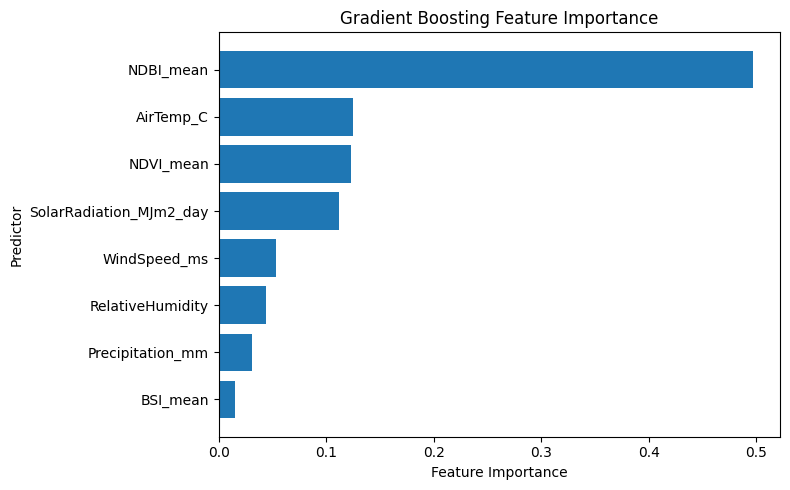


SHAP GLOBAL FEATURE IMPORTANCE


,Feature,Mean_Abs_SHAP
0,NDBI_mean,1.6128
1,AirTemp_C,1.0129
2,SolarRadiation_MJm2_day,0.7273
3,NDVI_mean,0.5805
4,WindSpeed_ms,0.4995
5,RelativeHumidity,0.3042
6,BSI_mean,0.1695
7,Precipitation_mm,0.1399


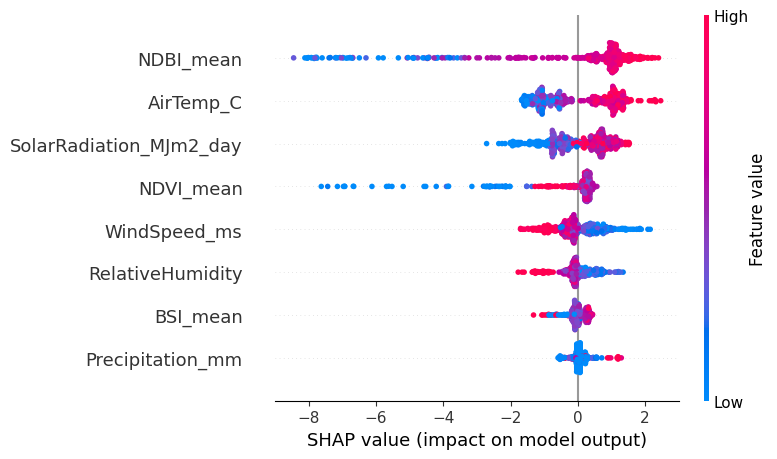

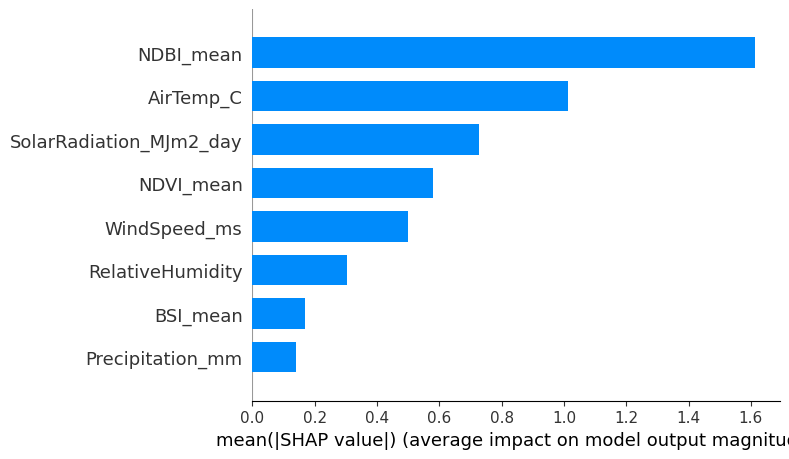


STEP 6 COMPLETE

Results saved to:
/content/drive/MyDrive/Abudhabi Airport Heat surrounding/ML_Results_2021_2025


In [51]:
# ============================================================
# STEP 6 — FEATURE IMPORTANCE + SHAP
# BEST MODEL: GRADIENT BOOSTING
# ============================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.inspection import permutation_importance
import shap


# ============================================================
# 1. LOAD DATA
# ============================================================

file_path = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding/"
    "ERA5/"
    "Final_ERA5_Landsat_2021_2025.csv"
)

df = pd.read_csv(file_path)

features = [
    "AirTemp_C",
    "RelativeHumidity",
    "WindSpeed_ms",
    "Precipitation_mm",
    "SolarRadiation_MJm2_day",
    "NDVI_mean",
    "NDBI_mean",
    "BSI_mean"
]

target = "LST_C_mean"

X = df[features].copy()
y = df[target].copy()


# ============================================================
# 2. FIT FINAL GRADIENT BOOSTING MODEL
# ============================================================

model = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.03,
    max_depth=3,
    min_samples_leaf=3,
    random_state=42
)

model.fit(X, y)


# ============================================================
# 3. BUILT-IN FEATURE IMPORTANCE
# ============================================================

importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
})

importance_df = (
    importance_df
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

print("=" * 75)
print("GRADIENT BOOSTING FEATURE IMPORTANCE")
print("=" * 75)

display(
    importance_df.round(4)
)


# ============================================================
# 4. PERMUTATION IMPORTANCE
# ============================================================

perm = permutation_importance(
    model,
    X,
    y,
    n_repeats=30,
    random_state=42,
    scoring="r2"
)

perm_df = pd.DataFrame({
    "Feature": features,
    "Permutation_Importance":
        perm.importances_mean,
    "Permutation_SD":
        perm.importances_std
})

perm_df = (
    perm_df
    .sort_values(
        "Permutation_Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 75)
print("PERMUTATION IMPORTANCE")
print("=" * 75)

display(
    perm_df.round(4)
)


# ============================================================
# 5. BUILT-IN IMPORTANCE PLOT
# ============================================================

plot_df = importance_df.sort_values(
    "Importance"
)

plt.figure(
    figsize=(8, 5)
)

plt.barh(
    plot_df["Feature"],
    plot_df["Importance"]
)

plt.xlabel(
    "Feature Importance"
)

plt.ylabel(
    "Predictor"
)

plt.title(
    "Gradient Boosting Feature Importance"
)

plt.tight_layout()

output_folder = (
    "/content/drive/MyDrive/"
    "Abudhabi Airport Heat surrounding/"
    "ML_Results_2021_2025"
)

importance_plot = os.path.join(
    output_folder,
    "Gradient_Boosting_Feature_Importance.png"
)

plt.savefig(
    importance_plot,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 6. SHAP EXPLAINER
# ============================================================

explainer = shap.TreeExplainer(
    model
)

shap_values = explainer.shap_values(
    X
)


# ============================================================
# 7. SHAP GLOBAL IMPORTANCE
# ============================================================

mean_abs_shap = np.abs(
    shap_values
).mean(axis=0)

shap_importance_df = pd.DataFrame({
    "Feature": features,
    "Mean_Abs_SHAP": mean_abs_shap
})

shap_importance_df = (
    shap_importance_df
    .sort_values(
        "Mean_Abs_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 75)
print("SHAP GLOBAL FEATURE IMPORTANCE")
print("=" * 75)

display(
    shap_importance_df.round(4)
)


# ============================================================
# 8. SHAP SUMMARY PLOT
# ============================================================

shap.summary_plot(
    shap_values,
    X,
    show=False
)

plt.tight_layout()

shap_summary_path = os.path.join(
    output_folder,
    "SHAP_Summary_Plot.png"
)

plt.savefig(
    shap_summary_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 9. SHAP BAR PLOT
# ============================================================

shap.summary_plot(
    shap_values,
    X,
    plot_type="bar",
    show=False
)

plt.tight_layout()

shap_bar_path = os.path.join(
    output_folder,
    "SHAP_Bar_Plot.png"
)

plt.savefig(
    shap_bar_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 10. SAVE TABLES
# ============================================================

importance_df.to_csv(
    os.path.join(
        output_folder,
        "Gradient_Boosting_Feature_Importance.csv"
    ),
    index=False
)

perm_df.to_csv(
    os.path.join(
        output_folder,
        "Gradient_Boosting_Permutation_Importance.csv"
    ),
    index=False
)

shap_importance_df.to_csv(
    os.path.join(
        output_folder,
        "Gradient_Boosting_SHAP_Importance.csv"
    ),
    index=False
)

print("\n" + "=" * 75)
print("STEP 6 COMPLETE")
print("=" * 75)

print("\nResults saved to:")
print(output_folder)

## 9. Spatial-group cross-validation
Five-fold GroupKFold with ERA5-Land grid cell as the group (14 spatial groups).

In [52]:
# ============================================================
# GRADIENT BOOSTING REGRESSION
# 5-FOLD GROUPED CROSS-VALIDATION
# R2, RMSE, MAE
# ============================================================

import numpy as np
import pandas as pd

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

# ------------------------------------------------------------
# 1. FEATURES AND TARGET
# ------------------------------------------------------------

features = [
    'NDBI_mean',
    'AirTemp_C',
    'NDVI_mean',
    'SolarRadiation_MJm2_day',
    'WindSpeed_ms',
    'RelativeHumidity',
    'Precipitation_mm',
    'BSI_mean'
]

target = 'LST_C_mean'

# ------------------------------------------------------------
# 2. PREPARE DATA
# ------------------------------------------------------------

required_cols = (
    features +
    [target, 'latitude', 'longitude']
)

model_df = df[
    required_cols
].dropna().copy()

print("=" * 70)
print("MODEL DATA")
print("=" * 70)

print("Rows:", len(model_df))
print("Features:", len(features))
print("Target:", target)

# ------------------------------------------------------------
# 3. CREATE SPATIAL GROUP
# ------------------------------------------------------------

# Each latitude-longitude grid cell = one spatial group
model_df['Spatial_Group'] = (
    model_df['latitude'].astype(str)
    + "_"
    + model_df['longitude'].astype(str)
)

print(
    "Unique spatial groups:",
    model_df['Spatial_Group'].nunique()
)

# ------------------------------------------------------------
# 4. X, y, GROUPS
# ------------------------------------------------------------

X = model_df[features]

y = model_df[target]

groups = model_df['Spatial_Group']

# ------------------------------------------------------------
# 5. MODEL
# ------------------------------------------------------------

gb_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    min_samples_split=5,
    min_samples_leaf=3,
    subsample=0.8,
    random_state=42
)

# ------------------------------------------------------------
# 6. GROUPED 5-FOLD CROSS-VALIDATION
# ------------------------------------------------------------

gkf = GroupKFold(
    n_splits=5
)

results = []

print("\n" + "=" * 70)
print("5-FOLD GROUPED CROSS-VALIDATION")
print("=" * 70)

for fold, (train_idx, test_idx) in enumerate(
    gkf.split(
        X,
        y,
        groups=groups
    ),
    start=1
):

    # Training data
    X_train = X.iloc[train_idx]
    y_train = y.iloc[train_idx]

    # Validation data
    X_test = X.iloc[test_idx]
    y_test = y.iloc[test_idx]

    # Fit model
    gb_model.fit(
        X_train,
        y_train
    )

    # Prediction
    y_pred = gb_model.predict(
        X_test
    )

    # Metrics
    r2 = r2_score(
        y_test,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            y_pred
        )
    )

    mae = mean_absolute_error(
        y_test,
        y_pred
    )

    results.append({
        'Fold': fold,
        'R2': r2,
        'RMSE': rmse,
        'MAE': mae,
        'Train_N': len(train_idx),
        'Validation_N': len(test_idx)
    })

    print(
        f"Fold {fold}: "
        f"R² = {r2:.4f} | "
        f"RMSE = {rmse:.4f} °C | "
        f"MAE = {mae:.4f} °C"
    )

# ------------------------------------------------------------
# 7. RESULTS TABLE
# ------------------------------------------------------------

cv_results = pd.DataFrame(
    results
)

print("\n")
print("=" * 70)
print("CROSS-VALIDATION RESULTS")
print("=" * 70)

print(
    cv_results.to_string(
        index=False
    )
)

# ------------------------------------------------------------
# 8. MEAN PERFORMANCE
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("MEAN CROSS-VALIDATION PERFORMANCE")
print("=" * 70)

print(
    f"Mean R²   : "
    f"{cv_results['R2'].mean():.4f}"
    f" ± "
    f"{cv_results['R2'].std():.4f}"
)

print(
    f"Mean RMSE : "
    f"{cv_results['RMSE'].mean():.4f}"
    f" ± "
    f"{cv_results['RMSE'].std():.4f} °C"
)

print(
    f"Mean MAE  : "
    f"{cv_results['MAE'].mean():.4f}"
    f" ± "
    f"{cv_results['MAE'].std():.4f} °C"
)

MODEL DATA
Rows: 560
Features: 8
Target: LST_C_mean
Unique spatial groups: 14

5-FOLD GROUPED CROSS-VALIDATION
Fold 1: R² = 0.7461 | RMSE = 2.9156 °C | MAE = 2.1902 °C
Fold 2: R² = 0.7865 | RMSE = 1.2729 °C | MAE = 1.0407 °C
Fold 3: R² = 0.7528 | RMSE = 1.4098 °C | MAE = 1.0133 °C
Fold 4: R² = 0.5087 | RMSE = 1.8482 °C | MAE = 1.4151 °C
Fold 5: R² = -1.4786 | RMSE = 4.4172 °C | MAE = 3.6408 °C


CROSS-VALIDATION RESULTS
 Fold        R2     RMSE      MAE  Train_N  Validation_N
    1  0.746081 2.915626 2.190160      440           120
    2  0.786457 1.272859 1.040733      440           120
    3  0.752840 1.409828 1.013329      440           120
    4  0.508744 1.848200 1.415052      440           120
    5 -1.478560 4.417191 3.640763      480            80


MEAN CROSS-VALIDATION PERFORMANCE
Mean R²   : 0.2631 ± 0.9799
Mean RMSE : 2.3727 ± 1.3121 °C
Mean MAE  : 1.8600 ± 1.1030 °C


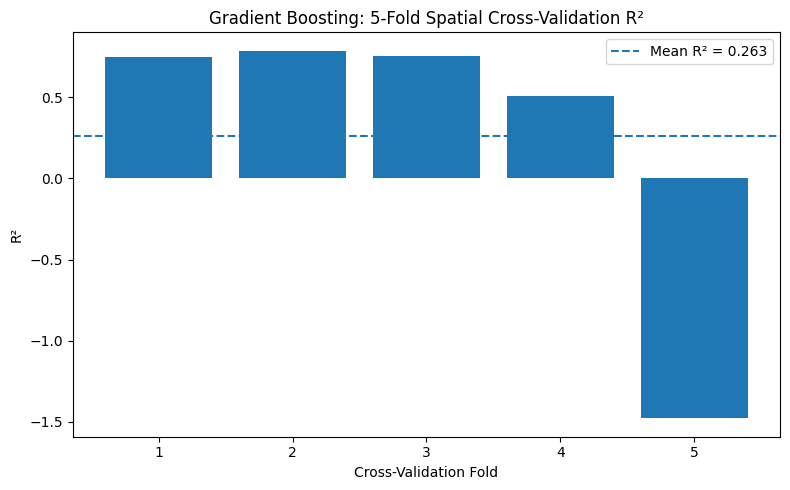

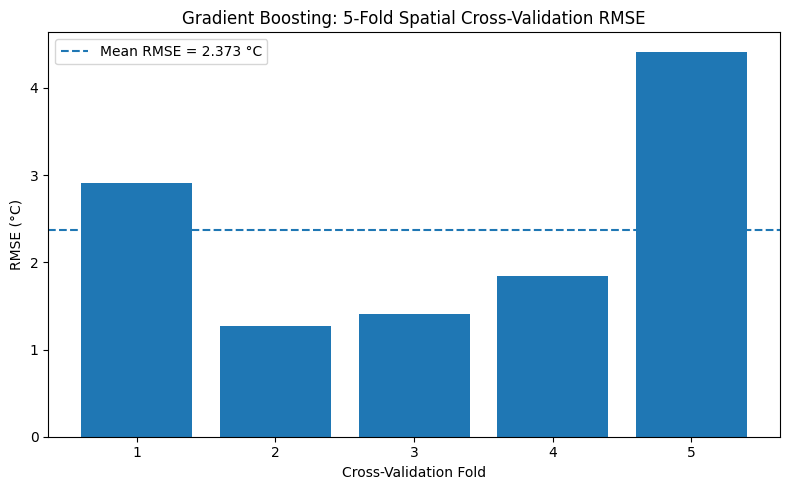

In [53]:
# ============================================================
# CROSS-VALIDATION PERFORMANCE PLOTS
# ============================================================

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# R2 BY FOLD
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    cv_results['Fold'],
    cv_results['R2']
)

plt.axhline(
    cv_results['R2'].mean(),
    linestyle='--',
    label=f"Mean R² = {cv_results['R2'].mean():.3f}"
)

plt.xlabel("Cross-Validation Fold")
plt.ylabel("R²")
plt.title(
    "Gradient Boosting: "
    "5-Fold Spatial Cross-Validation R²"
)

plt.xticks(
    cv_results['Fold']
)

plt.legend()

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# RMSE BY FOLD
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    cv_results['Fold'],
    cv_results['RMSE']
)

plt.axhline(
    cv_results['RMSE'].mean(),
    linestyle='--',
    label=(
        f"Mean RMSE = "
        f"{cv_results['RMSE'].mean():.3f} °C"
    )
)

plt.xlabel("Cross-Validation Fold")
plt.ylabel("RMSE (°C)")
plt.title(
    "Gradient Boosting: "
    "5-Fold Spatial Cross-Validation RMSE"
)

plt.xticks(
    cv_results['Fold']
)

plt.legend()

plt.tight_layout()

plt.show()

In [54]:
# ============================================================
# DIAGNOSE GROUPED CROSS-VALIDATION FOLDS
# ============================================================

import pandas as pd
import numpy as np

fold_diagnostics = []

for fold, (train_idx, test_idx) in enumerate(
    gkf.split(X, y, groups=groups),
    start=1
):

    train_data = model_df.iloc[train_idx]
    test_data = model_df.iloc[test_idx]

    print("\n" + "=" * 75)
    print(f"FOLD {fold}")
    print("=" * 75)

    print("\nValidation spatial groups:")

    validation_groups = (
        test_data[
            ['Spatial_Group', 'latitude', 'longitude']
        ]
        .drop_duplicates()
        .sort_values(
            ['latitude', 'longitude']
        )
    )

    print(
        validation_groups.to_string(
            index=False
        )
    )

    print("\nTraining LST:")
    print(
        train_data[target].describe()
    )

    print("\nValidation LST:")
    print(
        test_data[target].describe()
    )

    fold_diagnostics.append({
        'Fold': fold,
        'N_Validation_Groups':
            test_data['Spatial_Group'].nunique(),
        'Validation_N':
            len(test_data),
        'Validation_LST_Mean':
            test_data[target].mean(),
        'Validation_LST_SD':
            test_data[target].std(),
        'Validation_LST_Min':
            test_data[target].min(),
        'Validation_LST_Max':
            test_data[target].max()
    })


diagnostic_df = pd.DataFrame(
    fold_diagnostics
)

print("\n\n")
print("=" * 75)
print("FOLD DIAGNOSTIC SUMMARY")
print("=" * 75)

print(
    diagnostic_df.to_string(
        index=False
    )
)


FOLD 1

Validation spatial groups:
Spatial_Group  latitude  longitude
    24.3_54.8      24.3       54.8
    24.5_54.5      24.5       54.5
    24.6_54.8      24.6       54.8

Training LST:
count    440.000000
mean      51.784591
std        3.471484
min       41.810269
25%       49.595614
50%       52.239470
75%       54.073483
max       60.692946
Name: LST_C_mean, dtype: float64

Validation LST:
count    120.000000
mean      49.583330
std        5.810333
min       39.439820
25%       43.291108
50%       51.319463
75%       54.221877
max       60.192899
Name: LST_C_mean, dtype: float64

FOLD 2

Validation spatial groups:
Spatial_Group  latitude  longitude
    24.3_54.7      24.3       54.7
    24.4_54.8      24.4       54.8
    24.6_54.7      24.6       54.7

Training LST:
count    440.000000
mean      51.002805
std        4.440673
min       39.439820
25%       48.446083
50%       51.722479
75%       54.082813
max       60.692946
Name: LST_C_mean, dtype: float64

Validation LST:
count

## 10. Temporal hold-out validation
Train on 2021–2024 (n = 448), test on 2025 (n = 112).

AVAILABLE YEARS
Year
2021    112
2022    112
2023    112
2024    112
2025    112
dtype: int64

Test year: 2025

Training years:
[np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]
Testing year:
2025

Training observations: 448
Testing observations : 112

TEMPORAL HOLDOUT VALIDATION
Training years : [np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]
Test year      : 2025
R²             : 0.6944
RMSE           : 2.2677 °C
MAE            : 1.6996 °C


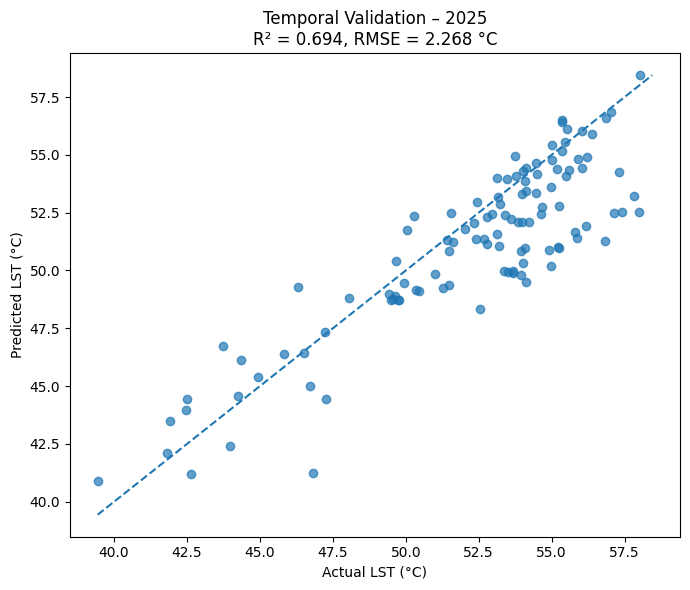

In [55]:
# ============================================================
# TEMPORAL VALIDATION
# TRAIN: EARLIER YEARS
# TEST: LATEST YEAR
# ============================================================

import numpy as np
import pandas as pd

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

# ------------------------------------------------------------
# FEATURES AND TARGET
# ------------------------------------------------------------

features = [
    'NDBI_mean',
    'AirTemp_C',
    'NDVI_mean',
    'SolarRadiation_MJm2_day',
    'WindSpeed_ms',
    'RelativeHumidity',
    'Precipitation_mm',
    'BSI_mean'
]

target = 'LST_C_mean'

# ------------------------------------------------------------
# PREPARE DATA
# ------------------------------------------------------------

temporal_df = df[
    features + [target, 'Year']
].dropna().copy()

print("=" * 70)
print("AVAILABLE YEARS")
print("=" * 70)

print(
    temporal_df.groupby('Year').size()
)

# ------------------------------------------------------------
# IDENTIFY LATEST YEAR
# ------------------------------------------------------------

test_year = temporal_df['Year'].max()

print("\nTest year:", test_year)

# ------------------------------------------------------------
# SPLIT CHRONOLOGICALLY
# ------------------------------------------------------------

train_df = temporal_df[
    temporal_df['Year'] < test_year
].copy()

test_df = temporal_df[
    temporal_df['Year'] == test_year
].copy()

X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

print("\nTraining years:")
print(sorted(train_df['Year'].unique()))

print("Testing year:")
print(test_year)

print("\nTraining observations:", len(train_df))
print("Testing observations :", len(test_df))

# ------------------------------------------------------------
# MODEL
# ------------------------------------------------------------

temporal_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    min_samples_split=5,
    min_samples_leaf=3,
    subsample=0.8,
    random_state=42
)

temporal_model.fit(
    X_train,
    y_train
)

# ------------------------------------------------------------
# PREDICT
# ------------------------------------------------------------

y_pred = temporal_model.predict(
    X_test
)

# ------------------------------------------------------------
# METRICS
# ------------------------------------------------------------

r2 = r2_score(
    y_test,
    y_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred
    )
)

mae = mean_absolute_error(
    y_test,
    y_pred
)

print("\n" + "=" * 70)
print("TEMPORAL HOLDOUT VALIDATION")
print("=" * 70)

print(
    f"Training years : "
    f"{sorted(train_df['Year'].unique())}"
)

print(
    f"Test year      : {test_year}"
)

print(
    f"R²             : {r2:.4f}"
)

print(
    f"RMSE           : {rmse:.4f} °C"
)

print(
    f"MAE            : {mae:.4f} °C"
)

# ------------------------------------------------------------
# ACTUAL VS PREDICTED
# ------------------------------------------------------------

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.7
)

minimum = min(
    y_test.min(),
    y_pred.min()
)

maximum = max(
    y_test.max(),
    y_pred.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle='--'
)

plt.xlabel(
    "Actual LST (°C)"
)

plt.ylabel(
    "Predicted LST (°C)"
)

plt.title(
    f"Temporal Validation – {test_year}\n"
    f"R² = {r2:.3f}, RMSE = {rmse:.3f} °C"
)

plt.tight_layout()

plt.show()

## 11. Error analysis, interpretation and extreme-heat performance
Residuals, performance by temperature range, permutation importance, SHAP, baseline comparisons and the hottest 10% / 25% of 2025 observations.

In [56]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

# Predict unseen 2025 data
y_pred = temporal_model.predict(X_test)

# Calculate metrics
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

print("=" * 70)
print("2025 TEMPORAL HOLDOUT PERFORMANCE")
print("=" * 70)
print(f"R²   : {r2:.4f}")
print(f"RMSE : {rmse:.4f} °C")
print(f"MAE  : {mae:.4f} °C")
print("=" * 70)

2025 TEMPORAL HOLDOUT PERFORMANCE
R²   : 0.6944
RMSE : 2.2677 °C
MAE  : 1.6996 °C


In [57]:
# ============================================================
# STEP 2: RESIDUAL ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Convert to 1D arrays
y_test_array = np.asarray(y_test).ravel()
y_pred_array = np.asarray(y_pred).ravel()

# Residual = Actual - Predicted
residuals = y_test_array - y_pred_array

# Create residual dataframe
residual_df = pd.DataFrame({
    "Observed_LST": y_test_array,
    "Predicted_LST": y_pred_array,
    "Residual": residuals,
    "Absolute_Error": np.abs(residuals)
})

print("=" * 70)
print("RESIDUAL SUMMARY")
print("=" * 70)

print(residual_df["Residual"].describe())

print("\nMean residual:")
print(f"{residual_df['Residual'].mean():.4f} °C")

print("\nResidual standard deviation:")
print(f"{residual_df['Residual'].std():.4f} °C")

print("\nMaximum absolute error:")
print(f"{residual_df['Absolute_Error'].max():.4f} °C")

RESIDUAL SUMMARY
count    112.000000
mean       1.163765
std        1.955023
min       -3.012128
25%       -0.194149
50%        0.790735
75%        2.120551
max        5.591415
Name: Residual, dtype: float64

Mean residual:
1.1638 °C

Residual standard deviation:
1.9550 °C

Maximum absolute error:
5.5914 °C


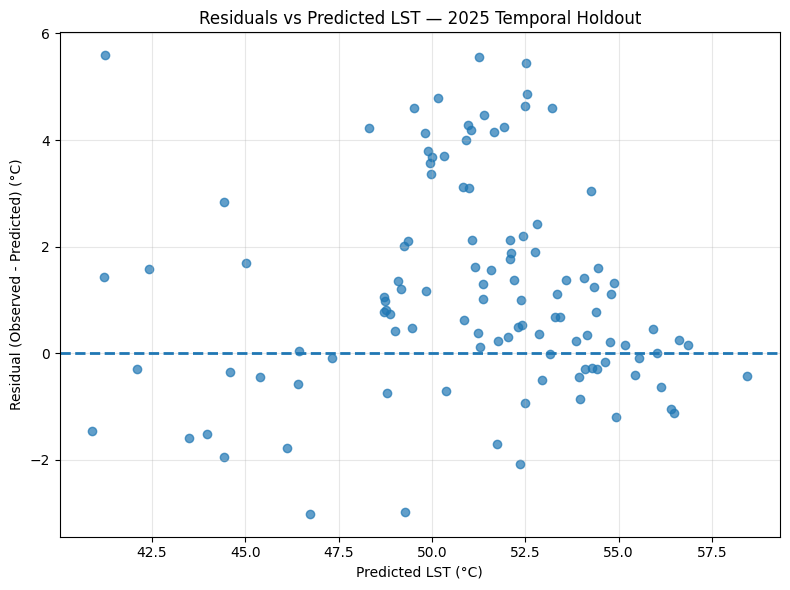

In [58]:
# ============================================================
# RESIDUALS VS PREDICTED LST
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    y_pred_array,
    residuals,
    alpha=0.7
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=2
)

plt.xlabel("Predicted LST (°C)")
plt.ylabel("Residual (Observed - Predicted) (°C)")
plt.title("Residuals vs Predicted LST — 2025 Temporal Holdout")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

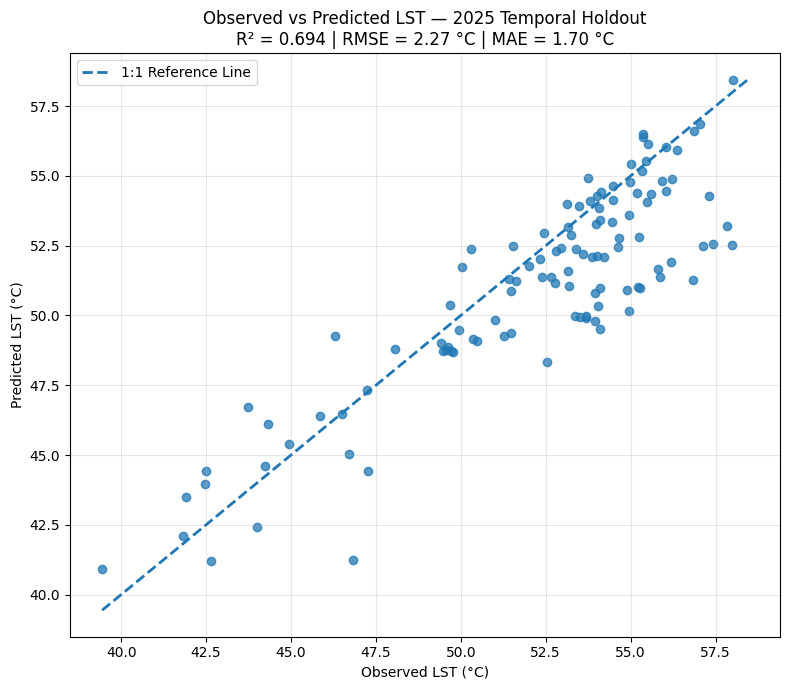

In [59]:
# ============================================================
# STEP 4: OBSERVED VS PREDICTED LST
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 7))

plt.scatter(
    y_test_array,
    y_pred_array,
    alpha=0.75
)

# 1:1 reference line
minimum = min(y_test_array.min(), y_pred_array.min())
maximum = max(y_test_array.max(), y_pred_array.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    linewidth=2,
    label="1:1 Reference Line"
)

plt.xlabel("Observed LST (°C)")
plt.ylabel("Predicted LST (°C)")

plt.title(
    "Observed vs Predicted LST — 2025 Temporal Holdout\n"
    f"R² = {r2:.3f} | RMSE = {rmse:.2f} °C | MAE = {mae:.2f} °C"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [60]:
# ============================================================
# STEP 5: PERFORMANCE BY TEMPERATURE RANGE
# ============================================================

analysis_df = pd.DataFrame({
    "Observed_LST": y_test_array,
    "Predicted_LST": y_pred_array
})

analysis_df["Residual"] = (
    analysis_df["Observed_LST"]
    - analysis_df["Predicted_LST"]
)

analysis_df["Absolute_Error"] = np.abs(
    analysis_df["Residual"]
)

# Divide observed LST into quartiles
analysis_df["Temperature_Group"] = pd.qcut(
    analysis_df["Observed_LST"],
    q=4,
    labels=[
        "Q1 - Lowest",
        "Q2",
        "Q3",
        "Q4 - Highest"
    ]
)

temperature_performance = (
    analysis_df
    .groupby("Temperature_Group", observed=False)
    .agg(
        N=("Observed_LST", "size"),
        Mean_Observed=("Observed_LST", "mean"),
        Mean_Predicted=("Predicted_LST", "mean"),
        Mean_Residual=("Residual", "mean"),
        MAE=("Absolute_Error", "mean")
    )
)

print("=" * 80)
print("MODEL PERFORMANCE BY LST RANGE")
print("=" * 80)

print(
    temperature_performance.round(3)
)

MODEL PERFORMANCE BY LST RANGE
                    N  Mean_Observed  Mean_Predicted  Mean_Residual    MAE
Temperature_Group                                                         
Q1 - Lowest        28         46.213          46.241         -0.028  1.342
Q2                 28         52.267          51.344          0.923  1.270
Q3                 28         54.234          52.514          1.720  1.908
Q4 - Highest       28         56.208          54.168          2.040  2.278


In [61]:
# ============================================================
# STEP 6: LARGEST PREDICTION ERRORS
# ============================================================

largest_errors = (
    analysis_df
    .sort_values(
        "Absolute_Error",
        ascending=False
    )
    .head(10)
)

print("=" * 80)
print("TOP 10 LARGEST PREDICTION ERRORS")
print("=" * 80)

print(
    largest_errors.round(3)
)

TOP 10 LARGEST PREDICTION ERRORS
    Observed_LST  Predicted_LST  Residual  Absolute_Error Temperature_Group
9         46.830         41.239     5.591           5.591       Q1 - Lowest
43        56.834         51.268     5.565           5.565      Q4 - Highest
49        57.988         52.534     5.453           5.453      Q4 - Highest
45        57.419         52.546     4.873           4.873      Q4 - Highest
3         54.960         50.176     4.784           4.784                Q3
44        57.143         52.503     4.640           4.640      Q4 - Highest
53        57.827         53.221     4.607           4.607      Q4 - Highest
85        54.111         49.511     4.600           4.600                Q3
48        55.856         51.386     4.470           4.470      Q4 - Highest
57        55.261         50.973     4.288           4.288      Q4 - Highest


In [62]:
# ============================================================
# STEP 8: PERMUTATION FEATURE IMPORTANCE
# ============================================================

from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

perm_result = permutation_importance(
    temporal_model,
    X_test,
    y_test,
    n_repeats=30,
    random_state=42,
    scoring="r2"
)

perm_importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": perm_result.importances_mean,
    "Importance_SD": perm_result.importances_std
})

perm_importance_df = (
    perm_importance_df
    .sort_values(
        "Importance_Mean",
        ascending=False
    )
    .reset_index(drop=True)
)

print("=" * 80)
print("PERMUTATION FEATURE IMPORTANCE")
print("=" * 80)

print(
    perm_importance_df.round(4)
)

PERMUTATION FEATURE IMPORTANCE
                   Feature  Importance_Mean  Importance_SD
0                NDBI_mean           0.7335         0.1123
1                NDVI_mean           0.4024         0.0685
2  SolarRadiation_MJm2_day           0.0957         0.0156
3                AirTemp_C           0.0274         0.0176
4         RelativeHumidity           0.0187         0.0132
5                 BSI_mean           0.0150         0.0070
6         Precipitation_mm           0.0005         0.0045
7             WindSpeed_ms          -0.0135         0.0137


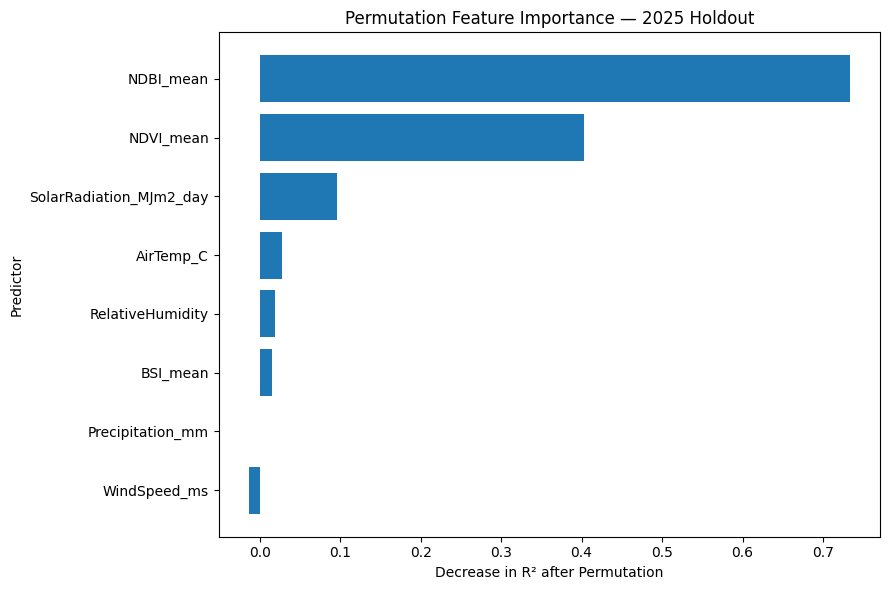

In [63]:
top_perm = perm_importance_df.head(15)

plt.figure(figsize=(9, 6))

plt.barh(
    top_perm["Feature"][::-1],
    top_perm["Importance_Mean"][::-1]
)

plt.xlabel("Decrease in R² after Permutation")
plt.ylabel("Predictor")
plt.title("Permutation Feature Importance — 2025 Holdout")

plt.tight_layout()
plt.show()

In [64]:
# ============================================================
# STEP 9: SHAP ANALYSIS
# ============================================================

import shap

# Create SHAP explainer
explainer = shap.Explainer(
    model,
    X_train
)

# Explain 2025 test observations
shap_values = explainer(
    X_test
)

print("SHAP analysis completed.")

SHAP analysis completed.


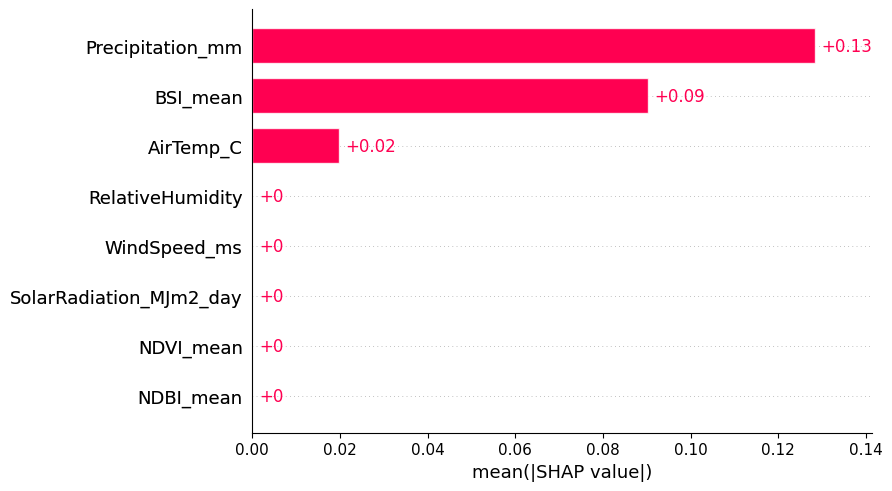

In [65]:
# ============================================================
# SHAP GLOBAL IMPORTANCE
# ============================================================

shap.plots.bar(
    shap_values,
    max_display=15
)

In [66]:
# ============================================================
# STEP 10: LINEAR REGRESSION BASELINE
# ============================================================

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

import numpy as np

linear_model = LinearRegression()

linear_model.fit(
    X_train,
    y_train
)

linear_pred = linear_model.predict(
    X_test
)

linear_r2 = r2_score(
    y_test,
    linear_pred
)

linear_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        linear_pred
    )
)

linear_mae = mean_absolute_error(
    y_test,
    linear_pred
)

print("=" * 70)
print("LINEAR REGRESSION — 2025 HOLDOUT")
print("=" * 70)

print(f"R²   : {linear_r2:.4f}")
print(f"RMSE : {linear_rmse:.4f} °C")
print(f"MAE  : {linear_mae:.4f} °C")

LINEAR REGRESSION — 2025 HOLDOUT
R²   : 0.5106
RMSE : 2.8699 °C
MAE  : 2.3467 °C


In [67]:
# ============================================================
# STEP 11: RANDOM FOREST COMPARISON
# ============================================================

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=500,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    np.asarray(y_train).ravel()
)

rf_pred = rf_model.predict(
    X_test
)

rf_r2 = r2_score(
    y_test,
    rf_pred
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rf_pred
    )
)

rf_mae = mean_absolute_error(
    y_test,
    rf_pred
)

print("=" * 70)
print("RANDOM FOREST — 2025 HOLDOUT")
print("=" * 70)

print(f"R²   : {rf_r2:.4f}")
print(f"RMSE : {rf_rmse:.4f} °C")
print(f"MAE  : {rf_mae:.4f} °C")

RANDOM FOREST — 2025 HOLDOUT
R²   : 0.6987
RMSE : 2.2517 °C
MAE  : 1.7040 °C


In [68]:
# ============================================================
# STEP 12: FINAL MODEL COMPARISON TABLE
# ============================================================

results = []

# Final model
results.append({
    "Model": "Final Model",
    "Training Years": "2021–2024",
    "Test Year": 2025,
    "R2": r2,
    "RMSE_C": rmse,
    "MAE_C": mae
})

# Linear Regression
results.append({
    "Model": "Linear Regression",
    "Training Years": "2021–2024",
    "Test Year": 2025,
    "R2": linear_r2,
    "RMSE_C": linear_rmse,
    "MAE_C": linear_mae
})

# Random Forest
if "rf_r2" in globals():

    results.append({
        "Model": "Random Forest",
        "Training Years": "2021–2024",
        "Test Year": 2025,
        "R2": rf_r2,
        "RMSE_C": rf_rmse,
        "MAE_C": rf_mae
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "R2",
    ascending=False
)

print("=" * 90)
print("FINAL TEMPORAL HOLDOUT MODEL COMPARISON")
print("=" * 90)

print(
    results_df.round(4).to_string(index=False)
)

FINAL TEMPORAL HOLDOUT MODEL COMPARISON
            Model Training Years  Test Year     R2  RMSE_C  MAE_C
    Random Forest      2021–2024       2025 0.6987  2.2517 1.7040
      Final Model      2021–2024       2025 0.6944  2.2677 1.6996
Linear Regression      2021–2024       2025 0.5106  2.8699 2.3467


In [69]:
# ============================================================
# EXTREME-HEAT PERFORMANCE COMPARISON
# Final Model vs Random Forest
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Convert arrays
y_true = np.asarray(y_test).ravel()
final_pred = np.asarray(y_pred).ravel()
rf_predictions = np.asarray(rf_pred).ravel()

# ------------------------------------------------------------
# Define extreme heat using top 10% of observed LST
# ------------------------------------------------------------

threshold_90 = np.percentile(y_true, 90)

extreme_mask = y_true >= threshold_90

print("=" * 80)
print("EXTREME HEAT ANALYSIS")
print("=" * 80)

print(f"90th percentile LST threshold : {threshold_90:.2f} °C")
print(f"Extreme-heat observations     : {extreme_mask.sum()}")
print(f"Total test observations       : {len(y_true)}")


# ------------------------------------------------------------
# Function to calculate extreme-heat metrics
# ------------------------------------------------------------

def extreme_metrics(name, actual, predicted, mask):

    actual_extreme = actual[mask]
    predicted_extreme = predicted[mask]

    residual = actual_extreme - predicted_extreme

    rmse = np.sqrt(
        mean_squared_error(
            actual_extreme,
            predicted_extreme
        )
    )

    mae = mean_absolute_error(
        actual_extreme,
        predicted_extreme
    )

    bias = np.mean(residual)

    return {
        "Model": name,
        "Extreme_N": len(actual_extreme),
        "Extreme_RMSE_C": rmse,
        "Extreme_MAE_C": mae,
        "Mean_Residual_C": bias,
        "Max_Absolute_Error_C": np.max(np.abs(residual))
    }


# ------------------------------------------------------------
# Compare models
# ------------------------------------------------------------

extreme_results = pd.DataFrame([

    extreme_metrics(
        "Final Model",
        y_true,
        final_pred,
        extreme_mask
    ),

    extreme_metrics(
        "Random Forest",
        y_true,
        rf_predictions,
        extreme_mask
    )

])

print("\n" + "=" * 80)
print("PERFORMANCE FOR HOTTEST 10% OF OBSERVATIONS")
print("=" * 80)

print(
    extreme_results
    .round(4)
    .to_string(index=False)
)

EXTREME HEAT ANALYSIS
90th percentile LST threshold : 56.16 °C
Extreme-heat observations     : 12
Total test observations       : 112

PERFORMANCE FOR HOTTEST 10% OF OBSERVATIONS
        Model  Extreme_N  Extreme_RMSE_C  Extreme_MAE_C  Mean_Residual_C  Max_Absolute_Error_C
  Final Model         12          3.6143         2.9211           2.8486                5.5651
Random Forest         12          3.6972         3.0888           3.0427                5.8619


In [70]:
# ============================================================
# HOTTEST 25% PERFORMANCE
# ============================================================

threshold_75 = np.percentile(y_true, 75)

hot_mask = y_true >= threshold_75

hot_results = pd.DataFrame([

    extreme_metrics(
        "Final Model",
        y_true,
        final_pred,
        hot_mask
    ),

    extreme_metrics(
        "Random Forest",
        y_true,
        rf_predictions,
        hot_mask
    )

])

print("=" * 80)
print("HOTTEST 25% OF OBSERVATIONS")
print("=" * 80)

print(f"75th percentile threshold : {threshold_75:.2f} °C")
print(f"Number of observations    : {hot_mask.sum()}")

print("\n")

print(
    hot_results
    .round(4)
    .to_string(index=False)
)

HOTTEST 25% OF OBSERVATIONS
75th percentile threshold : 55.06 °C
Number of observations    : 28


        Model  Extreme_N  Extreme_RMSE_C  Extreme_MAE_C  Mean_Residual_C  Max_Absolute_Error_C
  Final Model         28          2.9674         2.2778           2.0403                5.5651
Random Forest         28          3.0206         2.4410           2.1649                5.8619


FINAL MODEL RESIDUAL DIAGNOSTICS
Number of observations : 112
Mean residual          : 1.1638 °C
Median residual        : 0.7907 °C
Residual SD            : 1.9550 °C
Minimum residual       : -3.0121 °C
Maximum residual       : 5.5914 °C

Residual vs Actual LST
Pearson r : 0.4538
p-value   : 0.000001

Residual vs Predicted LST
Pearson r : -0.0231
p-value   : 0.808872


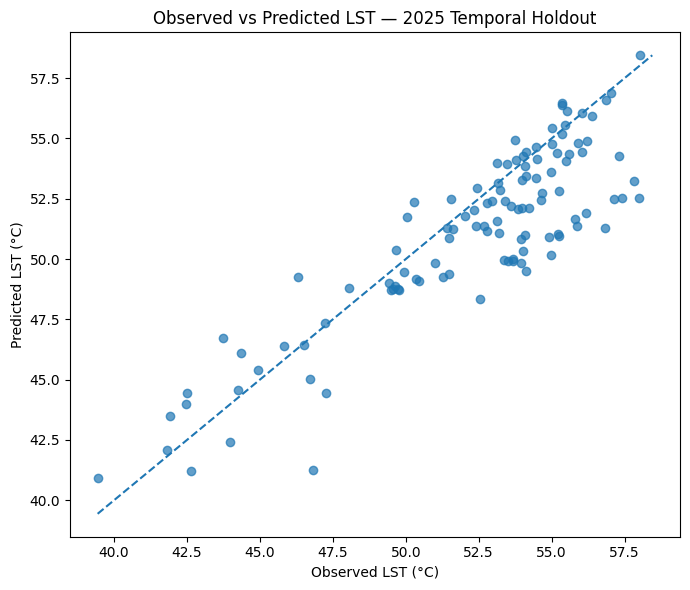

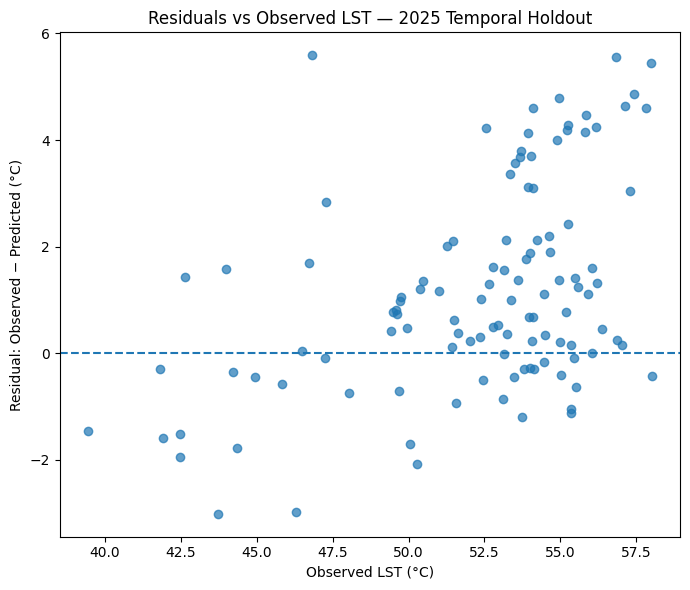

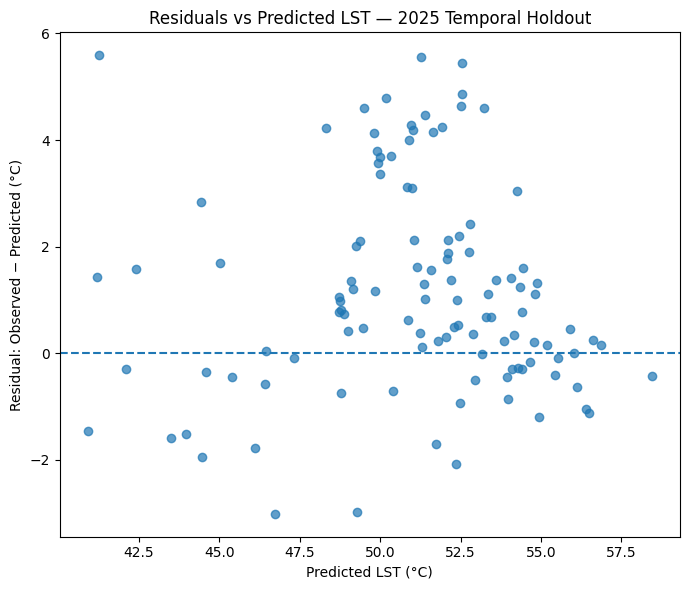

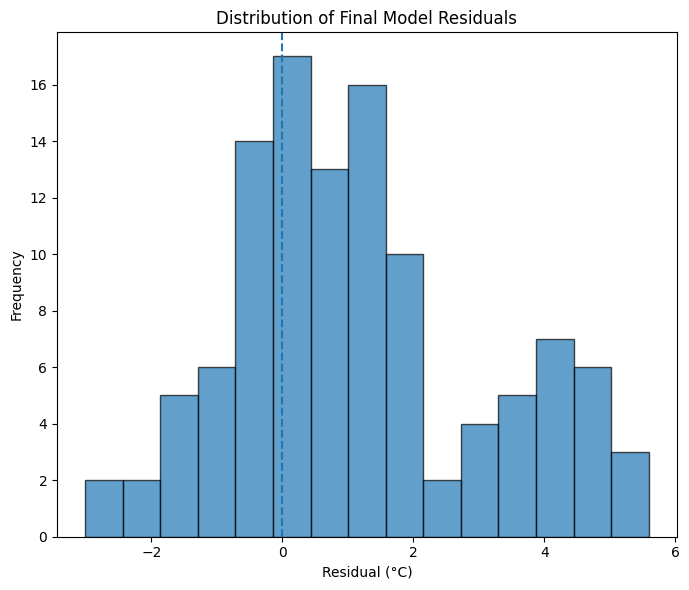

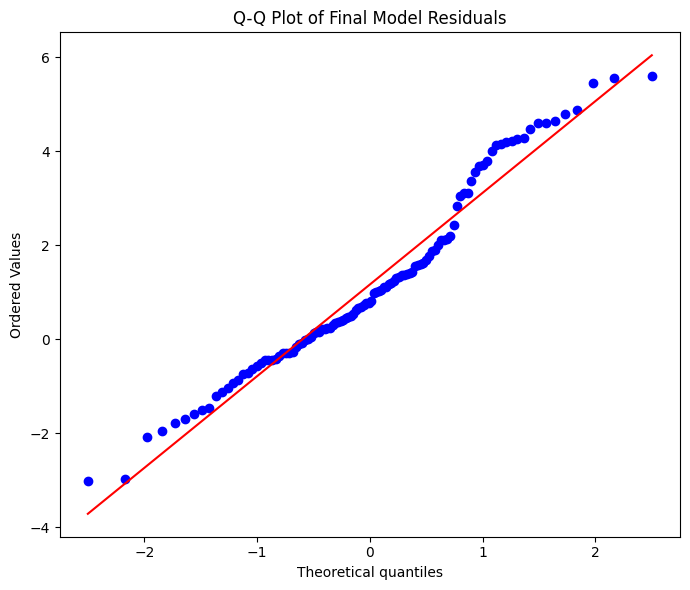

In [71]:
# ============================================================
# FINAL MODEL — RESIDUAL DIAGNOSTICS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# ------------------------------------------------------------
# Prepare actual, predicted and residual values
# ------------------------------------------------------------

y_true = np.asarray(y_test).ravel()
y_pred_final = np.asarray(y_pred).ravel()

residuals = y_true - y_pred_final

print("=" * 80)
print("FINAL MODEL RESIDUAL DIAGNOSTICS")
print("=" * 80)

print(f"Number of observations : {len(residuals)}")
print(f"Mean residual          : {np.mean(residuals):.4f} °C")
print(f"Median residual        : {np.median(residuals):.4f} °C")
print(f"Residual SD            : {np.std(residuals, ddof=1):.4f} °C")
print(f"Minimum residual       : {np.min(residuals):.4f} °C")
print(f"Maximum residual       : {np.max(residuals):.4f} °C")


# ------------------------------------------------------------
# Correlation: residual vs actual LST
# ------------------------------------------------------------

r_actual, p_actual = stats.pearsonr(y_true, residuals)

print("\nResidual vs Actual LST")
print(f"Pearson r : {r_actual:.4f}")
print(f"p-value   : {p_actual:.6f}")


# ------------------------------------------------------------
# Correlation: residual vs predicted LST
# ------------------------------------------------------------

r_pred, p_pred = stats.pearsonr(y_pred_final, residuals)

print("\nResidual vs Predicted LST")
print(f"Pearson r : {r_pred:.4f}")
print(f"p-value   : {p_pred:.6f}")


# ------------------------------------------------------------
# Plot 1 — Actual vs Predicted
# ------------------------------------------------------------

plt.figure(figsize=(7, 6))

plt.scatter(
    y_true,
    y_pred_final,
    alpha=0.7
)

min_val = min(y_true.min(), y_pred_final.min())
max_val = max(y_true.max(), y_pred_final.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Observed LST (°C)")
plt.ylabel("Predicted LST (°C)")
plt.title("Observed vs Predicted LST — 2025 Temporal Holdout")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Plot 2 — Residual vs Actual LST
# ------------------------------------------------------------

plt.figure(figsize=(7, 6))

plt.scatter(
    y_true,
    residuals,
    alpha=0.7
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Observed LST (°C)")
plt.ylabel("Residual: Observed − Predicted (°C)")
plt.title("Residuals vs Observed LST — 2025 Temporal Holdout")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Plot 3 — Residual vs Predicted LST
# ------------------------------------------------------------

plt.figure(figsize=(7, 6))

plt.scatter(
    y_pred_final,
    residuals,
    alpha=0.7
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted LST (°C)")
plt.ylabel("Residual: Observed − Predicted (°C)")
plt.title("Residuals vs Predicted LST — 2025 Temporal Holdout")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Plot 4 — Residual distribution
# ------------------------------------------------------------

plt.figure(figsize=(7, 6))

plt.hist(
    residuals,
    bins=15,
    edgecolor="black",
    alpha=0.7
)

plt.axvline(
    x=0,
    linestyle="--"
)

plt.xlabel("Residual (°C)")
plt.ylabel("Frequency")
plt.title("Distribution of Final Model Residuals")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Plot 5 — Q-Q plot
# ------------------------------------------------------------

plt.figure(figsize=(7, 6))

stats.probplot(
    residuals,
    dist="norm",
    plot=plt
)

plt.title("Q-Q Plot of Final Model Residuals")

plt.tight_layout()
plt.show()

## 12. Paper figures at 300 dpi
Self-contained: reloads the final dataset, rebuilds the 2025 temporal model and the spatial cross-validation, and saves all figures to `ML_Results_2021_2025/Figures_300dpi`.

2025 hold-out check: R2 = 0.6944 (paper: 0.6944)
 Fold      R2   RMSE
    1  0.7461 2.9156
    2  0.7865 1.2729
    3  0.7528 1.4098
    4  0.5087 1.8482
    5 -1.4786 4.4172


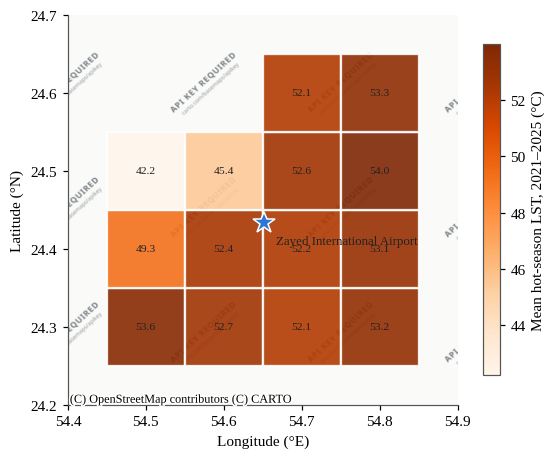

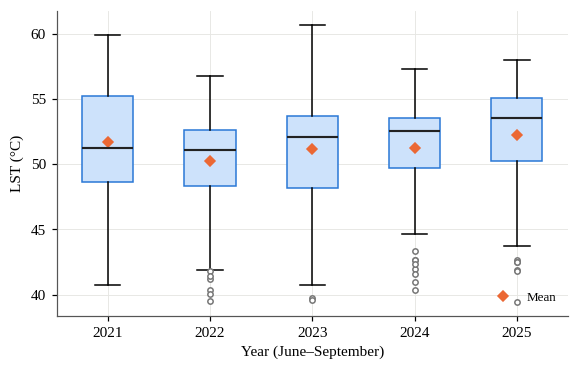

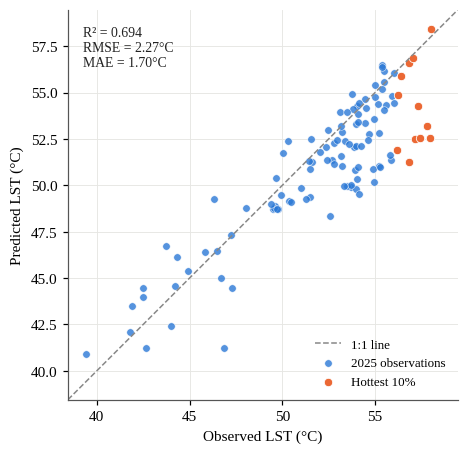

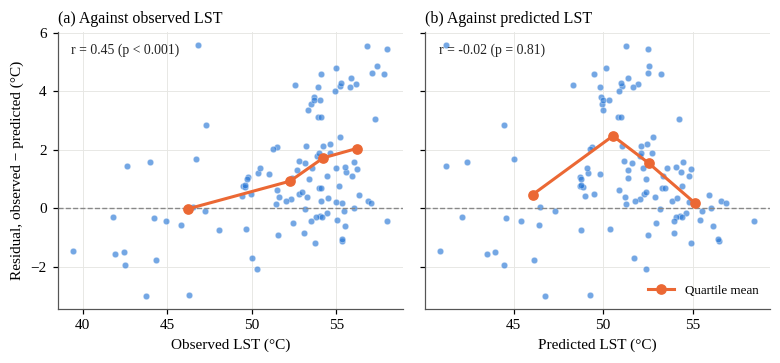

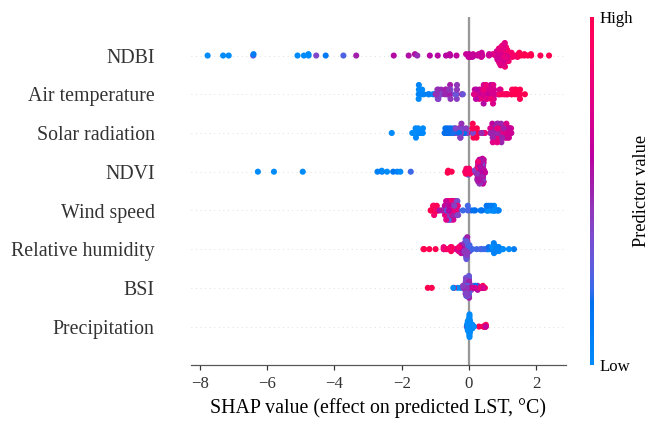

Mean |SHAP| (2025 hold-out):
 NDBI                 1.496
Air temperature      0.790
Solar radiation      0.749
NDVI                 0.593
Wind speed           0.588
Relative humidity    0.408
BSI                  0.131
Precipitation        0.068
dtype: float64


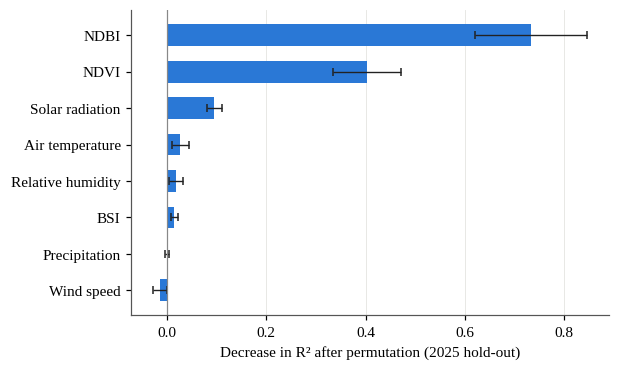

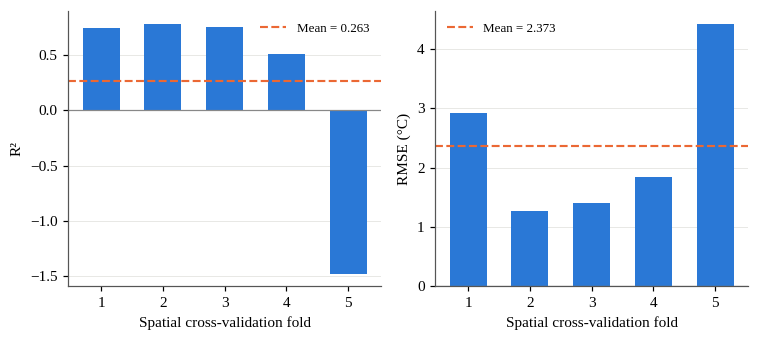

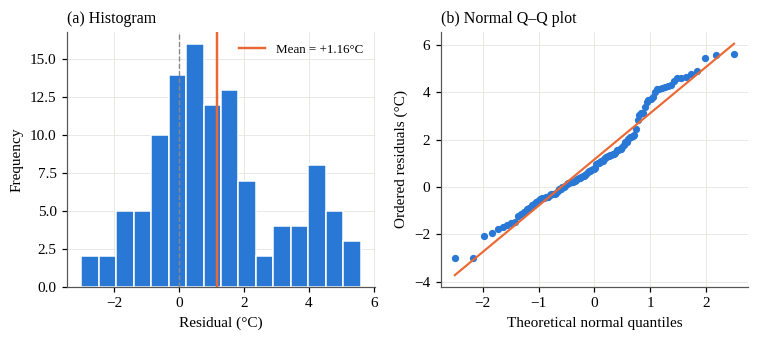


Saved 8 figures at 300 dpi to:
/content/drive/MyDrive/Abudhabi Airport Heat surrounding/ML_Results_2021_2025/Figures_300dpi


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [72]:
# ============================================================
# PAPER FIGURES AT 300 DPI (self-contained)
# ============================================================
import os, zipfile
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy import stats
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.inspection import permutation_importance

DATA = ("/content/drive/MyDrive/Abudhabi Airport Heat surrounding/"
        "ERA5/Final_ERA5_Landsat_2021_2025.csv")
FIG_DIR = ("/content/drive/MyDrive/Abudhabi Airport Heat surrounding/"
           "ML_Results_2021_2025/Figures_300dpi")
os.makedirs(FIG_DIR, exist_ok=True)

FEATURES = ["NDBI_mean", "AirTemp_C", "NDVI_mean", "SolarRadiation_MJm2_day",
            "WindSpeed_ms", "RelativeHumidity", "Precipitation_mm", "BSI_mean"]
TARGET = "LST_C_mean"

def gb():   # identical to your temporal and spatial-CV model (cells 76 and 79)
    return GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=3,
                                     min_samples_split=5, min_samples_leaf=3,
                                     subsample=0.8, random_state=42)

df = pd.read_csv(DATA)
df = df[FEATURES + [TARGET, "Year", "latitude", "longitude"]].dropna().reset_index(drop=True)

# ---- 2025 temporal hold-out ----
train, test = df[df.Year < 2025], df[df.Year == 2025]
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
temporal_model = gb().fit(X_train, y_train)
print(f"2025 hold-out check: R2 = {r2_score(y_test, temporal_model.predict(X_test)):.4f} (paper: 0.6944)")

# ---- spatial-group 5-fold CV ----
groups = df.latitude.astype(str) + "_" + df.longitude.astype(str)
rows = []
for k, (tr, va) in enumerate(GroupKFold(n_splits=5).split(df[FEATURES], df[TARGET], groups), 1):
    m = gb().fit(df.loc[tr, FEATURES], df.loc[tr, TARGET]); p = m.predict(df.loc[va, FEATURES])
    rows.append({"Fold": k, "R2": r2_score(df.loc[va, TARGET], p),
                 "RMSE": np.sqrt(mean_squared_error(df.loc[va, TARGET], p))})
cv_results = pd.DataFrame(rows)
print(cv_results.round(4).to_string(index=False))

saved = []
plt.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
    "font.size": 10, "axes.titlesize": 10.5, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#555555", "axes.linewidth": 0.8,
    "savefig.dpi": 300, "figure.dpi": 110,
})
BLUE, ORANGE, INK, GRID = "#2a78d6", "#eb6834", "#222222", "#e6e6e3"
LABELS = {"NDBI_mean": "NDBI", "NDVI_mean": "NDVI", "BSI_mean": "BSI",
          "AirTemp_C": "Air temperature", "RelativeHumidity": "Relative humidity",
          "WindSpeed_ms": "Wind speed", "Precipitation_mm": "Precipitation",
          "SolarRadiation_MJm2_day": "Solar radiation"}
AIRPORT = (24.433, 54.651)   # Zayed International Airport (lat, lon)

def save(fig, name):
    path = os.path.join(FIG_DIR, name)
    fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")
    saved.append(path); plt.show(); plt.close(fig)

def tidy(ax):
    ax.grid(color=GRID, lw=0.6); ax.set_axisbelow(True)

y_true = np.asarray(y_test).ravel()
y_hat = np.asarray(temporal_model.predict(X_test)).ravel()
res = y_true - y_hat

# ---------- Fig A: study area — mean hot-season LST per ERA5-Land cell ----------
cells = df.groupby(["latitude", "longitude"])[TARGET].mean().reset_index()
fig, ax = plt.subplots(figsize=(6.0, 4.6))
norm = matplotlib.colors.Normalize(cells[TARGET].min(), cells[TARGET].max())
cmap = plt.get_cmap("Oranges")
step = 0.1
for _, r in cells.iterrows():
    ax.add_patch(Rectangle((r.longitude - step / 2, r.latitude - step / 2), step, step,
                           fc=cmap(norm(r[TARGET])), ec="white", lw=1.5, alpha=0.9, zorder=2))
    ax.text(r.longitude, r.latitude, f"{r[TARGET]:.1f}", ha="center", va="center",
            fontsize=7.5, color=INK, zorder=3)
try:   # optional basemap (needs internet; pip install contextily)
    import contextily as cx
    ax.set_xlim(cells.longitude.min() - 0.1, cells.longitude.max() + 0.1)
    ax.set_ylim(cells.latitude.min() - 0.1, cells.latitude.max() + 0.1)
    cx.add_basemap(ax, crs="EPSG:4326", source=cx.providers.CartoDB.PositronNoLabels, zorder=0)
except Exception:
    pass
ax.plot(AIRPORT[1], AIRPORT[0], marker="*", ms=15, color=BLUE, mec="white", mew=1, zorder=4)
ax.annotate("Zayed International Airport", (AIRPORT[1], AIRPORT[0]), xytext=(8, -14),
            textcoords="offset points", fontsize=8.5, color=INK, zorder=4)
sm = matplotlib.cm.ScalarMappable(norm=norm, cmap=cmap)
fig.colorbar(sm, ax=ax, shrink=0.85, label="Mean hot-season LST, 2021–2025 (°C)")
ax.set_xlim(cells.longitude.min() - 0.1, cells.longitude.max() + 0.1)
ax.set_ylim(cells.latitude.min() - 0.1, cells.latitude.max() + 0.1)
ax.set_aspect("equal"); ax.set_xlabel("Longitude (°E)"); ax.set_ylabel("Latitude (°N)")
save(fig, "FigA_study_area_mean_LST.png")

# ---------- Fig B: LST distribution by year ----------
years = sorted(df["Year"].unique())
fig, ax = plt.subplots(figsize=(6.0, 3.6))
bp = ax.boxplot([df.loc[df.Year == yr, TARGET] for yr in years],
                widths=0.5, patch_artist=True, medianprops=dict(color=INK, lw=1.4),
                flierprops=dict(marker="o", ms=3.5, mfc="white", mec="#777777"))
for b in bp["boxes"]: b.set(facecolor="#cde2fb", edgecolor=BLUE, lw=1)
ax.set_xticks(range(1, len(years) + 1)); ax.set_xticklabels([str(y) for y in years])
ax.plot(range(1, len(years) + 1), [df.loc[df.Year == yr, TARGET].mean() for yr in years],
        marker="D", ms=5, color=ORANGE, lw=0, label="Mean")
ax.set_ylabel("LST (°C)"); ax.set_xlabel("Year (June–September)")
ax.legend(frameon=False, fontsize=8.5, loc="lower right"); tidy(ax)
save(fig, "FigB_LST_by_year.png")

# ---------- Fig C: observed vs predicted, 2025 hold-out ----------
hot = y_true >= np.percentile(y_true, 90)
r2 = 1 - np.sum(res ** 2) / np.sum((y_true - y_true.mean()) ** 2)
rmse = np.sqrt(np.mean(res ** 2)); mae = np.mean(np.abs(res))
lo, hi = min(y_true.min(), y_hat.min()) - 1, max(y_true.max(), y_hat.max()) + 1
fig, ax = plt.subplots(figsize=(4.8, 4.6))
ax.plot([lo, hi], [lo, hi], ls="--", color="#888888", lw=1, label="1:1 line")
ax.scatter(y_true[~hot], y_hat[~hot], s=24, color=BLUE, alpha=0.8, edgecolor="white", lw=0.4, label="2025 observations")
ax.scatter(y_true[hot], y_hat[hot], s=30, color=ORANGE, edgecolor="white", lw=0.5, label="Hottest 10%")
ax.text(0.04, 0.96, f"R² = {r2:.3f}\nRMSE = {rmse:.2f}°C\nMAE = {mae:.2f}°C", transform=ax.transAxes,
        va="top", fontsize=9, color=INK)
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
ax.set_xlabel("Observed LST (°C)"); ax.set_ylabel("Predicted LST (°C)")
ax.legend(frameon=False, fontsize=8.5, loc="lower right"); tidy(ax)
save(fig, "FigC_observed_vs_predicted_2025.png")

# ---------- Fig D: residuals vs observed and vs predicted ----------
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.4), sharey=True)
for ax, x, xl in [(axes[0], y_true, "Observed LST (°C)"), (axes[1], y_hat, "Predicted LST (°C)")]:
    ax.axhline(0, color="#888888", lw=0.9, ls="--")
    ax.scatter(x, res, s=18, color=BLUE, alpha=0.65, edgecolor="white", lw=0.3)
    q = pd.qcut(x, 4, labels=False)
    ax.plot([x[q == k].mean() for k in range(4)], [res[q == k].mean() for k in range(4)],
            color=ORANGE, marker="o", ms=6, lw=2, label="Quartile mean")
    rr, pp = stats.pearsonr(x, res)
    ax.text(0.04, 0.96, f"r = {rr:.2f} (p {'< 0.001' if pp < 0.001 else f'= {pp:.2f}'})",
            transform=ax.transAxes, va="top", fontsize=9, color=INK)
    ax.set_xlabel(xl); tidy(ax)
axes[0].set_ylabel("Residual, observed − predicted (°C)")
axes[0].set_title("(a) Against observed LST", loc="left"); axes[1].set_title("(b) Against predicted LST", loc="left")
axes[1].legend(frameon=False, fontsize=8.5, loc="lower right")
fig.tight_layout(); save(fig, "FigD_residuals_observed_vs_predicted.png")

# ---------- Fig E: SHAP beeswarm (2025 hold-out, temporal model) ----------
try:
    import shap
    Xs = X_test.rename(columns=LABELS)
    sv = shap.TreeExplainer(temporal_model).shap_values(X_test)
    plt.figure()
    shap.summary_plot(sv, Xs, show=False, plot_size=(6.2, 4.0), color_bar_label="Predictor value")
    fig = plt.gcf(); fig.axes[0].set_xlabel("SHAP value (effect on predicted LST, °C)")
    save(fig, "FigE_SHAP_beeswarm_2025.png")
    shap_rank = pd.Series(np.abs(sv).mean(0), index=Xs.columns).sort_values(ascending=False)
    print("Mean |SHAP| (2025 hold-out):\n", shap_rank.round(3))
except Exception as e:
    print("SHAP figure skipped:", e)

# ---------- Fig F: permutation importance (2025 hold-out) ----------
pi = permutation_importance(temporal_model, X_test, y_test, n_repeats=30, random_state=42, scoring="r2")
pdf = (pd.DataFrame({"Feature": [LABELS.get(c, c) for c in X_test.columns],
                     "Mean": pi.importances_mean, "SD": pi.importances_std})
       .sort_values("Mean"))
fig, ax = plt.subplots(figsize=(5.6, 3.6))
ax.barh(pdf.Feature, pdf.Mean, xerr=pdf.SD, color=BLUE, height=0.6,
        error_kw=dict(ecolor=INK, lw=0.9, capsize=2.5))
ax.axvline(0, color="#888888", lw=0.8)
ax.set_xlabel("Decrease in R² after permutation (2025 hold-out)"); tidy(ax); ax.yaxis.grid(False)
save(fig, "FigF_permutation_importance_2025.png")

# ---------- Fig S1: spatial cross-validation by fold ----------
try:
    fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.2))
    for ax, col, lab in [(axes[0], "R2", "R²"), (axes[1], "RMSE", "RMSE (°C)")]:
        ax.bar(cv_results["Fold"], cv_results[col], color=BLUE, width=0.6)
        ax.axhline(cv_results[col].mean(), ls="--", color=ORANGE, lw=1.4,
                   label=f"Mean = {cv_results[col].mean():.3f}")
        ax.axhline(0, color="#888888", lw=0.8)
        ax.set_xlabel("Spatial cross-validation fold"); ax.set_ylabel(lab)
        ax.set_xticks(cv_results["Fold"]); ax.legend(frameon=False, fontsize=8.5); tidy(ax); ax.xaxis.grid(False)
    fig.tight_layout(); save(fig, "FigS1_spatial_CV_by_fold.png")
except NameError:
    print("cv_results not found - run the spatial cross-validation cell first.")

# ---------- Fig S2: residual distribution ----------
fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.2))
axes[0].hist(res, bins=16, color=BLUE, edgecolor="white")
axes[0].axvline(0, color="#888888", ls="--", lw=0.9)
axes[0].axvline(res.mean(), color=ORANGE, lw=1.6, label=f"Mean = {res.mean():+.2f}°C")
axes[0].set_xlabel("Residual (°C)"); axes[0].set_ylabel("Frequency"); axes[0].legend(frameon=False, fontsize=8.5)
(osm, osr), (slope, icpt, _) = stats.probplot(res, dist="norm")
axes[1].scatter(osm, osr, s=14, color=BLUE)
axes[1].plot(osm, slope * np.asarray(osm) + icpt, color=ORANGE, lw=1.4)
axes[1].set_xlabel("Theoretical normal quantiles"); axes[1].set_ylabel("Ordered residuals (°C)")
axes[0].set_title("(a) Histogram", loc="left"); axes[1].set_title("(b) Normal Q–Q plot", loc="left")
for ax in axes: tidy(ax)
fig.tight_layout(); save(fig, "FigS2_residual_distribution.png")

# ---------- zip everything for download ----------
zip_path = os.path.join(FIG_DIR, "Figures_300dpi.zip")
with zipfile.ZipFile(zip_path, "w") as z:
    for p in saved: z.write(p, os.path.basename(p))
print(f"\nSaved {len(saved)} figures at 300 dpi to:\n{FIG_DIR}")
try:
    from google.colab import files; files.download(zip_path)
except Exception:
    pass

## 13. Additional analyses
(1) Errors by quartile of predicted LST, (2) nominal 90% prediction intervals from quantile Gradient Boosting, (3) area of applicability (dissimilarity index, Meyer & Pebesma 2021) for the spatial folds.

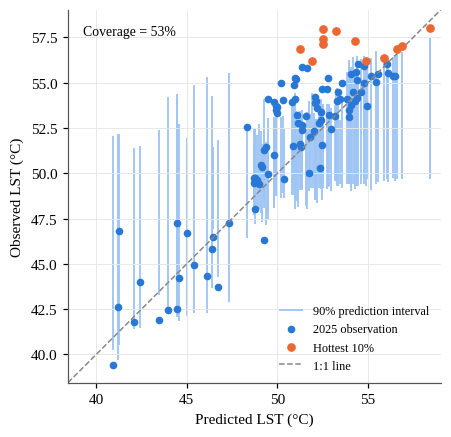

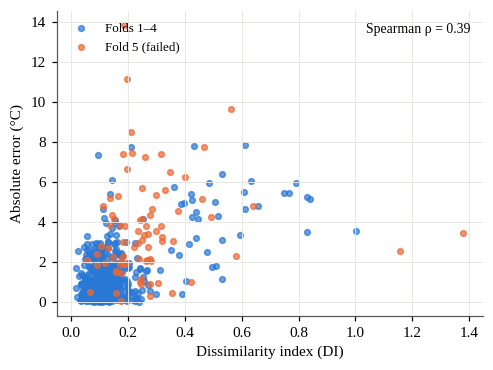


RESULTS FOR THE PAPER (copy everything below)
Check: 2025 R2 = 0.6944 (paper 0.6944)

(1) RESIDUALS BY QUARTILE OF PREDICTED LST
               N  Mean_pred  Mean_obs  Mean_residual   MAE
bin                                                       
Q1 (coolest)  28      46.06     46.52           0.46  1.45
Q2            28      50.55     53.02           2.47  2.73
Q3            28      52.54     54.08           1.54  1.92
Q4 (hottest)  28      55.12     55.30           0.18  0.70
Hottest 10% by PREDICTED LST: n=12, mean residual=-0.33 C, RMSE=0.64 C

(2) 90% PREDICTION INTERVALS (quantile Gradient Boosting, 2025 hold-out)
Coverage all 2025: 52.7%  | mean width: 5.99 C
Coverage hottest 10% (observed): 0.0%  | share above upper bound: 100.0%

(3) AREA OF APPLICABILITY — SPATIAL FOLDS
 Fold                          Groups     R2  RMSE  Mean_DI  Pct_outside_AOA
    1 24.3_54.8, 24.5_54.5, 24.6_54.8  0.746 2.916    0.256           30.833
    2 24.3_54.7, 24.4_54.8, 24.6_54.7  0.786 1.273    

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [73]:
# ============================================================
# ADDITIONAL ANALYSES: PREDICTED-LST QUARTILES, PREDICTION INTERVALS, AREA OF APPLICABILITY
# ============================================================
import os, zipfile
import numpy as np, pandas as pd
import matplotlib; import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance

DATA = ("/content/drive/MyDrive/Abudhabi Airport Heat surrounding/"
        "ERA5/Final_ERA5_Landsat_2021_2025.csv")
FIG_DIR = ("/content/drive/MyDrive/Abudhabi Airport Heat surrounding/"
           "ML_Results_2021_2025/Figures_300dpi")
os.makedirs(FIG_DIR, exist_ok=True)
FEATURES = ["NDBI_mean", "AirTemp_C", "NDVI_mean", "SolarRadiation_MJm2_day",
            "WindSpeed_ms", "RelativeHumidity", "Precipitation_mm", "BSI_mean"]
TARGET = "LST_C_mean"
GB = dict(n_estimators=200, learning_rate=0.05, max_depth=3, min_samples_split=5,
          min_samples_leaf=3, subsample=0.8, random_state=42)
plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
                     "font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "savefig.dpi": 300})
BLUE, ORANGE, INK, GRID = "#2a78d6", "#eb6834", "#222222", "#e6e6e3"
out = []

df = pd.read_csv(DATA)
df = df[FEATURES + [TARGET, "Year", "latitude", "longitude"]].dropna().reset_index(drop=True)
tr, te = df[df.Year < 2025], df[df.Year == 2025]
Xtr, ytr, Xte, yte = tr[FEATURES], tr[TARGET].to_numpy(), te[FEATURES], te[TARGET].to_numpy()
model = GradientBoostingRegressor(**GB).fit(Xtr, ytr)
pred = model.predict(Xte); res = yte - pred
out.append(f"Check: 2025 R2 = {r2_score(yte, pred):.4f} (paper 0.6944)")

# ---------- (1) residuals binned by predicted LST ----------
q = pd.qcut(pred, 4, labels=["Q1 (coolest)", "Q2", "Q3", "Q4 (hottest)"])
tab = (pd.DataFrame({"bin": q, "pred": pred, "obs": yte, "res": res})
       .groupby("bin", observed=False)
       .agg(N=("res", "size"), Mean_pred=("pred", "mean"), Mean_obs=("obs", "mean"),
            Mean_residual=("res", "mean"), MAE=("res", lambda r: np.mean(np.abs(r)))).round(2))
out.append("\n(1) RESIDUALS BY QUARTILE OF PREDICTED LST\n" + tab.to_string())
top_pred = pred >= np.percentile(pred, 90)
out.append(f"Hottest 10% by PREDICTED LST: n={top_pred.sum()}, mean residual={res[top_pred].mean():+.2f} C, "
           f"RMSE={np.sqrt(np.mean(res[top_pred]**2)):.2f} C")

# ---------- (2) 90% prediction intervals (quantile GB) ----------
qkw = {k: v for k, v in GB.items()}
lo = GradientBoostingRegressor(loss="quantile", alpha=0.05, **qkw).fit(Xtr, ytr).predict(Xte)
hi = GradientBoostingRegressor(loss="quantile", alpha=0.95, **qkw).fit(Xtr, ytr).predict(Xte)
inside = (yte >= lo) & (yte <= hi)
hot = yte >= np.percentile(yte, 90)
out.append("\n(2) 90% PREDICTION INTERVALS (quantile Gradient Boosting, 2025 hold-out)")
out.append(f"Coverage all 2025: {inside.mean()*100:.1f}%  | mean width: {np.mean(hi-lo):.2f} C")
out.append(f"Coverage hottest 10% (observed): {inside[hot].mean()*100:.1f}%  | "
           f"share above upper bound: {np.mean(yte[hot] > hi[hot])*100:.1f}%")
order = np.argsort(pred)
fig, ax = plt.subplots(figsize=(5.0, 4.4))
ax.vlines(pred, lo, hi, color="#9ec5f4", lw=1.2, label="90% prediction interval", zorder=1)
ax.scatter(pred[~hot], yte[~hot], s=16, color=BLUE, zorder=2, label="2025 observation")
ax.scatter(pred[hot], yte[hot], s=22, color=ORANGE, zorder=3, label="Hottest 10%")
m0, m1 = min(lo.min(), yte.min()) - 1, max(hi.max(), yte.max()) + 1
ax.plot([m0, m1], [m0, m1], ls="--", color="#888888", lw=1, label="1:1 line")
ax.set_xlim(m0, m1); ax.set_ylim(m0, m1); ax.set_aspect("equal")
ax.set_xlabel("Predicted LST (°C)"); ax.set_ylabel("Observed LST (°C)")
ax.text(0.04, 0.96, f"Coverage = {inside.mean()*100:.0f}%", transform=ax.transAxes, va="top", fontsize=9)
ax.grid(color=GRID, lw=0.6); ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.savefig(os.path.join(FIG_DIR, "FigG_prediction_intervals_2025.png"), bbox_inches="tight", facecolor="white")
plt.show(); plt.close(fig)

# ---------- (3) area of applicability for spatial folds ----------
# Dissimilarity index (DI) following Meyer & Pebesma (2021): importance-weighted,
# standardized predictor distance from each test point to its nearest training
# point, divided by the mean pairwise distance within the training data.
groups = df.latitude.astype(str) + "_" + df.longitude.astype(str)
X, y = df[FEATURES].to_numpy(), df[TARGET].to_numpy()
rows, di_all, err_all, fold_all = [], [], [], []
for k, (a, b) in enumerate(GroupKFold(n_splits=5).split(X, y, groups), 1):
    m = GradientBoostingRegressor(**GB).fit(X[a], y[a])
    w = permutation_importance(m, X[a], y[a], n_repeats=10, random_state=42).importances_mean
    w = np.clip(w, 0, None); w = w / w.sum() if w.sum() > 0 else np.ones_like(w) / len(w)
    sc = StandardScaler().fit(X[a]); A, B = sc.transform(X[a]) * w, sc.transform(X[b]) * w
    dAA = np.sqrt(((A[:, None, :] - A[None, :, :]) ** 2).sum(-1))
    dbar = dAA[np.triu_indices(len(A), 1)].mean()
    np.fill_diagonal(dAA, np.inf)
    di_train = dAA.min(1) / dbar
    thr = np.percentile(di_train, 75) + 1.5 * (np.percentile(di_train, 75) - np.percentile(di_train, 25))
    di = np.sqrt(((B[:, None, :] - A[None, :, :]) ** 2).sum(-1)).min(1) / dbar
    p = m.predict(X[b])
    rows.append({"Fold": k, "Groups": ", ".join(sorted(groups[b].unique())), "R2": r2_score(y[b], p),
                 "RMSE": np.sqrt(mean_squared_error(y[b], p)), "Mean_DI": di.mean(),
                 "Pct_outside_AOA": 100 * np.mean(di > thr)})
    di_all += list(di); err_all += list(np.abs(y[b] - p)); fold_all += [k] * len(b)
aoa = pd.DataFrame(rows).round(3)
rho = pd.Series(di_all).corr(pd.Series(err_all), method="spearman")
out.append("\n(3) AREA OF APPLICABILITY — SPATIAL FOLDS\n" + aoa.to_string(index=False))
out.append(f"Spearman correlation, DI vs absolute error: {rho:.2f}")
fig, ax = plt.subplots(figsize=(5.0, 3.6))
for k in range(1, 6):
    sel = np.array(fold_all) == k
    ax.scatter(np.array(di_all)[sel], np.array(err_all)[sel], s=14, alpha=0.7,
               color=ORANGE if k == 5 else BLUE, label="Fold 5 (failed)" if k == 5 else ("Folds 1–4" if k == 1 else None))
ax.set_xlabel("Dissimilarity index (DI)"); ax.set_ylabel("Absolute error (°C)")
ax.text(0.97, 0.96, f"Spearman ρ = {rho:.2f}", transform=ax.transAxes, ha="right", va="top", fontsize=9)
ax.grid(color=GRID, lw=0.6); ax.legend(frameon=False, fontsize=8.5, loc="upper left")
fig.savefig(os.path.join(FIG_DIR, "FigH_area_of_applicability.png"), bbox_inches="tight", facecolor="white")
plt.show(); plt.close(fig)

print("\n" + "=" * 70 + "\nRESULTS FOR THE PAPER (copy everything below)\n" + "=" * 70)
print("\n".join(out))
zp = os.path.join(FIG_DIR, "Extra_figures_300dpi.zip")
with zipfile.ZipFile(zp, "w") as z:
    for f in ["FigG_prediction_intervals_2025.png", "FigH_area_of_applicability.png"]:
        z.write(os.path.join(FIG_DIR, f), f)
try:
    from google.colab import files; files.download(zp)
except Exception:
    pass

## 14. Software versions

In [74]:
import sys, sklearn, xgboost, shap, pandas, numpy
print("Python", sys.version.split()[0])
for m in (sklearn, xgboost, shap, pandas, numpy):
    print(m.__name__, m.__version__)

Python 3.13.16
sklearn 1.6.1
xgboost 3.4.1
shap 0.54.1
pandas 2.2.3
numpy 2.1.3


In [75]:
# ============================================================
# AIR-TEMPERATURE SENSITIVITY ANALYSIS (Table 2)
# Gradient Boosting with all eight predictors vs. without
# air temperature, under date-grouped CV, spatial-group CV,
# the 2025 temporal hold-out and the hottest 10% of 2025.
# ============================================================
import os
import numpy as np, pandas as pd
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

DATA = ("/content/drive/MyDrive/Abudhabi Airport Heat surrounding/"
        "ERA5/Final_ERA5_Landsat_2021_2025.csv")
OUT_DIR = ("/content/drive/MyDrive/Abudhabi Airport Heat surrounding/"
           "ML_Results_2021_2025")
os.makedirs(OUT_DIR, exist_ok=True)

FULL = ["NDBI_mean", "AirTemp_C", "NDVI_mean", "SolarRadiation_MJm2_day",
        "WindSpeed_ms", "RelativeHumidity", "Precipitation_mm", "BSI_mean"]
REDUCED = [f for f in FULL if f != "AirTemp_C"]
TARGET = "LST_C_mean"
GB = dict(n_estimators=200, learning_rate=0.05, max_depth=3, min_samples_split=5,
          min_samples_leaf=3, subsample=0.8, random_state=42)

df = pd.read_csv(DATA)
df["Date"] = pd.to_datetime(df["Date"]).dt.strftime("%Y-%m-%d")
df = df[FULL + [TARGET, "Year", "Date", "latitude", "longitude"]].dropna().reset_index(drop=True)
date_groups = df["Date"]
cell_groups = df["latitude"].astype(str) + "_" + df["longitude"].astype(str)
y = df[TARGET].to_numpy()

def grouped_cv(features, groups):
    X = df[features].to_numpy(); r2s, rmses, maes = [], [], []
    for tr, va in GroupKFold(n_splits=5).split(X, y, groups):
        p = GradientBoostingRegressor(**GB).fit(X[tr], y[tr]).predict(X[va])
        r2s.append(r2_score(y[va], p)); rmses.append(np.sqrt(mean_squared_error(y[va], p)))
        maes.append(mean_absolute_error(y[va], p))
    return np.array(r2s), np.array(rmses), np.array(maes)

train, test = df[df.Year < 2025], df[df.Year == 2025]
y_test = test[TARGET].to_numpy()
hot = y_test >= np.percentile(y_test, 90)

rows = []
for name, feats in [("Full model", FULL), ("Without air temperature", REDUCED)]:
    d_r2, d_rmse, d_mae = grouped_cv(feats, date_groups)
    s_r2, s_rmse, s_mae = grouped_cv(feats, cell_groups)
    p = GradientBoostingRegressor(**GB).fit(train[feats], train[TARGET]).predict(test[feats])
    res = y_test - p
    rows.append({
        "Model": name,
        "DateCV_mean_R2": d_r2.mean(), "DateCV_SD_R2": d_r2.std(ddof=1),
        "DateCV_mean_RMSE": d_rmse.mean(), "DateCV_mean_MAE": d_mae.mean(),
        "Temporal_R2": r2_score(y_test, p),
        "Temporal_RMSE": np.sqrt(mean_squared_error(y_test, p)),
        "Temporal_MAE": mean_absolute_error(y_test, p),
        "SpatialCV_mean_R2": s_r2.mean(), "SpatialCV_SD_R2": s_r2.std(ddof=1),
        "SpatialCV_weakest_fold_R2": s_r2.min(),
        "Hottest10_n": int(hot.sum()),
        "Hottest10_RMSE": np.sqrt(np.mean(res[hot] ** 2)),
        "Hottest10_MAE": np.mean(np.abs(res[hot])),
        "Hottest10_mean_residual": res[hot].mean(),
        "Hottest10_max_abs_error": np.abs(res[hot]).max(),
    })
    print(f"{name}: spatial fold R2 = {np.round(s_r2, 3)}")

sens_table = pd.DataFrame(rows).set_index("Model").T
print("\n" + "=" * 70 + "\nAIR-TEMPERATURE SENSITIVITY (Table 2)\n" + "=" * 70)
print(sens_table.round(4).to_string())
sens_table.to_csv(os.path.join(OUT_DIR, "Air_Temperature_Sensitivity.csv"))
print("\nSaved:", os.path.join(OUT_DIR, "Air_Temperature_Sensitivity.csv"))

Full model: spatial fold R2 = [ 0.746  0.786  0.753  0.509 -1.479]
Without air temperature: spatial fold R2 = [ 0.74   0.728  0.698  0.508 -1.055]

AIR-TEMPERATURE SENSITIVITY (Table 2)
Model                      Full model  Without air temperature
DateCV_mean_R2                 0.6022                   0.5998
DateCV_SD_R2                   0.1431                   0.1241
DateCV_mean_RMSE               2.5680                   2.5869
DateCV_mean_MAE                1.9955                   2.0461
Temporal_R2                    0.6944                   0.6909
Temporal_RMSE                  2.2677                   2.2807
Temporal_MAE                   1.6996                   1.6569
SpatialCV_mean_R2              0.2631                   0.3236
SpatialCV_SD_R2                0.9799                   0.7765
SpatialCV_weakest_fold_R2     -1.4786                  -1.0553
Hottest10_n                   12.0000                  12.0000
Hottest10_RMSE                 3.6143                   4.

In [76]:
# ============================================================
# THERMAL CONTRAST LOST BY AGGREGATION (Section 4.7)
# Within-cell standard deviation of pixel LST for the 2021
# hot season and an equal-cell variance decomposition.
# ============================================================
import numpy as np, pandas as pd

DATA = ("/content/drive/MyDrive/Abudhabi Airport Heat surrounding/"
        "ERA5/Final_ERA5_Landsat_2021_2025.csv")
d = pd.read_csv(DATA)
d["Date"] = pd.to_datetime(d["Date"])
y21 = d[d["Year"] == 2021].copy()
jj = y21[y21["Date"].dt.month.isin([6, 7])]

sd = y21["LST_C_std"]
between_var = y21["LST_C_mean"].var()          # variance of cell-date means
within_var = (sd ** 2).mean()                  # mean within-cell variance
share_between = between_var / (between_var + within_var)

print("=" * 70 + "\nWITHIN-CELL LST CONTRAST, 2021 HOT SEASON\n" + "=" * 70)
print(f"Cell-date observations (2021)        : {len(y21)}")
print(f"Pixels per cell-date, June-July 2021 : mean {jj['Landsat_Pixel_Count'].mean():,.0f}, "
      f"range {jj['Landsat_Pixel_Count'].min():,.0f}-{jj['Landsat_Pixel_Count'].max():,.0f}")
print(f"Within-cell LST SD (°C)              : mean {sd.mean():.2f}, median {sd.median():.2f}, "
      f"IQR {sd.quantile(0.25):.2f}-{sd.quantile(0.75):.2f}, range {sd.min():.2f}-{sd.max():.2f}")
print(f"SD of 2021 cell-date means (°C)      : {y21['LST_C_mean'].std():.2f}")
print(f"Mean within-cell variance (°C²)      : {within_var:.1f}")
print(f"Share of variance between cells      : {share_between * 100:.0f}%  "
      f"(within cells: {(1 - share_between) * 100:.0f}%)")
print(f"Warmest 10% of pixels, median cell   : at least {1.2816 * sd.median():.1f} °C above the cell mean "
      f"(normal approximation)")
print(f"Warmest 10% of pixels, most heterogeneous cell: > {1.2816 * sd.max():.1f} °C above the cell mean")

WITHIN-CELL LST CONTRAST, 2021 HOT SEASON
Cell-date observations (2021)        : 112
Pixels per cell-date, June-July 2021 : mean 8,208, range 1,165-11,250
Within-cell LST SD (°C)              : mean 2.49, median 1.68, IQR 1.23-2.66, range 0.49-8.51
SD of 2021 cell-date means (°C)      : 4.50
Mean within-cell variance (°C²)      : 10.4
Share of variance between cells      : 66%  (within cells: 34%)
Warmest 10% of pixels, median cell   : at least 2.2 °C above the cell mean (normal approximation)
Warmest 10% of pixels, most heterogeneous cell: > 10.9 °C above the cell mean
